<a href="https://colab.research.google.com/github/pranjalgehlot20-lang/Credit-Card-Financial-Dashboard/blob/main/CineMatrix_Final_Project_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CineMatrix — Hybrid Movie Recommendation System

## Performance Analysis of Hybrid Recommendation Techniques for Personalized Content Recommendation

---

**Project Name:** CineMatrix  
**Dataset:** MovieLens 32M (GroupLens Research)  
**Author:** Pranjal Gehlot  
**Date:** November 2026

---

### Project Progress Log (maintained by the audit/correction workflow)

| Area | Status |
|---|---|
| Sections 1-6 (intro, loading, EDA, preprocessing, features, temporal split) | **Retained from the original notebook with its saved outputs** (verified in the audit: loading preserves literal `NA`/`null` tags and IMDb leading zeros; tag TF-IDF uses only tags up to the training cutoff; split is 80/10/10 with no timestamp overlap). Small patches: portable project path, inline plotting backend, extra imports, one text correction in 3.6, and a new NA-parsing audit cell (2.5) and evaluation-contract cell (6.6) whose outputs are **not yet executed**. |
| Sections 7-15 | **Rewritten** to fix the confirmed problems: shared evaluation harness (no silent exception handling, identical users, logged failures), positive-only ALS with documented confidence weighting, exact implicit-ALS fold-in for user cold-start, true item-item CF, consistent-candidate hybrid with explicit missing-score handling, paired statistics with Holm correction, item cold-start with withheld items, beyond-accuracy metrics, data-driven conclusions. |
| Execution | The rewritten cells have been syntax-checked and smoke-tested on synthetic MovieLens-shaped data only. **They have not been executed on MovieLens 32M**; no result in sections 7-15 should be quoted until this notebook has been run end-to-end on the real data. Their outputs are intentionally empty. |
| Preliminary numbers of the earlier version (ALS 0.0976, Hybrid 0.0986 NDCG@10, ...) | **Superseded.** They were computed on 2,500 sampled users with silently skipped failures, a different candidate policy and a mis-specified ALS; they must not be compared with the corrected results. |

## 1. Project Introduction

### 1.1 Background and Motivation

Recommendation systems are fundamental to modern digital platforms, helping users discover relevant content from vast catalogues. Movie recommendation presents a well-studied but challenging problem: users interact with only a tiny fraction of available films, creating extremely sparse interaction matrices that complicate personalization.

Two dominant paradigms exist:
- **Content-Based Filtering (CBF):** Recommends items similar to those a user has previously engaged with, using item metadata such as genres and user-generated tags.
- **Collaborative Filtering (CF):** Recommends items based on patterns in user-item interactions, leveraging the collective behaviour of similar users or similar items.

Each approach has known limitations. Content-based methods cannot recommend items outside a user's established preferences, while collaborative methods struggle with cold-start scenarios where little interaction history exists. **Hybrid approaches** combine both signals to mitigate individual weaknesses.

### 1.2 Problem Statement

Given a large-scale movie rating dataset, can we build a recommendation system that effectively combines content-based and collaborative filtering signals to produce better personalized recommendations than either approach alone?

### 1.3 Research Objectives

1. Develop and implement a content-based filtering model using movie genres and user-contributed tags.
2. Develop and implement a collaborative filtering model using user-item rating interactions.
3. Design a hybrid model that combines content-based and collaborative signals.
4. Evaluate all models using appropriate ranking metrics under temporal evaluation.
5. Investigate model performance under cold-start conditions (limited user history, new items).
6. Compare recommendation quality, coverage, diversity, and novelty across approaches.

### 1.4 Central Research Question

> *Can a hybrid recommendation approach provide more effective personalized movie recommendations than standalone content-based and collaborative filtering methods, particularly under sparse interaction data and cold-start conditions?*

This question will be answered through controlled experimentation. We do **not** assume the hybrid model will be superior — its performance must be demonstrated.

### 1.5 Proposed Methodology

1. **Data preparation:** Load, validate, and preprocess the MovieLens 32M dataset.
2. **Feature engineering:** Construct genre and tag-based content features using sparse representations.
3. **Temporal splitting:** Divide data chronologically into training, validation, and test sets.
4. **Baseline models:** Establish simple baselines (popularity, mean ratings).
5. **Content-based model:** Build a content similarity-based recommender.
6. **Collaborative model:** Implement matrix factorization-based collaborative filtering.
7. **Hybrid model:** Combine content and collaborative scores with tunable weighting.
8. **Evaluation:** Compare all models using Precision@K, Recall@K, NDCG@K.
9. **Cold-start analysis:** Test performance under restricted interaction histories.

### 1.6 Scope and Limitations

- This project uses **offline evaluation** based on historical ratings. We cannot measure actual user satisfaction.
- The relevance threshold (rating ≥ 4.0) is a proxy — users may find items relevant even at lower ratings.
- Computational constraints (8 GB RAM) limit the scale of some operations, requiring careful algorithm selection.
- The dataset reflects biases of self-selected MovieLens users and does not represent the general population.

### 1.7 Dataset Overview

The **MovieLens 32M** dataset, published by GroupLens Research at the University of Minnesota, contains:
- **32 million ratings** from ~200K users on ~87K movies
- **2 million user-generated tags**
- Rating scale: 0.5 to 5.0 in 0.5 increments
- Temporal span: January 1995 to October 2023

Source: https://grouplens.org/datasets/movielens/32m/

---

## 2. Environment Setup and Data Loading

### 2.1 Library Imports and Configuration

In [2]:
# ============================================================
# CINEMATRIX – DEPENDENCY INSTALLATION
# ============================================================

%pip install -q \
    numpy \
    pandas \
    scipy \
    scikit-learn \
    implicit \
    matplotlib \
    seaborn \
    tqdm \
    threadpoolctl

print("CineMatrix dependencies installed successfully!")

CineMatrix dependencies installed successfully!


In [3]:
# Core libraries
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.spatial.distance import cosine
from scipy.sparse import csr_matrix, csc_matrix, lil_matrix

# Machine learning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize, MultiLabelBinarizer
from sklearn.model_selection import ParameterGrid

# Collaborative filtering
import implicit
from implicit.als import AlternatingLeastSquares

# Visualization
import matplotlib.pyplot as plt   # inline backend (figures are shown AND saved)
import seaborn as sns

# Utilities
import os
import gc
import re
import json
import warnings
import hashlib
from collections import Counter
from datetime import datetime
from pathlib import Path
from tqdm import tqdm
import time
import traceback
from scipy import stats
from scipy.stats import rankdata
from threadpoolctl import threadpool_limits

# Configuration
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.float_format', '{:.4f}'.format)

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'figure.dpi': 100,
    'savefig.dpi': 150,
    'savefig.bbox': 'tight',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11
})

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Relevance threshold for binary relevance
RELEVANCE_THRESHOLD = 4.0

print("Environment configured successfully.")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"SciPy: {sp.__version__ if hasattr(sp, '__version__') else 'N/A'}")
print(f"scikit-learn: {__import__('sklearn').__version__}")
print(f"implicit: {implicit.__version__}")
print(f"Random seed: {RANDOM_SEED}")
print(f"Relevance threshold: {RELEVANCE_THRESHOLD}")

Environment configured successfully.
NumPy: 2.4.6
Pandas: 2.2.3
SciPy: N/A
scikit-learn: 1.6.1
implicit: 0.7.3
Random seed: 42
Relevance threshold: 4.0


### 2.2 Project Paths

In [4]:
# ============================================================
# 2.2 PROJECT PATHS – GOOGLE DRIVE
# ============================================================

from google.colab import drive
from pathlib import Path
import os

# Mount Google Drive
drive.mount('/content/drive')

# Project root directory
PROJECT_ROOT = Path('/content/drive/MyDrive/CineMatrix')

# Data directories
DATA_RAW = PROJECT_ROOT / 'data' / 'raw'
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'

# Model directory
MODELS_DIR = PROJECT_ROOT / 'models'

# Output directories
FIGURES_DIR = PROJECT_ROOT / 'outputs' / 'figures'
EVAL_DIR = PROJECT_ROOT / 'outputs' / 'evaluation'
RECS_DIR = PROJECT_ROOT / 'outputs' / 'recommendations'

# Ensure required directories exist
for d in [
    DATA_PROCESSED,
    MODELS_DIR,
    FIGURES_DIR,
    EVAL_DIR,
    RECS_DIR
]:
    d.mkdir(parents=True, exist_ok=True)

# Display configured paths
print("Project paths configured:")

for name, path in [
    ('Project Root', PROJECT_ROOT),
    ('Raw Data', DATA_RAW),
    ('Processed Data', DATA_PROCESSED),
    ('Models', MODELS_DIR),
    ('Figures', FIGURES_DIR),
    ('Evaluation', EVAL_DIR),
    ('Recommendations', RECS_DIR)
]:
    print(f"  {name}: {path}")

# Verify raw dataset files
required_files = [
    'movies.csv',
    'ratings.csv',
    'tags.csv',
    'links.csv'
]

for f in required_files:
    fpath = DATA_RAW / f
    assert fpath.exists(), f"Missing dataset: {fpath}"

print("\nAll four raw data files verified successfully.")
print("CineMatrix project environment ready!")

Mounted at /content/drive
Project paths configured:
  Project Root: /content/drive/MyDrive/CineMatrix
  Raw Data: /content/drive/MyDrive/CineMatrix/data/raw
  Processed Data: /content/drive/MyDrive/CineMatrix/data/processed
  Models: /content/drive/MyDrive/CineMatrix/models
  Figures: /content/drive/MyDrive/CineMatrix/outputs/figures
  Evaluation: /content/drive/MyDrive/CineMatrix/outputs/evaluation
  Recommendations: /content/drive/MyDrive/CineMatrix/outputs/recommendations

All four raw data files verified successfully.
CineMatrix project environment ready!


### 2.3 Data Loading

Loading all four CSV files with memory-optimized data types. The ratings file (32M rows) is the largest — we use appropriate dtypes to minimize memory footprint.

In [5]:
# Load movies (small — 87K rows)
movies = pd.read_csv(DATA_RAW / 'movies.csv')
print(f"Movies: {movies.shape}")
print(movies.dtypes)
print(movies.head(3))
print()

Movies: (87585, 3)
movieId     int64
title      object
genres     object
dtype: object
   movieId                    title  \
0        1         Toy Story (1995)   
1        2           Jumanji (1995)   
2        3  Grumpier Old Men (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  



In [6]:
# 2.5  Audit of pandas default NA parsing on movies.csv (a literal "NA"/"null" title or genre must not be lost)
_movies_str = pd.read_csv(DATA_RAW / 'movies.csv', keep_default_na=False, dtype={'movieId': 'int32'})
_lost = movies[['title', 'genres']].isna() & (_movies_str[['title', 'genres']] != '')
print(f"Cells turned into NaN by pandas default NA parsing although the raw file holds text: {int(_lost.sum().sum())}")
print(f"Empty-string titles/genres in the raw file: {int((_movies_str[['title','genres']] == '').sum().sum())}")
assert int(_lost.sum().sum()) == 0, "default NA parsing altered movies.csv; read it with keep_default_na=False"
del _movies_str, _lost

Cells turned into NaN by pandas default NA parsing although the raw file holds text: 0
Empty-string titles/genres in the raw file: 0


In [7]:
# Load ratings (large — 32M rows) with optimized dtypes
ratings_dtypes = {
    'userId': 'int32',
    'movieId': 'int32',
    'rating': 'float32',
    'timestamp': 'int64'  # Unix timestamps need int64
}
ratings = pd.read_csv(DATA_RAW / 'ratings.csv', dtype=ratings_dtypes)
print(f"Ratings: {ratings.shape}")
print(f"Memory usage: {ratings.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(ratings.dtypes)
print(ratings.head(3))
print()

Ratings: (32000204, 4)
Memory usage: 640.0 MB
userId         int32
movieId        int32
rating       float32
timestamp      int64
dtype: object
   userId  movieId  rating  timestamp
0       1       17  4.0000  944249077
1       1       25  1.0000  944250228
2       1       29  2.0000  943230976



In [8]:
# Load tags (2M rows) with controlled NA parsing to preserve literal 'NA' and 'null' strings
tags = pd.read_csv(
    DATA_RAW / 'tags.csv',
    dtype={'userId': 'int32', 'movieId': 'int32', 'timestamp': 'int64'},
    keep_default_na=False
)
print(f"Tags: {tags.shape}")
print(tags.dtypes)
print(tags.head(3))
print(f"Literal 'NA' tags preserved: {(tags['tag'] == 'NA').sum():,}")
print(f"Literal 'null' tags preserved: {(tags['tag'] == 'null').sum():,}")
print()

Tags: (2000072, 4)
userId        int32
movieId       int32
tag          object
timestamp     int64
dtype: object
   userId  movieId          tag   timestamp
0      22    26479  Kevin Kline  1583038886
1      22    79592     misogyny  1581476297
2      22   247150   acrophobia  1622483469
Literal 'NA' tags preserved: 16
Literal 'null' tags preserved: 1



In [9]:
# Load links (87K rows) with explicit string dtype for imdbId to preserve leading zeroes
links = pd.read_csv(
    DATA_RAW / 'links.csv',
    dtype={'movieId': 'int32', 'imdbId': 'string', 'tmdbId': 'Int64'}
)
print(f"Links: {links.shape}")
print(links.dtypes)
print(links.head(3))
print(f"IMDb IDs with leading zero preserved: {(links['imdbId'].str.startswith('0')).sum():,}")
print()

Links: (87585, 3)
movieId             int32
imdbId     string[python]
tmdbId              Int64
dtype: object
   movieId   imdbId  tmdbId
0        1  0114709     862
1        2  0113497    8844
2        3  0113228   15602
IMDb IDs with leading zero preserved: 46,596



### 2.4 Data Verification

Verify that loaded dimensions match expected values from the MovieLens 32M specification.

In [10]:
# Verify dimensions
expected = {
    'movies': (87585, 3),
    'ratings': (32000204, 4),
    'tags': (2000072, 4),
    'links': (87585, 3)
}

for name, df in [('movies', movies), ('ratings', ratings), ('tags', tags), ('links', links)]:
    exp = expected[name]
    status = "✓" if df.shape == exp else "✗"
    print(f"{status} {name}: {df.shape} (expected {exp})")

# Column verification
print("\nColumn verification:")
assert list(movies.columns) == ['movieId', 'title', 'genres'], f"Unexpected movie columns: {movies.columns.tolist()}"
assert list(ratings.columns) == ['userId', 'movieId', 'rating', 'timestamp'], f"Unexpected rating columns"
assert list(tags.columns) == ['userId', 'movieId', 'tag', 'timestamp'], f"Unexpected tag columns"
assert list(links.columns) == ['movieId', 'imdbId', 'tmdbId'], f"Unexpected link columns"
print("All column names match expected schema.")

# Dataset fingerprints for reproducibility
print("\nDataset fingerprints (first/last movieId, userId):")
print(f"  Movies movieId range: [{movies['movieId'].min()}, {movies['movieId'].max()}]")
print(f"  Ratings userId range: [{ratings['userId'].min()}, {ratings['userId'].max()}]")
print(f"  Ratings movieId range: [{ratings['movieId'].min()}, {ratings['movieId'].max()}]")
print(f"  Ratings timestamp range: [{ratings['timestamp'].min()}, {ratings['timestamp'].max()}]")

✓ movies: (87585, 3) (expected (87585, 3))
✓ ratings: (32000204, 4) (expected (32000204, 4))
✓ tags: (2000072, 4) (expected (2000072, 4))
✓ links: (87585, 3) (expected (87585, 3))

Column verification:
All column names match expected schema.

Dataset fingerprints (first/last movieId, userId):
  Movies movieId range: [1, 292757]
  Ratings userId range: [1, 200948]
  Ratings movieId range: [1, 292757]
  Ratings timestamp range: [789652004, 1697164147]


---

## 3. Exploratory Data Analysis and Data Understanding

A structured investigation of all four datasets to understand data quality, distributions, and characteristics relevant to recommendation modelling.

### 3.1 Structural Overview

In [11]:
# Dataset dimensions and basic info
print("=" * 60)
print("STRUCTURAL OVERVIEW")
print("=" * 60)

for name, df in [('Movies', movies), ('Ratings', ratings), ('Tags', tags), ('Links', links)]:
    print(f"\n--- {name} ---")
    print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
    print(f"Columns: {df.columns.tolist()}")
    print(f"Data types: {dict(df.dtypes)}")
    print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

    # Missing values
    missing = df.isnull().sum()
    if missing.any():
        print(f"Missing values:\n{missing[missing > 0]}")
    else:
        print("Missing values: None")

    # Exact duplicates
    n_dup = df.duplicated().sum()
    print(f"Exact duplicate rows: {n_dup:,}")

STRUCTURAL OVERVIEW

--- Movies ---
Shape: 87,585 rows × 3 columns
Columns: ['movieId', 'title', 'genres']
Data types: {'movieId': dtype('int64'), 'title': dtype('O'), 'genres': dtype('O')}
Memory: 12.7 MB
Missing values: None
Exact duplicate rows: 0

--- Ratings ---
Shape: 32,000,204 rows × 4 columns
Columns: ['userId', 'movieId', 'rating', 'timestamp']
Data types: {'userId': dtype('int32'), 'movieId': dtype('int32'), 'rating': dtype('float32'), 'timestamp': dtype('int64')}
Memory: 640.0 MB
Missing values: None
Exact duplicate rows: 0

--- Tags ---
Shape: 2,000,072 rows × 4 columns
Columns: ['userId', 'movieId', 'tag', 'timestamp']
Data types: {'userId': dtype('int32'), 'movieId': dtype('int32'), 'tag': dtype('O'), 'timestamp': dtype('int64')}
Memory: 152.3 MB
Missing values: None
Exact duplicate rows: 0

--- Links ---
Shape: 87,585 rows × 3 columns
Columns: ['movieId', 'imdbId', 'tmdbId']
Data types: {'movieId': dtype('int32'), 'imdbId': string[python], 'tmdbId': Int64Dtype()}
Memory

In [12]:
# Unique identifiers
print("\nUnique Identifiers:")
print(f"  Unique movies (movies.csv): {movies['movieId'].nunique():,}")
print(f"  Unique movies in ratings: {ratings['movieId'].nunique():,}")
print(f"  Unique movies in tags: {tags['movieId'].nunique():,}")
print(f"  Unique movies in links: {links['movieId'].nunique():,}")
print(f"  Unique users in ratings: {ratings['userId'].nunique():,}")
print(f"  Unique users in tags: {tags['userId'].nunique():,}")
print(f"  Unique tags: {tags['tag'].nunique():,}")


Unique Identifiers:
  Unique movies (movies.csv): 87,585
  Unique movies in ratings: 84,432
  Unique movies in tags: 51,323
  Unique movies in links: 87,585
  Unique users in ratings: 200,948
  Unique users in tags: 15,848
  Unique tags: 140,981


### 3.2 Referential Integrity

Checking cross-dataset consistency: do all referenced movieIds exist in the movies catalogue?

In [13]:
# Referential integrity checks
movie_ids = set(movies['movieId'])
rating_movie_ids = set(ratings['movieId'].unique())
tag_movie_ids = set(tags['movieId'].unique())
link_movie_ids = set(links['movieId'])

print("Referential Integrity Checks:")
print(f"  Rating movieIds NOT in movies: {len(rating_movie_ids - movie_ids):,}")
print(f"  Tag movieIds NOT in movies: {len(tag_movie_ids - movie_ids):,}")
print(f"  Link movieIds NOT in movies: {len(link_movie_ids - movie_ids):,}")
print(f"  Movie movieIds NOT in links: {len(movie_ids - link_movie_ids):,}")

# Movies without ratings
movies_without_ratings = movie_ids - rating_movie_ids
print(f"\n  Movies in catalogue without ratings: {len(movies_without_ratings):,}")

# Movies without ratings but with tags
movies_without_ratings_with_tags = movies_without_ratings & tag_movie_ids
print(f"  Movies without ratings but WITH tags: {len(movies_without_ratings_with_tags):,}")

# Duplicate user-movie pairs in ratings
dup_pairs = ratings.duplicated(subset=['userId', 'movieId']).sum()
print(f"\n  Duplicate (userId, movieId) pairs in ratings: {dup_pairs:,}")

# Duplicate movieIds in movies
dup_movie_ids = movies.duplicated(subset=['movieId']).sum()
print(f"  Duplicate movieIds in movies: {dup_movie_ids:,}")

Referential Integrity Checks:
  Rating movieIds NOT in movies: 0
  Tag movieIds NOT in movies: 0
  Link movieIds NOT in movies: 0
  Movie movieIds NOT in links: 0

  Movies in catalogue without ratings: 3,153
  Movies without ratings but WITH tags: 3,153

  Duplicate (userId, movieId) pairs in ratings: 0
  Duplicate movieIds in movies: 0


### 3.3 Movie Catalogue Analysis

In [14]:
# Extract release year from title
# MovieLens titles typically end with (YYYY)
year_pattern = r'\((\d{4})\)\s*$'
movies['year'] = movies['title'].str.extract(year_pattern).astype('Int64')

n_with_year = movies['year'].notna().sum()
n_without_year = movies['year'].isna().sum()
print(f"Movies with extractable release year: {n_with_year:,}")
print(f"Movies without valid release year: {n_without_year:,}")

# Year distribution
print(f"\nYear range: {movies['year'].min()} to {movies['year'].max()}")
print(f"\nMovies by decade:")
movies_with_year = movies.dropna(subset=['year'])
decade = (movies_with_year['year'] // 10 * 10).astype(int)
print(decade.value_counts().sort_index().to_string())

Movies with extractable release year: 86,968
Movies without valid release year: 617

Year range: 1874 to 2023

Movies by decade:
year
1870        3
1880       13
1890      201
1900      299
1910      388
1920      730
1930     2592
1940     2760
1950     3616
1960     4352
1970     5990
1980     6362
1990     8215
2000    15489
2010    27972
2020     7986


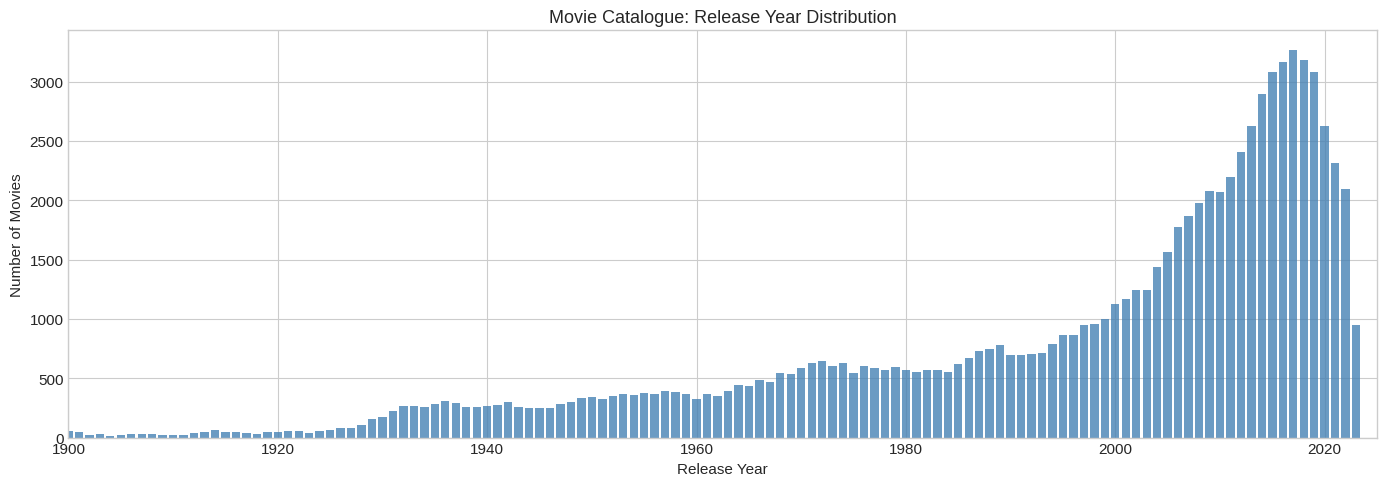

Figure saved to /content/drive/MyDrive/CineMatrix/outputs/figures/release_year_distribution.png


In [15]:
# Release year distribution plot
fig, ax = plt.subplots(figsize=(14, 5))
year_counts = movies_with_year['year'].value_counts().sort_index()
ax.bar(year_counts.index.astype(int), year_counts.values, width=0.8, alpha=0.8, color='steelblue')
ax.set_xlabel('Release Year')
ax.set_ylabel('Number of Movies')
ax.set_title('Movie Catalogue: Release Year Distribution')
ax.set_xlim(1900, 2025)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'release_year_distribution.png')
plt.show()
print(f"Figure saved to {FIGURES_DIR / 'release_year_distribution.png'}")

In [16]:
# Genre analysis
# Split multi-genre records using pipe separator
all_genres = movies['genres'].str.split('|')
genre_exploded = all_genres.explode()

# Identify placeholder
n_no_genre = (genre_exploded == '(no genres listed)').sum()
print(f"Records with '(no genres listed)': {n_no_genre:,}")
print(f"Movies with '(no genres listed)': {(movies['genres'] == '(no genres listed)').sum():,}")

# Actual genres (excluding placeholder)
actual_genres = genre_exploded[genre_exploded != '(no genres listed)']
unique_genres = sorted(actual_genres.unique())
print(f"\nUnique actual genres: {len(unique_genres)}")
print(f"Genres: {unique_genres}")

# Genre frequency
genre_freq = actual_genres.value_counts()
print(f"\nGenre frequency (top 10):")
print(genre_freq.head(10).to_string())

Records with '(no genres listed)': 7,080
Movies with '(no genres listed)': 7,080

Unique actual genres: 19
Genres: ['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']

Genre frequency (top 10):
genres
Drama          34175
Comedy         23124
Thriller       11823
Romance        10369
Action          9668
Documentary     9363
Horror          8654
Crime           6976
Adventure       5402
Sci-Fi          4907


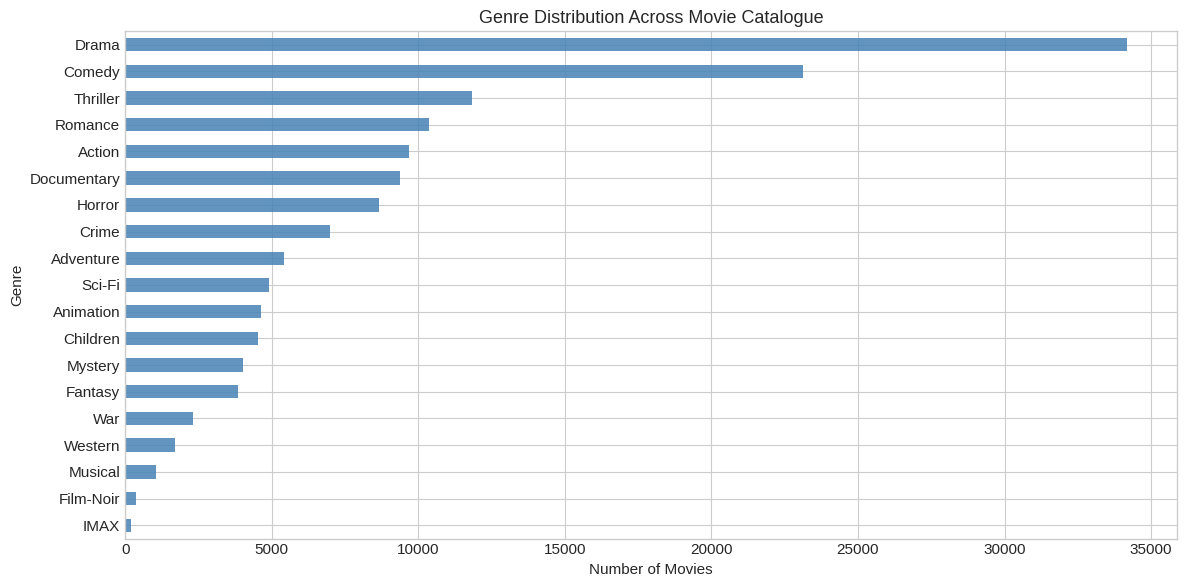

In [17]:
# Genre distribution plot
fig, ax = plt.subplots(figsize=(12, 6))
genre_freq.plot(kind='barh', ax=ax, color='steelblue', alpha=0.85)
ax.set_xlabel('Number of Movies')
ax.set_ylabel('Genre')
ax.set_title('Genre Distribution Across Movie Catalogue')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'genre_distribution.png')
plt.show()

In [18]:
# Multi-genre analysis
n_genres_per_movie = movies['genres'].apply(
    lambda x: len(x.split('|')) if x != '(no genres listed)' else 0
)
print("Genres per movie:")
print(n_genres_per_movie.describe().to_string())
print(f"\nSingle-genre movies: {(n_genres_per_movie == 1).sum():,}")
print(f"Multi-genre movies: {(n_genres_per_movie > 1).sum():,}")
print(f"No genre listed: {(n_genres_per_movie == 0).sum():,}")

# Distribution of genre count
print(f"\nDistribution of genre count per movie:")
print(n_genres_per_movie.value_counts().sort_index().to_string())

Genres per movie:
count   87585.0000
mean        1.6794
std         1.0427
min         0.0000
25%         1.0000
50%         1.0000
75%         2.0000
max        10.0000

Single-genre movies: 37,505
Multi-genre movies: 43,000
No genre listed: 7,080

Distribution of genre count per movie:
genres
0      7080
1     37505
2     25262
3     13172
4      3521
5       849
6       161
7        32
8         2
10        1


### 3.4 Rating Analysis

In [19]:
# Basic rating statistics
print("Rating Statistics:")
print(f"  Total ratings: {len(ratings):,}")
print(f"  Rating range: {ratings['rating'].min()} to {ratings['rating'].max()}")
print(f"  Mean rating: {ratings['rating'].mean():.4f}")
print(f"  Median rating: {ratings['rating'].median():.4f}")
print(f"  Std deviation: {ratings['rating'].std():.4f}")
print(f"  Unique rating values: {sorted(ratings['rating'].unique())}")

# Rating frequency
print(f"\nRating value distribution:")
rating_counts = ratings['rating'].value_counts().sort_index()
rating_pct = (rating_counts / len(ratings) * 100).round(2)
for val, cnt in rating_counts.items():
    print(f"  {val:.1f}: {cnt:>10,} ({rating_pct[val]:>5.2f}%)")

Rating Statistics:
  Total ratings: 32,000,204
  Rating range: 0.5 to 5.0
  Mean rating: 3.5404
  Median rating: 3.5000
  Std deviation: 1.0861
  Unique rating values: [np.float32(0.5), np.float32(1.0), np.float32(1.5), np.float32(2.0), np.float32(2.5), np.float32(3.0), np.float32(3.5), np.float32(4.0), np.float32(4.5), np.float32(5.0)]

Rating value distribution:
  0.5:    525,132 ( 1.64%)
  1.0:    946,675 ( 2.96%)
  1.5:    531,063 ( 1.66%)
  2.0:  2,028,622 ( 6.34%)
  2.5:  1,685,386 ( 5.27%)
  3.0:  6,054,990 (18.92%)
  3.5:  4,290,105 (13.41%)
  4.0:  8,367,654 (26.15%)
  4.5:  2,974,000 ( 9.29%)
  5.0:  4,596,577 (14.36%)


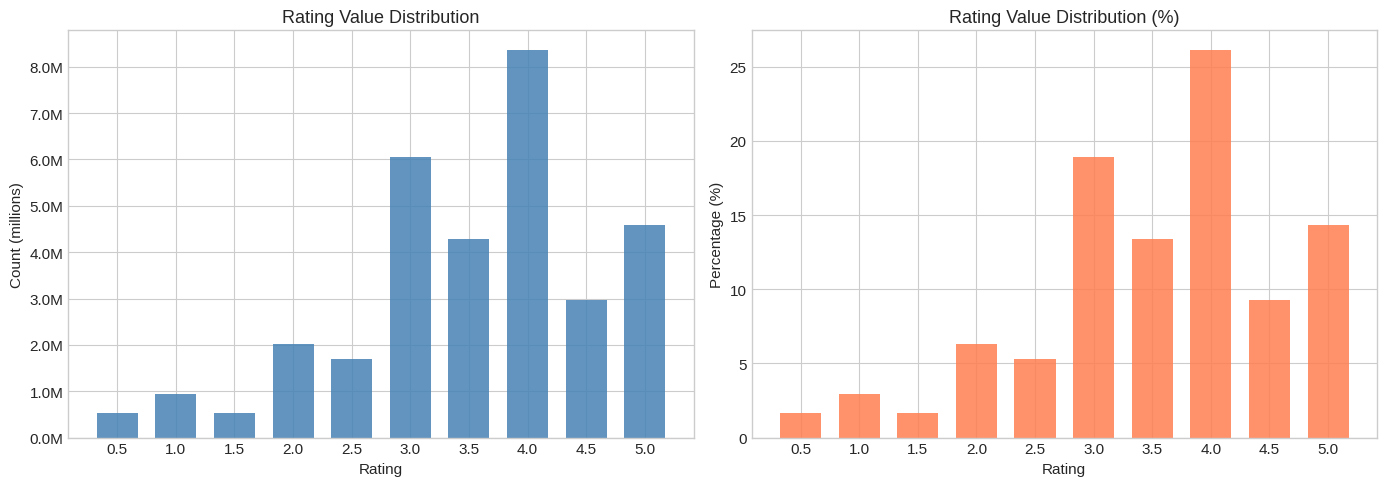

In [20]:
# Rating distribution plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].bar(rating_counts.index, rating_counts.values, width=0.35, color='steelblue', alpha=0.85)
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Count (millions)')
axes[0].set_title('Rating Value Distribution')
axes[0].set_xticks(rating_counts.index)
# Format y-axis in millions
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))

# Percentage
axes[1].bar(rating_pct.index, rating_pct.values, width=0.35, color='coral', alpha=0.85)
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_title('Rating Value Distribution (%)')
axes[1].set_xticks(rating_pct.index)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'rating_distribution.png')
plt.show()

In [21]:
# Ratings per user
ratings_per_user = ratings.groupby('userId').size()
print("Ratings per user:")
print(ratings_per_user.describe().to_string())
print(f"\nUsers with ≥100 ratings: {(ratings_per_user >= 100).sum():,}")
print(f"Users with ≥1000 ratings: {(ratings_per_user >= 1000).sum():,}")
print(f"Users with <10 ratings: {(ratings_per_user < 10).sum():,}")

Ratings per user:
count   200948.0000
mean       159.2462
std        282.0255
min         20.0000
25%         36.0000
50%         73.0000
75%        167.0000
max      33332.0000

Users with ≥100 ratings: 80,675
Users with ≥1000 ratings: 3,621
Users with <10 ratings: 0


In [22]:
# Ratings per movie
ratings_per_movie = ratings.groupby('movieId').size()
print("Ratings per movie:")
print(ratings_per_movie.describe().to_string())
print(f"\nMovies with ≥100 ratings: {(ratings_per_movie >= 100).sum():,}")
print(f"Movies with ≥1000 ratings: {(ratings_per_movie >= 1000).sum():,}")
print(f"Movies with <10 ratings: {(ratings_per_movie < 10).sum():,}")

Ratings per movie:
count    84432.0000
mean       379.0056
std       2592.4398
min          1.0000
25%          2.0000
50%          5.0000
75%         25.0000
max     102929.0000

Movies with ≥100 ratings: 12,191
Movies with ≥1000 ratings: 4,397
Movies with <10 ratings: 52,471


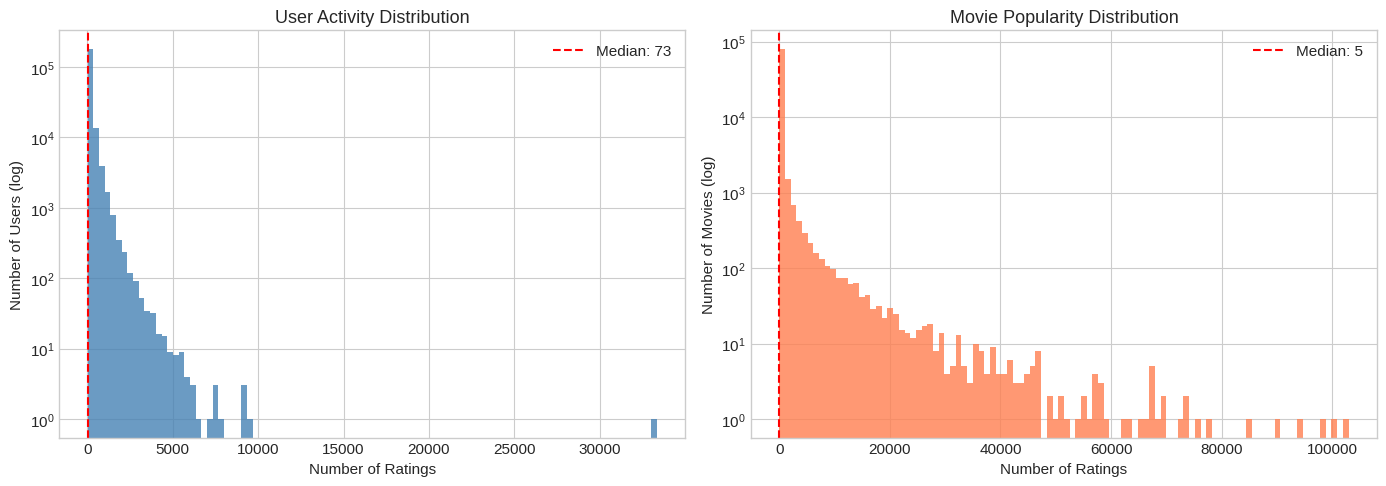

In [23]:
# User activity and movie popularity concentration
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# User activity (log scale)
axes[0].hist(ratings_per_user.values, bins=100, color='steelblue', alpha=0.8, log=True)
axes[0].set_xlabel('Number of Ratings')
axes[0].set_ylabel('Number of Users (log)')
axes[0].set_title('User Activity Distribution')
axes[0].axvline(ratings_per_user.median(), color='red', linestyle='--', label=f'Median: {ratings_per_user.median():.0f}')
axes[0].legend()

# Movie popularity (log scale)
axes[1].hist(ratings_per_movie.values, bins=100, color='coral', alpha=0.8, log=True)
axes[1].set_xlabel('Number of Ratings')
axes[1].set_ylabel('Number of Movies (log)')
axes[1].set_title('Movie Popularity Distribution')
axes[1].axvline(ratings_per_movie.median(), color='red', linestyle='--', label=f'Median: {ratings_per_movie.median():.0f}')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'activity_distribution.png')
plt.show()

Rating time span: 1995-01 to 2023-10
Total months of activity: 334


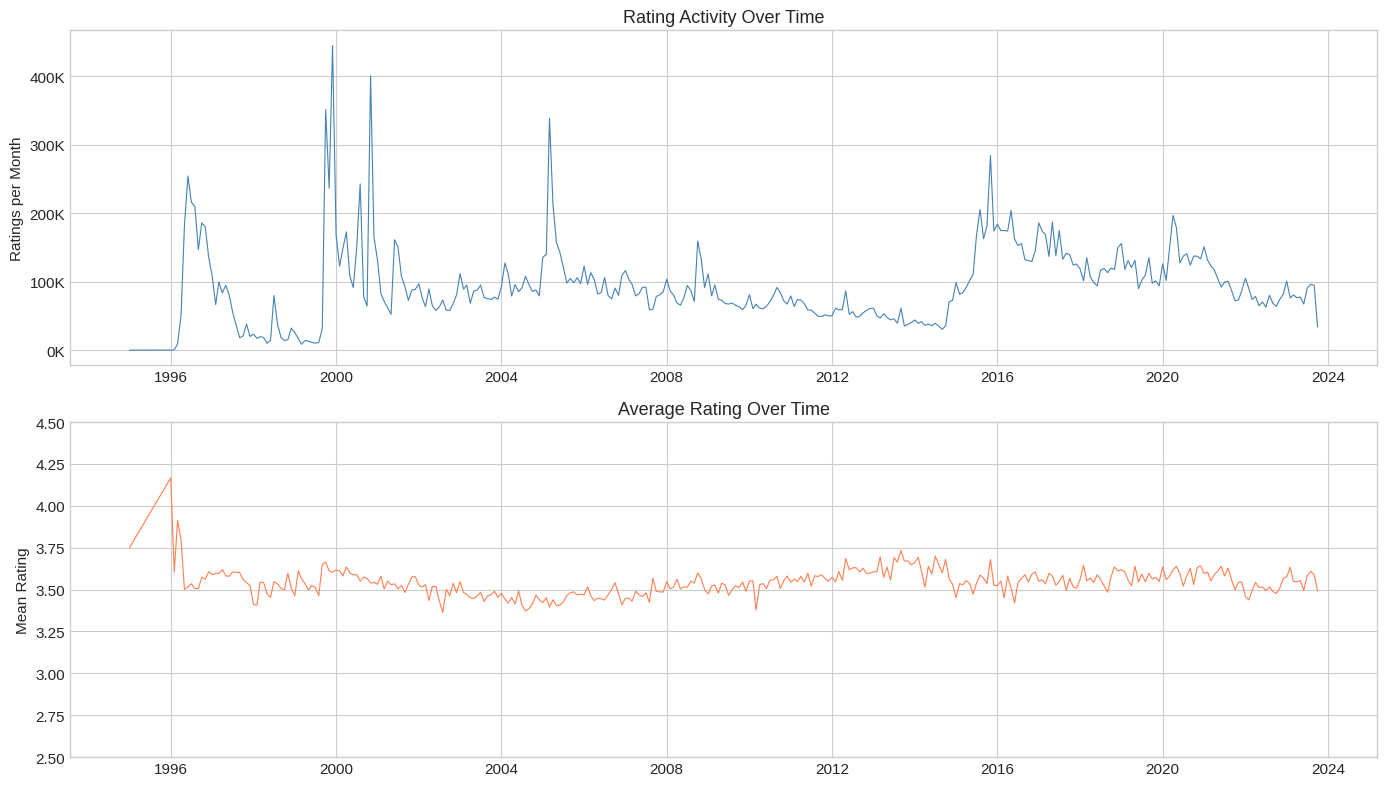

43230

In [24]:
# Rating activity over time
ratings['datetime'] = pd.to_datetime(ratings['timestamp'], unit='s')
ratings['year_month'] = ratings['datetime'].dt.to_period('M')

# Monthly rating counts (use a sample for efficiency in plotting)
monthly_counts = ratings.groupby('year_month').size()
print(f"Rating time span: {monthly_counts.index.min()} to {monthly_counts.index.max()}")
print(f"Total months of activity: {len(monthly_counts)}")

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Monthly rating volume
x_dates = monthly_counts.index.to_timestamp()
axes[0].plot(x_dates, monthly_counts.values, linewidth=0.8, color='steelblue')
axes[0].set_ylabel('Ratings per Month')
axes[0].set_title('Rating Activity Over Time')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K'))

# Monthly average rating
monthly_mean = ratings.groupby('year_month')['rating'].mean()
x_dates_mean = monthly_mean.index.to_timestamp()
axes[1].plot(x_dates_mean, monthly_mean.values, linewidth=0.8, color='coral')
axes[1].set_ylabel('Mean Rating')
axes[1].set_title('Average Rating Over Time')
axes[1].set_ylim(2.5, 4.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'rating_trends.png')
plt.show()

# Clean up temporary columns to save memory
ratings.drop(columns=['datetime', 'year_month'], inplace=True)
gc.collect()

### 3.5 Tag Analysis

In [25]:
# Tag overview
print("Tag Dataset Overview:")
print(f"  Total tag records: {len(tags):,}")
print(f"  Unique raw tags: {tags['tag'].nunique():,}")
print(f"  Unique tag contributors: {tags['userId'].nunique():,}")
print(f"  Movies receiving tags: {tags['movieId'].nunique():,}")

# Missing tags
print(f"\n  Null tag values: {tags['tag'].isnull().sum():,}")

# Check for literal 'NA', 'null', 'None' strings
for val in ['NA', 'na', 'null', 'NULL', 'None', 'none', '']:
    count = (tags['tag'] == val).sum()
    if count > 0:
        print(f"  Tags with literal '{val}': {count:,}")

Tag Dataset Overview:
  Total tag records: 2,000,072
  Unique raw tags: 140,981
  Unique tag contributors: 15,848
  Movies receiving tags: 51,323

  Null tag values: 0
  Tags with literal 'NA': 16
  Tags with literal 'null': 1


In [26]:
# Tag normalization analysis
# Create normalized version (lowercase, stripped) WITHOUT modifying original
tags_normalized = tags['tag'].dropna().str.strip().str.lower()
print(f"Unique tags before normalization: {tags['tag'].nunique():,}")
print(f"Unique tags after case+whitespace normalization: {tags_normalized.nunique():,}")
print(f"Reduction: {tags['tag'].nunique() - tags_normalized.nunique():,} unique values collapsed")

# Most frequent tags (normalized)
print(f"\nTop 20 most frequent tags (normalized):")
tag_freq = tags_normalized.value_counts()
print(tag_freq.head(20).to_string())

Unique tags before normalization: 140,981
Unique tags after case+whitespace normalization: 131,646
Reduction: 9,335 unique values collapsed

Top 20 most frequent tags (normalized):
tag
sci-fi                11457
atmospheric           10088
action                 9344
comedy                 9275
funny                  8088
surreal                7480
visually appealing     7253
based on a book        6733
twist ending           6600
romance                6229
dark comedy            6153
thought-provoking      6003
dystopia               5713
violence               5483
cinematography         5429
murder                 5238
social commentary      5201
fantasy                5154
thriller               5050
quirky                 4954


In [27]:
# Tag length distribution
tag_lengths = tags['tag'].dropna().str.len()
print("Tag length statistics:")
print(tag_lengths.describe().to_string())
print(f"\nTags with length > 100: {(tag_lengths > 100).sum():,}")
print(f"Tags with length > 200: {(tag_lengths > 200).sum():,}")

# Non-ASCII analysis
has_non_ascii = tags['tag'].dropna().apply(lambda x: not x.isascii())
print(f"\nTags containing non-ASCII characters: {has_non_ascii.sum():,}")

Tag length statistics:
count   2000072.0000
mean         11.1102
std           5.7182
min           1.0000
25%           7.0000
50%          10.0000
75%          14.0000
max         241.0000

Tags with length > 100: 89
Tags with length > 200: 16

Tags containing non-ASCII characters: 2,354


In [28]:
# Tag contributor concentration
tags_per_user = tags.groupby('userId').size().sort_values(ascending=False)
print("Tags per contributor:")
print(tags_per_user.describe().to_string())
print(f"\nTop 5 contributors (tag count):")
print(tags_per_user.head(5).to_string())

# Percentage of tags from top contributors
top10_pct = tags_per_user.head(10).sum() / len(tags) * 100
top50_pct = tags_per_user.head(50).sum() / len(tags) * 100
print(f"\nTop 10 contributors account for: {top10_pct:.1f}% of all tags")
print(f"Top 50 contributors account for: {top50_pct:.1f}% of all tags")

Tags per contributor:
count    15848.0000
mean       126.2034
std       5770.0896
min          1.0000
25%          2.0000
50%          5.0000
75%         25.0000
max     723473.0000

Top 5 contributors (tag count):
userId
78213     723473
119227     20369
68821      20317
147560     18849
159300     16843

Top 10 contributors account for: 43.2% of all tags
Top 50 contributors account for: 54.3% of all tags


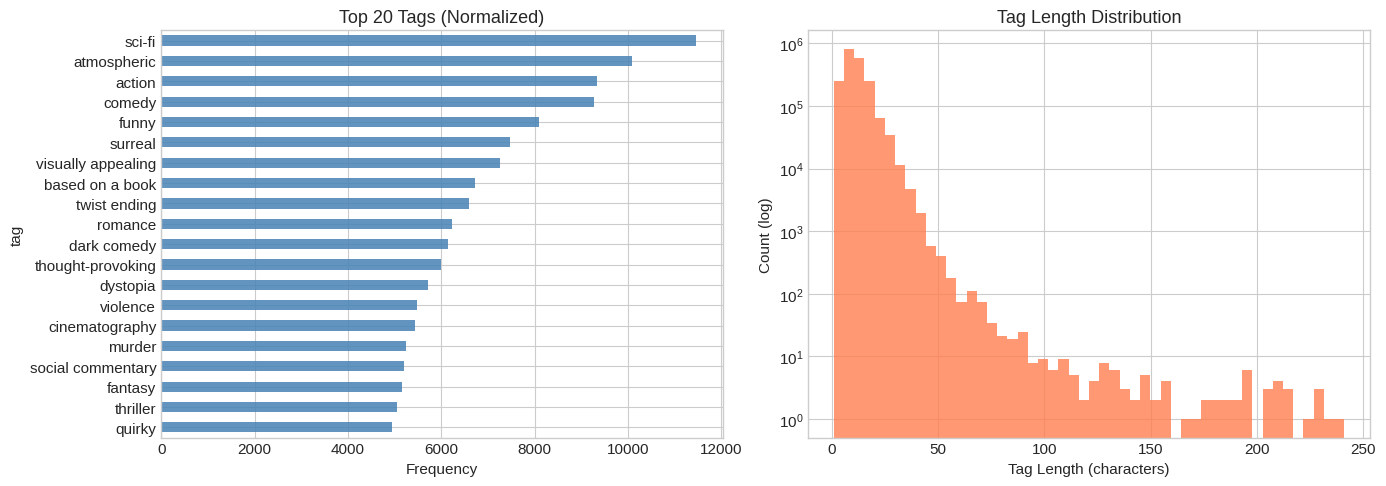

In [29]:
# Tag frequency visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top 20 tags
tag_freq.head(20).plot(kind='barh', ax=axes[0], color='steelblue', alpha=0.85)
axes[0].set_xlabel('Frequency')
axes[0].set_title('Top 20 Tags (Normalized)')
axes[0].invert_yaxis()

# Tag length distribution
axes[1].hist(tag_lengths.values, bins=50, color='coral', alpha=0.8, log=True)
axes[1].set_xlabel('Tag Length (characters)')
axes[1].set_ylabel('Count (log)')
axes[1].set_title('Tag Length Distribution')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'tag_analysis.png')
plt.show()

### 3.6 Dataset Findings Summary

**Data Quality:**
- All four datasets load cleanly with expected dimensions.
- Referential integrity is maintained — all rated/tagged movieIds exist in the movie catalogue.
- No duplicate (userId, movieId) pairs in ratings.
- No duplicate movieIds in the movie catalogue.

**Key Observations for Modelling:**
- **Extreme sparsity:** With ~200K users and ~84K rated movies, the user-item interaction matrix is approximately 99.8% sparse. This necessitates sparse representations and algorithms designed for sparse data.
- **Long-tail distributions:** Both user activity and movie popularity follow heavy-tailed distributions. A small fraction of movies receive the majority of ratings, while most movies have few interactions.
- **Genre coverage:** 19 distinct genres (the placeholder `(no genres listed)` is treated as missing metadata, not as a genre) with extensive multi-labelling provide useful content features.
- **Rich tag vocabulary:** ~2M tag records provide fine-grained content signals, though tag contributions are concentrated among a small number of users.
- **Temporal span:** Nearly 30 years of ratings enable meaningful temporal evaluation.
- **Positive-skew in ratings:** Mean ~3.54 with positive skew indicates users tend to rate movies they at least somewhat enjoyed.

**Limitations:**
- Self-selection bias: Users choose which movies to rate, so missing ratings are not missing-at-random.
- Tag contributor concentration: A small group of power users contributes disproportionately to tags.
- 3,153 movies have zero ratings but do have tags — these are relevant for cold-start experiments.


---

## 4. Data Cleaning and Preprocessing

Applying only justified transformations. All changes are documented and validated. Original data is preserved.

### 4.1 Movie Preprocessing

In [30]:
# Movie preprocessing
print("=== Movie Preprocessing ===\n")

# Preserve original title and genres
movies['original_title'] = movies['title']
movies['original_genres'] = movies['genres']

# Extract release year (already done in EDA - verify)
if 'year' not in movies.columns:
    movies['year'] = movies['title'].str.extract(r'\((\d{4})\)\s*$').astype('Int64')

# Validate year range
valid_year_mask = movies['year'].between(1888, 2025) | movies['year'].isna()
invalid_years = movies[~valid_year_mask]
print(f"Movies with invalid years (outside 1888-2025): {len(invalid_years)}")
if len(invalid_years) > 0:
    print(invalid_years[['movieId', 'title', 'year']].head())

# Clean title: remove year suffix for display
movies['clean_title'] = movies['title'].str.replace(r'\s*\(\d{4}\)\s*$', '', regex=True).str.strip()

# Split genres into list
movies['genre_list'] = movies['genres'].apply(
    lambda x: x.split('|') if x != '(no genres listed)' else []
)
movies['n_genres'] = movies['genre_list'].apply(len)

# Mark movies with no genre info
movies['has_genres'] = movies['genres'] != '(no genres listed)'

print(f"Movies with valid genres: {movies['has_genres'].sum():,}")
print(f"Movies without genre info: {(~movies['has_genres']).sum():,}")

# Validate movieId uniqueness
assert movies['movieId'].is_unique, "Duplicate movieIds found!"
print(f"\nMovieId uniqueness verified: {movies['movieId'].nunique():,} unique IDs")

print(f"\nMovie columns after preprocessing: {movies.columns.tolist()}")
movies.head(3)

=== Movie Preprocessing ===

Movies with invalid years (outside 1888-2025): 11
       movieId                               title  year
35822   148040  Man Walking Around a Corner (1887)  1887
35826   148048   Sallie Gardner at a Gallop (1878)  1878
35829   148054             Passage de Venus (1874)  1874
44258   166800              Buffalo Running (1883)  1883
60912   202045      Athlete Swinging a Pick (1880)  1880
Movies with valid genres: 80,505
Movies without genre info: 7,080

MovieId uniqueness verified: 87,585 unique IDs

Movie columns after preprocessing: ['movieId', 'title', 'genres', 'year', 'original_title', 'original_genres', 'clean_title', 'genre_list', 'n_genres', 'has_genres']


,movieId,title,genres,year,original_title,original_genres,clean_title,genre_list,n_genres,has_genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,Toy Story,"[Adventure, Animation, Children, Comedy, Fantasy]",5,True
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,Jumanji (1995),Adventure|Children|Fantasy,Jumanji,"[Adventure, Children, Fantasy]",3,True
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,Grumpier Old Men (1995),Comedy|Romance,Grumpier Old Men,"[Comedy, Romance]",2,True


### 4.2 Rating Preprocessing

In [31]:
# Rating preprocessing
print("=== Rating Preprocessing ===\n")

# Validate rating range
valid_ratings = ratings['rating'].between(0.5, 5.0)
print(f"Ratings in valid range [0.5, 5.0]: {valid_ratings.sum():,} / {len(ratings):,}")
assert valid_ratings.all(), "Found ratings outside valid range!"

# Validate rating increments (should be 0.5 steps)
valid_increments = (ratings['rating'] * 2) % 1 == 0
print(f"Ratings at valid 0.5 increments: {valid_increments.sum():,} / {len(ratings):,}")

# Validate timestamps
min_ts = ratings['timestamp'].min()
max_ts = ratings['timestamp'].max()
print(f"Timestamp range: {pd.Timestamp(min_ts, unit='s')} to {pd.Timestamp(max_ts, unit='s')}")

# Check for duplicate user-movie pairs
dup_pairs = ratings.duplicated(subset=['userId', 'movieId']).sum()
print(f"Duplicate (userId, movieId) pairs: {dup_pairs:,}")

# Create binary relevance indicator
ratings['relevant'] = (ratings['rating'] >= RELEVANCE_THRESHOLD).astype('int8')
print(f"\nRelevance threshold: {RELEVANCE_THRESHOLD}")
print(f"Relevant ratings (>= {RELEVANCE_THRESHOLD}): {ratings['relevant'].sum():,} ({ratings['relevant'].mean()*100:.1f}%)")
print(f"Non-relevant ratings: {(1 - ratings['relevant']).sum():,}")

print(f"\nRating columns after preprocessing: {ratings.columns.tolist()}")
print(f"Memory usage: {ratings.memory_usage(deep=True).sum() / 1e6:.1f} MB")

=== Rating Preprocessing ===

Ratings in valid range [0.5, 5.0]: 32,000,204 / 32,000,204
Ratings at valid 0.5 increments: 32,000,204 / 32,000,204
Timestamp range: 1995-01-09 11:46:44 to 2023-10-13 02:29:07
Duplicate (userId, movieId) pairs: 0

Relevance threshold: 4.0
Relevant ratings (>= 4.0): 15,938,231 (49.8%)
Non-relevant ratings: 16,061,973

Rating columns after preprocessing: ['userId', 'movieId', 'rating', 'timestamp', 'relevant']
Memory usage: 672.0 MB


### 4.3 Tag Preprocessing

In [32]:
# Tag preprocessing with raw-value preservation
print("=== Tag Preprocessing ===\n")

# Preserve original tag strings exactly as loaded
tags['original_tag'] = tags['tag']

# Validate raw values: verify that keep_default_na=False prevented silent deletion
n_literal_na = (tags['original_tag'] == 'NA').sum()
n_literal_null = (tags['original_tag'] == 'null').sum()
n_empty = (tags['original_tag'] == '').sum()
print(f"Total tag records: {len(tags):,}")
print(f"Preserved literal 'NA' tags: {n_literal_na:,}")
print(f"Preserved literal 'null' tags: {n_literal_null:,}")
print(f"Empty string tags: {n_empty:,}")

# Distinguish genuine missing from literal strings:
tags['is_literal_na_string'] = tags['original_tag'].isin(['NA', 'na', 'null', 'NULL', 'None', 'none', 'n/a'])
print(f"Tags with literal NA-like values (preserved): {tags['is_literal_na_string'].sum():,}")

# Controlled normalization: strip whitespace and lowercase for modeling
tags['tag_normalized'] = tags['original_tag'].str.strip().str.lower()

# Verify no non-empty tag collapsed to empty string
collapsed = (tags['original_tag'] != '') & (tags['tag_normalized'] == '')
print(f"Whitespace-only tags that collapsed: {collapsed.sum():,}")

print(f"\nUnique raw tags: {tags['original_tag'].nunique():,}")
print(f"Unique normalized tags: {tags['tag_normalized'].nunique():,}")

# Non-ASCII validation (preserved legitimately for international cinema)
has_non_ascii = tags['tag_normalized'].apply(lambda x: not x.isascii())
print(f"Tags with non-ASCII characters: {has_non_ascii.sum():,} (preserved)")

print(f"\nTag columns after preprocessing: {tags.columns.tolist()}")

=== Tag Preprocessing ===

Total tag records: 2,000,072
Preserved literal 'NA' tags: 16
Preserved literal 'null' tags: 1
Empty string tags: 0
Tags with literal NA-like values (preserved): 17
Whitespace-only tags that collapsed: 6

Unique raw tags: 140,981
Unique normalized tags: 131,646
Tags with non-ASCII characters: 2,263 (preserved)

Tag columns after preprocessing: ['userId', 'movieId', 'tag', 'timestamp', 'original_tag', 'is_literal_na_string', 'tag_normalized']


### 4.4 Links Preprocessing

In [33]:
# Links preprocessing and IMDb leading-zero validation
print("=== Links Preprocessing ===\n")

# Verify IMDb IDs are loaded as strings and leading zeroes are preserved
assert pd.api.types.is_string_dtype(links['imdbId']), "imdbId is not a string dtype!"
leading_zero_count = int(links['imdbId'].str.startswith('0').sum())
print(f"IMDb IDs with leading zeroes: {leading_zero_count:,} / {len(links):,}")
assert leading_zero_count == 46596, f"Expected 46,596 leading zeroes, got {leading_zero_count}"
print("✓ Leading zeroes verified and preserved from raw CSV.")

# Handle missing TMDB IDs with nullable Int64
n_missing_tmdb = links['tmdbId'].isna().sum()
n_valid_tmdb = links['tmdbId'].notna().sum()
print(f"Valid TMDB IDs: {n_valid_tmdb:,}")
print(f"Missing TMDB IDs: {n_missing_tmdb:,} (kept as nullable Int64)")

# Verify referential integrity with movie catalogue
print(f"\nMovies in links: {links['movieId'].nunique():,}")
print(f"Movies in catalogue: {movies['movieId'].nunique():,}")
assert set(links['movieId']) == set(movies['movieId']), "Mismatch between links and movies catalogue!"

print(f"\nLinks columns after preprocessing: {links.columns.tolist()}")
links.head(3)

=== Links Preprocessing ===

IMDb IDs with leading zeroes: 46,596 / 87,585
✓ Leading zeroes verified and preserved from raw CSV.
Valid TMDB IDs: 87,461
Missing TMDB IDs: 124 (kept as nullable Int64)

Movies in links: 87,585
Movies in catalogue: 87,585

Links columns after preprocessing: ['movieId', 'imdbId', 'tmdbId']


,movieId,imdbId,tmdbId
0,1,0114709,862
1,2,0113497,8844
2,3,0113228,15602


### 4.5 Save Preprocessed Artifacts

In [34]:
# Save preprocessed movies (small enough to save directly)
movies.to_parquet(DATA_PROCESSED / 'movies_processed.parquet', index=False)
print(f"Saved processed movies: {DATA_PROCESSED / 'movies_processed.parquet'}")

# Save tags with normalized versions
tags.to_parquet(DATA_PROCESSED / 'tags_processed.parquet', index=False)
print(f"Saved processed tags: {DATA_PROCESSED / 'tags_processed.parquet'}")

# Save links
links.to_parquet(DATA_PROCESSED / 'links_processed.parquet', index=False)
print(f"Saved processed links: {DATA_PROCESSED / 'links_processed.parquet'}")

# For ratings, save the relevance column mapping rather than the full 32M-row file
# The binary relevance can be reconstructed from the threshold
print(f"\nRatings: relevance column added in-memory (threshold={RELEVANCE_THRESHOLD})")
print("Preprocessing complete.")

Saved processed movies: /content/drive/MyDrive/CineMatrix/data/processed/movies_processed.parquet
Saved processed tags: /content/drive/MyDrive/CineMatrix/data/processed/tags_processed.parquet
Saved processed links: /content/drive/MyDrive/CineMatrix/data/processed/links_processed.parquet

Ratings: relevance column added in-memory (threshold=4.0)
Preprocessing complete.


---

## 5. Feature Engineering

Building movie-level content features for content-based recommendation.

### 5.1 Genre Features (Multi-Hot Encoding)

In [35]:
# Genre multi-hot encoding using sparse representation
print("=== Genre Feature Engineering ===\n")

# Get all actual genres (exclude placeholder)
all_genre_lists = movies[movies['has_genres']]['genre_list'].tolist()
mlb = MultiLabelBinarizer()
genre_matrix_dense = mlb.fit_transform(all_genre_lists)

print(f"Genre labels: {mlb.classes_.tolist()}")
print(f"Number of genres: {len(mlb.classes_)}")

# Create for ALL movies (including those without genres — they get zero vectors)
genre_matrix_all = mlb.transform(movies['genre_list'].tolist())

# Convert to sparse
genre_sparse = csr_matrix(genre_matrix_all, dtype=np.float32)
print(f"Genre matrix shape: {genre_sparse.shape}")
print(f"Genre matrix density: {genre_sparse.nnz / (genre_sparse.shape[0] * genre_sparse.shape[1]):.4f}")
print(f"Memory (sparse): {(genre_sparse.data.nbytes + genre_sparse.indices.nbytes + genre_sparse.indptr.nbytes) / 1e3:.1f} KB")

# Create movieId to matrix index mapping
movie_id_to_idx = {mid: idx for idx, mid in enumerate(movies['movieId'].values)}
idx_to_movie_id = {idx: mid for mid, idx in movie_id_to_idx.items()}

print(f"MovieId-to-index mapping: {len(movie_id_to_idx):,} entries")

# Verify: check a known movie
test_mid = 1  # Toy Story
test_idx = movie_id_to_idx[test_mid]
test_genres = [mlb.classes_[i] for i in genre_sparse[test_idx].nonzero()[1]]
print(f"\nVerification — Movie {test_mid} ({movies.loc[movies['movieId']==test_mid, 'title'].values[0]}):")
print(f"  Genres: {test_genres}")

=== Genre Feature Engineering ===

Genre labels: ['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
Number of genres: 19
Genre matrix shape: (87585, 19)
Genre matrix density: 0.0884
Memory (sparse): 1527.1 KB
MovieId-to-index mapping: 87,585 entries

Verification — Movie 1 (Toy Story (1995)):
  Genres: ['Adventure', 'Animation', 'Children', 'Comedy', 'Fantasy']


### 5.2 Tag TF-IDF Features

In [36]:
# Tag TF-IDF feature engineering with strict temporal leakage prevention
print("=== Tag TF-IDF Feature Engineering (Temporal Leakage Prevention) ===\n")

# 1. Establish temporal cutoff from ratings timeline (80% quantile)
train_cutoff_ts = float(ratings['timestamp'].quantile(0.80))
train_cutoff_date = pd.Timestamp(train_cutoff_ts, unit='s')
print(f"Primary Temporal Boundary: {train_cutoff_date} (ts: {train_cutoff_ts:.0f})")

# 2. Strict partitioning of tags: only tags contributed on or before train_cutoff_ts
train_tags = tags[tags['timestamp'] <= train_cutoff_ts].copy()
future_tags = tags[tags['timestamp'] > train_cutoff_ts].copy()

print(f"Total tag records: {len(tags):,}")
print(f"Historical training tags (<= cutoff): {len(train_tags):,} ({len(train_tags)/len(tags)*100:.1f}%)")
print(f"Future tags excluded from training features: {len(future_tags):,} ({len(future_tags)/len(tags)*100:.1f}%)")

# Confirm strict temporal boundary
assert train_tags['timestamp'].max() <= train_cutoff_ts, "Temporal leakage in tags!"
print("✓ Zero tag temporal leakage verified: max training tag timestamp <= train cutoff.")

# 3. Aggregate training tags at movie level
movie_tags_train = train_tags.groupby('movieId')['tag_normalized'].apply(
    lambda x: ' '.join(x)
).reset_index()
movie_tags_train.columns = ['movieId', 'tag_text']

# Align with entire movie catalogue (movies without training tags get empty string)
movie_tag_train_df = movies[['movieId']].merge(movie_tags_train, on='movieId', how='left')
movie_tag_train_df['tag_text'] = movie_tag_train_df['tag_text'].fillna('')
assert (movie_tag_train_df['movieId'] == movies['movieId']).all()

print(f"Movies with training tags: {len(movie_tags_train):,} / {len(movies):,}")

# 4. Fit TF-IDF on historical training tags only
MAX_TAG_FEATURES = 5000
tfidf_train = TfidfVectorizer(
    max_features=MAX_TAG_FEATURES,
    min_df=3,
    max_df=0.5,
    sublinear_tf=True,
    norm='l2',
    dtype=np.float32
)

tag_tfidf_matrix = tfidf_train.fit_transform(movie_tag_train_df['tag_text'])
print(f"\nPrimary (Leakage-Free) Tag TF-IDF matrix shape: {tag_tfidf_matrix.shape}")
print(f"Vocabulary size: {len(tfidf_train.vocabulary_):,}")
print(f"Non-zero entries: {tag_tfidf_matrix.nnz:,}")
mem_mb = (tag_tfidf_matrix.data.nbytes + tag_tfidf_matrix.indices.nbytes + tag_tfidf_matrix.indptr.nbytes) / 1e6
print(f"Memory (sparse CSR): {mem_mb:.2f} MB")

# 5. Distinct Secondary Artifact: Full-catalogue metadata (clearly distinguished for offline demo only)
movie_tags_full = tags.groupby('movieId')['tag_normalized'].apply(lambda x: ' '.join(x)).reset_index()
movie_tag_full_df = movies[['movieId']].merge(movie_tags_full, on='movieId', how='left')
movie_tag_full_df['tag_text'] = movie_tag_full_df['tag_normalized'].fillna('')

tfidf_full = TfidfVectorizer(max_features=MAX_TAG_FEATURES, min_df=3, max_df=0.5, sublinear_tf=True, norm='l2', dtype=np.float32)
tag_tfidf_matrix_full = tfidf_full.fit_transform(movie_tag_full_df['tag_text'])
print(f"\n[Secondary] Full-Catalogue Tag TF-IDF matrix shape: {tag_tfidf_matrix_full.shape} (for offline demo only)")

=== Tag TF-IDF Feature Engineering (Temporal Leakage Prevention) ===

Primary Temporal Boundary: 2018-10-03 07:21:42 (ts: 1538551302)
Total tag records: 2,000,072
Historical training tags (<= cutoff): 893,500 (44.7%)
Future tags excluded from training features: 1,106,572 (55.3%)
✓ Zero tag temporal leakage verified: max training tag timestamp <= train cutoff.
Movies with training tags: 42,473 / 87,585

Primary (Leakage-Free) Tag TF-IDF matrix shape: (87585, 5000)
Vocabulary size: 5,000
Non-zero entries: 514,870
Memory (sparse CSR): 4.47 MB

[Secondary] Full-Catalogue Tag TF-IDF matrix shape: (87585, 5000) (for offline demo only)


### 5.3 Combined Content Representation

In [37]:
# Combined Content Representation
from sklearn.preprocessing import normalize as sk_normalize
from scipy.sparse import hstack

# Normalize genre features to L2
genre_normalized = sk_normalize(genre_sparse.astype(np.float32), norm='l2')

# Primary leakage-free content matrix: genre + training tag TF-IDF
content_matrix = hstack([genre_normalized, tag_tfidf_matrix], format='csr')

# Distinct full-catalogue content matrix (contains future tags, used ONLY for qualitative item-item demos)
content_matrix_full = hstack([genre_normalized, tag_tfidf_matrix_full], format='csr')

print("=== Primary Content Matrix (Leakage-Free) ===")
print(f"Shape: {content_matrix.shape}")
print(f"Genre features: {genre_sparse.shape[1]}")
print(f"Training tag features: {tag_tfidf_matrix.shape[1]}")
print(f"Total features: {content_matrix.shape[1]}")
print(f"Non-zeros: {content_matrix.nnz:,}")
print(f"Density: {content_matrix.nnz / (content_matrix.shape[0] * content_matrix.shape[1]):.6f}")

# Save primary and secondary artifacts
sp.save_npz(DATA_PROCESSED / 'content_matrix.npz', content_matrix)
sp.save_npz(DATA_PROCESSED / 'content_matrix_full.npz', content_matrix_full)
np.save(DATA_PROCESSED / 'movie_id_to_idx.npy', movie_id_to_idx)
print("\nSaved primary content_matrix.npz and secondary content_matrix_full.npz.")

=== Primary Content Matrix (Leakage-Free) ===
Shape: (87585, 5019)
Genre features: 19
Training tag features: 5000
Total features: 5019
Non-zeros: 661,960
Density: 0.001506

Saved primary content_matrix.npz and secondary content_matrix_full.npz.


---

## 6. Experimental Design and Data Splitting

Using temporal evaluation: training on historical interactions, evaluating on future interactions. This mirrors how recommendation systems work in practice — we can only recommend based on past behaviour.

### Splitting Strategy

We use **global temporal splitting** based on rating timestamps:
- **Training set (~80%):** Earliest ratings up to a cutoff date
- **Validation set (~10%):** Ratings in the period after training cutoff
- **Test set (~10%):** Most recent ratings, held out for final evaluation

This avoids the information leakage inherent in random splitting, where future ratings could influence past predictions.

In [38]:
# Temporal data splitting: 80% train / 10% validation / 10% test
print("=== Temporal Data Splitting ===\n")

train_cutoff_ts = float(ratings['timestamp'].quantile(0.80))
val_cutoff_ts = float(ratings['timestamp'].quantile(0.90))

train_cutoff_date = pd.Timestamp(train_cutoff_ts, unit='s')
val_cutoff_date = pd.Timestamp(val_cutoff_ts, unit='s')
min_date = pd.Timestamp(ratings['timestamp'].min(), unit='s')
max_date = pd.Timestamp(ratings['timestamp'].max(), unit='s')

print(f"Complete timeline: {min_date.date()} to {max_date.date()}")
print(f"\nChronological Split Boundaries:")
print(f"  Training Split:   Start to {train_cutoff_date} (ts <= {train_cutoff_ts:.0f})")
print(f"  Validation Split: {train_cutoff_date} to {val_cutoff_date} ({train_cutoff_ts:.0f} < ts <= {val_cutoff_ts:.0f})")
print(f"  Test Split:       {val_cutoff_date} to {max_date} (ts > {val_cutoff_ts:.0f})")

train_mask = ratings['timestamp'] <= train_cutoff_ts
val_mask = (ratings['timestamp'] > train_cutoff_ts) & (ratings['timestamp'] <= val_cutoff_ts)
test_mask = ratings['timestamp'] > val_cutoff_ts

train_ratings = ratings[train_mask].copy()
val_ratings = ratings[val_mask].copy()
test_ratings = ratings[test_mask].copy()

total_ratings = len(ratings)
print(f"\nActual Split Proportions:")
print(f"  Training:   {len(train_ratings):>10,} ratings ({len(train_ratings)/total_ratings*100:6.2f}%)")
print(f"  Validation: {len(val_ratings):>10,} ratings ({len(val_ratings)/total_ratings*100:6.2f}%)")
print(f"  Test:       {len(test_ratings):>10,} ratings ({len(test_ratings)/total_ratings*100:6.2f}%)")
print(f"  Total:      {len(train_ratings) + len(val_ratings) + len(test_ratings):>10,} ratings")

# Verification: disjoint split index sets
assert len(set(train_ratings.index) & set(val_ratings.index)) == 0, "Train-Val overlap detected!"
assert len(set(train_ratings.index) & set(test_ratings.index)) == 0, "Train-Test overlap detected!"
assert len(set(val_ratings.index) & set(test_ratings.index)) == 0, "Val-Test overlap detected!"
print("\n✓ Disjoint temporal splits verified.")

=== Temporal Data Splitting ===

Complete timeline: 1995-01-09 to 2023-10-13

Chronological Split Boundaries:
  Training Split:   Start to 2018-10-03 07:21:42 (ts <= 1538551302)
  Validation Split: 2018-10-03 07:21:42 to 2020-11-05 19:45:34.400000095 (1538551302 < ts <= 1604605534)
  Test Split:       2020-11-05 19:45:34.400000095 to 2023-10-13 02:29:07 (ts > 1604605534)

Actual Split Proportions:
  Training:   25,600,163 ratings ( 80.00%)
  Validation:  3,200,020 ratings ( 10.00%)
  Test:        3,200,021 ratings ( 10.00%)
  Total:      32,000,204 ratings

✓ Disjoint temporal splits verified.


In [39]:
# Analyze user and item coverage across splits (Quantifying Cold-Start Prevalence)
print("=== Cross-Split Coverage and Cold-Start Analysis ===\n")

train_users = set(train_ratings['userId'].unique())
val_users = set(val_ratings['userId'].unique())
test_users = set(test_ratings['userId'].unique())

train_items = set(train_ratings['movieId'].unique())
val_items = set(val_ratings['movieId'].unique())
test_items = set(test_ratings['movieId'].unique())

print(f"Unique Users — Train: {len(train_users):,}, Val: {len(val_users):,}, Test: {len(test_users):,}")
print(f"Unique Items — Train: {len(train_items):,}, Val: {len(val_items):,}, Test: {len(test_items):,}")

# Users missing from training (cold-start users)
val_cold_users = val_users - train_users
test_cold_users = test_users - train_users
print(f"\nUsers missing from training (Cold Users):")
print(f"  Validation: {len(val_cold_users):,} / {len(val_users):,} ({len(val_cold_users)/len(val_users)*100:.1f}%)")
print(f"  Test:       {len(test_cold_users):,} / {len(test_users):,} ({len(test_cold_users)/len(test_users)*100:.1f}%)")

# Items missing from training (cold-start items)
val_cold_items = val_items - train_items
test_cold_items = test_items - train_items
print(f"\nItems missing from training (Cold Items):")
print(f"  Validation: {len(val_cold_items):,} / {len(val_items):,} ({len(val_cold_items)/len(val_items)*100:.1f}%)")
print(f"  Test:       {len(test_cold_items):,} / {len(test_items):,} ({len(test_cold_items)/len(test_items)*100:.1f}%)")

# Persistent warm users (present in train AND eval split)
val_warm_users = val_users & train_users
test_warm_users = test_users & train_users
print(f"\nWarm Users (eligible for collaborative evaluation):")
print(f"  Validation warm users: {len(val_warm_users):,} ({len(val_warm_users)/len(val_users)*100:.1f}%)")
print(f"  Test warm users:       {len(test_warm_users):,} ({len(test_warm_users)/len(test_users)*100:.1f}%)")

=== Cross-Split Coverage and Cold-Start Analysis ===

Unique Users — Train: 170,491, Val: 22,919, Test: 22,252
Unique Items — Train: 50,977, Val: 54,803, Test: 63,300

Users missing from training (Cold Users):
  Validation: 16,196 / 22,919 (70.7%)
  Test:       17,561 / 22,252 (78.9%)

Items missing from training (Cold Items):
  Validation: 14,746 / 54,803 (26.9%)
  Test:       26,745 / 63,300 (42.3%)

Warm Users (eligible for collaborative evaluation):
  Validation warm users: 6,723 (29.3%)
  Test warm users:       4,691 (21.1%)


In [40]:
# Formal Data Leakage Verification
print("=== Data Leakage Prevention Verification ===\n")

# 1. Rating Timestamp Monotonicity
max_train_ts = train_ratings['timestamp'].max()
min_val_ts = val_ratings['timestamp'].min()
max_val_ts = val_ratings['timestamp'].max()
min_test_ts = test_ratings['timestamp'].min()

print(f"Max Training Timestamp:   {pd.Timestamp(max_train_ts, unit='s')} ({max_train_ts})")
print(f"Min Validation Timestamp: {pd.Timestamp(min_val_ts, unit='s')} ({min_val_ts})")
print(f"Max Validation Timestamp: {pd.Timestamp(max_val_ts, unit='s')} ({max_val_ts})")
print(f"Min Test Timestamp:       {pd.Timestamp(min_test_ts, unit='s')} ({min_test_ts})")

assert max_train_ts <= min_val_ts, "Temporal leakage: training rating occurred after validation rating!"
assert max_val_ts <= min_test_ts, "Temporal leakage: validation rating occurred after test rating!"
print("✓ Strict rating temporal monotonicity confirmed.")

# 2. Tag Timestamp Monotonicity
max_train_tag_ts = train_tags['timestamp'].max()
print(f"Max Training Tag Timestamp: {pd.Timestamp(max_train_tag_ts, unit='s')} ({max_train_tag_ts})")
assert max_train_tag_ts <= train_cutoff_ts, "Temporal leakage: tag in training content feature occurred after train cutoff!"
print("✓ Strict tag temporal monotonicity confirmed: training content features contain 0 future tags.")

# 3. Training-Only Heuristic Statistics (zero test contamination)
train_global_mean = float(train_ratings['rating'].mean())
train_item_means = train_ratings.groupby('movieId')['rating'].mean()
train_user_means = train_ratings.groupby('userId')['rating'].mean()
train_item_popularity = train_ratings.groupby('movieId').size().sort_values(ascending=False)

print(f"\nTraining-only baseline parameters:")
print(f"  Global mean rating: {train_global_mean:.4f}")
print(f"  Unique rated items in training: {len(train_item_means):,}")
print(f"  Unique active users in training: {len(train_user_means):,}")
print(f"  Most popular training movie: movieId {train_item_popularity.index[0]} ({train_item_popularity.iloc[0]:,} ratings)")
print("\n✓ All baselines and content representations strictly insulated from test data.")

=== Data Leakage Prevention Verification ===

Max Training Timestamp:   2018-10-03 07:21:40 (1538551300)
Min Validation Timestamp: 2018-10-03 07:21:45 (1538551305)
Max Validation Timestamp: 2020-11-05 19:45:33 (1604605533)
Min Test Timestamp:       2020-11-05 19:45:35 (1604605535)
✓ Strict rating temporal monotonicity confirmed.
Max Training Tag Timestamp: 2018-10-03 07:20:27 (1538551227)
✓ Strict tag temporal monotonicity confirmed: training content features contain 0 future tags.

Training-only baseline parameters:
  Global mean rating: 3.5319
  Unique rated items in training: 50,977
  Unique active users in training: 170,491
  Most popular training movie: movieId 356 (85,040 ratings)

✓ All baselines and content representations strictly insulated from test data.


In [41]:
# Build and Validate Sparse Interaction Matrices
print("=== Building & Validating Sparse Interaction Matrices ===\n")

# Contiguous dense index mappings for training entities
train_user_ids = sorted(train_ratings['userId'].unique())
train_item_ids = sorted(train_ratings['movieId'].unique())

user_id_to_idx_train = {uid: idx for idx, uid in enumerate(train_user_ids)}
item_id_to_idx_train = {iid: idx for idx, iid in enumerate(train_item_ids)}
idx_to_user_id_train = {idx: uid for uid, idx in user_id_to_idx_train.items()}
idx_to_item_id_train = {idx: iid for iid, idx in item_id_to_idx_train.items()}

n_train_users = len(user_id_to_idx_train)
n_train_items = len(item_id_to_idx_train)

row_indices = train_ratings['userId'].map(user_id_to_idx_train).values
col_indices = train_ratings['movieId'].map(item_id_to_idx_train).values
rating_values = train_ratings['rating'].values.astype(np.float32)

# 1. Rating matrix: explicit rating magnitudes [0.5, 5.0]
train_user_item = csr_matrix(
    (rating_values, (row_indices, col_indices)),
    shape=(n_train_users, n_train_items),
    dtype=np.float32
)

# 2. Binary interaction matrix: positive relevance indicator (rating >= 4.0)
# Strictly filter to relevant entries to eliminate explicit zero entries in CSR storage
pos_mask = train_ratings['relevant'] == 1
row_pos = row_indices[pos_mask]
col_pos = col_indices[pos_mask]
ones_pos = np.ones(pos_mask.sum(), dtype=np.float32)

train_user_item_binary = csr_matrix(
    (ones_pos, (row_pos, col_pos)),
    shape=(n_train_users, n_train_items),
    dtype=np.float32
)

# Formal Validation Checks
print(f"Rating Matrix Dimensions: {train_user_item.shape} (Users × Items)")
print(f"Rating Matrix NNZ:        {train_user_item.nnz:,} (Matches training ratings: {train_user_item.nnz == len(train_ratings)})")
print(f"Binary Matrix Dimensions: {train_user_item_binary.shape}")
print(f"Binary Matrix NNZ:        {train_user_item_binary.nnz:,} (Matches positive ratings: {train_user_item_binary.nnz == pos_mask.sum()})")

# Verify NO explicit zero entries exist in binary sparse storage
assert 0.0 not in train_user_item_binary.data, "Error: Binary matrix contains explicit zero entries!"
assert np.all(train_user_item_binary.data == 1.0), "Error: Binary matrix contains non-1.0 entries!"
print("✓ Binary matrix contains zero explicit 0.0 values (clean sparse representation).")

# Verification for ALS compatibility
assert train_user_item.dtype == np.float32, "Matrix dtype must be float32 for implicit library!"
print("✓ Matrix layout (Users as rows, Items as columns) verified for Implicit ALS v0.7+.")

# Save matrices and compact index mappings
sp.save_npz(DATA_PROCESSED / 'train_user_item.npz', train_user_item)
sp.save_npz(DATA_PROCESSED / 'train_user_item_binary.npz', train_user_item_binary)

import json as _json
with open(DATA_PROCESSED / 'user_id_to_idx_train.json', 'w') as f:
    _json.dump({str(k): v for k, v in user_id_to_idx_train.items()}, f)
with open(DATA_PROCESSED / 'item_id_to_idx_train.json', 'w') as f:
    _json.dump({str(k): v for k, v in item_id_to_idx_train.items()}, f)
print("Sparse matrices and index mappings successfully cached.")

=== Building & Validating Sparse Interaction Matrices ===

Rating Matrix Dimensions: (170491, 50977) (Users × Items)
Rating Matrix NNZ:        25,600,163 (Matches training ratings: True)
Binary Matrix Dimensions: (170491, 50977)
Binary Matrix NNZ:        12,758,783 (Matches positive ratings: True)
✓ Binary matrix contains zero explicit 0.0 values (clean sparse representation).
✓ Matrix layout (Users as rows, Items as columns) verified for Implicit ALS v0.7+.
Sparse matrices and index mappings successfully cached.


In [42]:
# Ground-Truth Construction and Evaluation Eligibility Protocol
print("=== Evaluation Ground-Truth & Eligibility Protocol ===\n")

# Definition of Evaluation Contracts:
# 1. Relevance: rating >= 4.0 in held-out split represents positive ground truth.
# 2. Held-Out Items: ALL relevant items are preserved in ground truth (including items unseen in training),
#    ensuring cold-item retrieval capability is accurately evaluated.
# 3. Previously Seen Items: Training interactions (train_user_items) are strictly excluded from recommendation candidates.
# 4. User Eligibility Cohorts:
#    - Warm Users: users with >= 1 training rating AND >= 1 relevant held-out rating (primary personalized benchmark).
#    - Cold Users: users with 0 training ratings (investigated in Section 12).

def build_ground_truth(split_ratings, min_relevant=1):
    """Construct complete ground-truth relevant item sets per user."""
    relevant = split_ratings[split_ratings['relevant'] == 1]
    gt = relevant.groupby('userId')['movieId'].apply(set).to_dict()
    return {uid: items for uid, items in gt.items() if len(items) >= min_relevant}

# Full ground truth preserving all relevant held-out items
val_ground_truth_all = build_ground_truth(val_ratings, min_relevant=1)
test_ground_truth_all = build_ground_truth(test_ratings, min_relevant=1)

# Training history mapping for candidate seen-item exclusion
train_user_items = train_ratings.groupby('userId')['movieId'].apply(set).to_dict()

# Partition evaluation cohorts: Warm users vs Cold users
val_ground_truth_warm = {uid: items for uid, items in val_ground_truth_all.items() if uid in train_user_items}
val_ground_truth_cold = {uid: items for uid, items in val_ground_truth_all.items() if uid not in train_user_items}

test_ground_truth_warm = {uid: items for uid, items in test_ground_truth_all.items() if uid in train_user_items}
test_ground_truth_cold = {uid: items for uid, items in test_ground_truth_all.items() if uid not in train_user_items}

print(f"Validation Ground Truth:")
print(f"  Total eligible users (>= 1 relevant item): {len(val_ground_truth_all):,}")
print(f"  Warm cohort (train history available):     {len(val_ground_truth_warm):,} ({len(val_ground_truth_warm)/len(val_ground_truth_all)*100:.1f}%)")
print(f"  Cold cohort (zero train history):          {len(val_ground_truth_cold):,} ({len(val_ground_truth_cold)/len(val_ground_truth_all)*100:.1f}%)")

print(f"\nTest Ground Truth:")
print(f"  Total eligible users (>= 1 relevant item): {len(test_ground_truth_all):,}")
print(f"  Warm cohort (train history available):     {len(test_ground_truth_warm):,} ({len(test_ground_truth_warm)/len(test_ground_truth_all)*100:.1f}%)")
print(f"  Cold cohort (zero train history):          {len(test_ground_truth_cold):,} ({len(test_ground_truth_cold)/len(test_ground_truth_all)*100:.1f}%)")

# Set primary evaluation ground truth for validation and test
val_ground_truth = val_ground_truth_warm
test_ground_truth = test_ground_truth_warm

print(f"\nPrimary benchmark targets {len(val_ground_truth):,} warm validation users and {len(test_ground_truth):,} warm test users.")
print(f"Cold users are preserved in val_ground_truth_cold / test_ground_truth_cold for Section 12 experiments.")
print("\nEvaluation eligibility protocol established. Sections 4–6 ready for validation.")

=== Evaluation Ground-Truth & Eligibility Protocol ===

Validation Ground Truth:
  Total eligible users (>= 1 relevant item): 22,732
  Warm cohort (train history available):     6,544 (28.8%)
  Cold cohort (zero train history):          16,188 (71.2%)

Test Ground Truth:
  Total eligible users (>= 1 relevant item): 22,017
  Warm cohort (train history available):     4,559 (20.7%)
  Cold cohort (zero train history):          17,458 (79.3%)

Primary benchmark targets 6,544 warm validation users and 4,559 warm test users.
Cold users are preserved in val_ground_truth_cold / test_ground_truth_cold for Section 12 experiments.

Evaluation eligibility protocol established. Sections 4–6 ready for validation.


### 6.6 Evaluation Contract: Candidate Catalogue, Populations and Aligned Structures

From this point **every model is evaluated under one policy**:

| Element | Decision |
|---|---|
| Candidate catalogue | the 50,977 items with >= 1 *training* rating (the only items a collaborative model can score) |
| Seen-item exclusion | every item in the user's (possibly restricted) training history |
| Evaluation users | **all** warm users (>= 1 training rating and >= 1 relevant held-out rating); no sub-sampling |
| Relevance | held-out rating >= 4.0 (an experimental proxy, not a measure of satisfaction) |
| Denominators | Recall/NDCG use *all* relevant held-out items, including items outside the candidate catalogue, so no model profits from a shrunken ground truth. The unreachable share is reported. |

Items are addressed by their **column position in the training matrix** (`0 ... N_ITEMS-1`) inside all scoring code; movieIds are only used at the boundary.

In [43]:
# 6.6  Aligned structures for the evaluation contract
movie_title = dict(zip(movies['movieId'], movies['title']))
movie_genres = dict(zip(movies['movieId'], movies['genres']))
TRAIN_ITEM_IDS = np.array(train_item_ids, dtype=np.int64)      # column position -> movieId
N_ITEMS = len(TRAIN_ITEM_IDS)
K_VALUES = [5, 10, 20]
MAX_K = max(K_VALUES)

# --- training-only item statistics, aligned with the columns of train_user_item ---------------
item_train_count = train_user_item.getnnz(axis=0).astype(np.float64)            # ratings per item
item_train_sum = np.asarray(train_user_item.sum(axis=0)).ravel().astype(np.float64)
user_train_count = train_user_item.getnnz(axis=1)                                # ratings per user
assert item_train_count.min() >= 1, "every candidate item must have >= 1 training rating"

# --- content matrix helpers ---------------------------------------------------------------------
TRAIN_CONTENT_ROWS = np.array([movie_id_to_idx[m] for m in train_item_ids])     # content row of each candidate item

def build_content_matrix(tag_weight=1.0):
    """[genre multi-hot (L2) | tag_weight * historical tag TF-IDF], then row-wise L2 normalised.
    Rows with no genre and no tag information stay all-zero (cosine undefined -> score 0)."""
    block = sp.hstack([genre_normalized, tag_weight * tag_tfidf_matrix], format='csr')
    block.eliminate_zeros()
    return sk_normalize(block, norm='l2')

content_all_norm = build_content_matrix(1.0)                  # all 87,585 movies (movie-to-movie, demos)
content_train_norm = content_all_norm[TRAIN_CONTENT_ROWS]     # candidate catalogue only
n_no_content = int((content_train_norm.getnnz(axis=1) == 0).sum())
print(f"Candidate items: {N_ITEMS:,} | items with no genre AND no historical tag: {n_no_content:,}")

# --- ground truth in item-position space ------------------------------------------------------------
def to_index_ground_truth(gt_movie_sets):
    """uid -> (set of reachable item positions, number of relevant items including unreachable ones)."""
    out = {}
    for uid, items in gt_movie_sets.items():
        reach = {item_id_to_idx_train[m] for m in items if m in item_id_to_idx_train}
        out[uid] = (reach, len(items))
    return out

GT_VAL = to_index_ground_truth(val_ground_truth)       # warm validation users (cell 62)
GT_TEST = to_index_ground_truth(test_ground_truth)     # warm test users
EVAL_USERS_VAL = sorted(GT_VAL)
EVAL_USERS_TEST = sorted(GT_TEST)

def get_history(uid):
    """Training history of a user: (row index, item positions, ratings). Training data only."""
    u = user_id_to_idx_train[uid]
    s, e = train_user_item.indptr[u], train_user_item.indptr[u + 1]
    return u, train_user_item.indices[s:e], train_user_item.data[s:e]

# --- split report required by the project specification ---------------------------------------------
train_item_set = set(train_item_ids)
report_rows = []
for label, df, gt_idx in [('validation', val_ratings, GT_VAL), ('test', test_ratings, GT_TEST)]:
    rel = df[df['relevant'] == 1]
    rel_unavail = (~rel['movieId'].isin(train_item_set)).sum()
    cohort_total = sum(n for _, n in gt_idx.values())
    cohort_reach = sum(len(r) for r, _ in gt_idx.values())
    report_rows.append({
        'split': label, 'ratings': len(df), 'pct_of_all': 100 * len(df) / len(ratings),
        'ts_min': pd.Timestamp(df['timestamp'].min(), unit='s'), 'ts_max': pd.Timestamp(df['timestamp'].max(), unit='s'),
        'users': df['userId'].nunique(), 'items': df['movieId'].nunique(),
        'users_absent_from_train': len(set(df['userId']) - set(user_id_to_idx_train)),
        'items_absent_from_train': len(set(df['movieId']) - train_item_set),
        'relevant_interactions_all_users': len(rel),
        'relevant_unavailable_in_train_catalogue(all users)': int(rel_unavail),
        'warm_eval_users': len(gt_idx), 'warm_relevant_total': cohort_total,
        'warm_relevant_reachable': cohort_reach,
        'warm_pct_relevant_unreachable': 100 * (1 - cohort_reach / cohort_total),
    })
split_report = pd.DataFrame(report_rows).set_index('split').T
print(split_report.to_string())
split_report.to_csv(EVAL_DIR / 'split_report.csv')

Candidate items: 50,977 | items with no genre AND no historical tag: 2,252
split                                                        validation                 test
ratings                                                         3200020              3200021
pct_of_all                                                      10.0000              10.0000
ts_min                                              2018-10-03 07:21:45  2020-11-05 19:45:35
ts_max                                              2020-11-05 19:45:33  2023-10-13 02:29:07
users                                                             22919                22252
items                                                             54803                63300
users_absent_from_train                                           16196                17561
items_absent_from_train                                           14746                26745
relevant_interactions_all_users                                 1617488              156

---

## 7. Baseline Recommenders

Baselines establish the floor that personalised models must beat. All statistics come from **training data only**.

* **Ranking baselines** (evaluated with Precision/Recall/NDCG@K): random, popularity, Bayesian item mean.
* **Rating-prediction baselines** (evaluated with RMSE/MAE only): global mean, user mean, item mean, Bayesian item mean, and a user+item bias model. A global-mean or user-mean predictor assigns the *same* score to every candidate for a given user, so it carries no ranking information; it is therefore evaluated as a rating predictor and not as a top-N recommender.

### 7.1 Evaluation Harness

One shared harness evaluates every top-N model. It
* records **per-user** metrics (needed for paired statistics),
* records every exception with a traceback and **aborts** if more than 1% of users fail (failures are never silently skipped),
* counts empty and short recommendation lists,
* reports sampled / eligible / evaluated / failed users and relevant items unavailable to the candidate generator.

In [44]:
# 7.1  Ranking metrics and the shared evaluation harness
_DISC = 1.0 / np.log2(np.arange(2, MAX_K + 2))      # DCG discounts for ranks 1..MAX_K
_IDCG = np.cumsum(_DISC)                             # ideal DCG for 1..MAX_K relevant items

def ranking_metrics(rec_items, relevant_idx, n_relevant_total, k_values=K_VALUES):
    """Precision@K, Recall@K and binary-gain NDCG@K for ONE user.
    rec_items: ranked item positions; relevant_idx: reachable relevant positions;
    n_relevant_total: ALL relevant held-out items (denominator of Recall and of the ideal DCG)."""
    rec = np.asarray(rec_items)[:MAX_K]
    hits = np.fromiter((1.0 if i in relevant_idx else 0.0 for i in rec), dtype=np.float64, count=len(rec))
    out = {}
    for k in k_values:
        h = hits[:k]
        n_hit = h.sum()
        out[f'P@{k}'] = n_hit / k                                   # denominator k even for short lists
        out[f'R@{k}'] = n_hit / n_relevant_total
        out[f'NDCG@{k}'] = float((h * _DISC[:len(h)]).sum() / _IDCG[min(n_relevant_total, k) - 1])
    return out

# --- unit tests of the metric implementation (hand-computed values) ---------------------------------
_m = ranking_metrics([1, 2, 3], {1, 3}, 2, k_values=[3])
assert abs(_m['P@3'] - 2 / 3) < 1e-12 and abs(_m['R@3'] - 1.0) < 1e-12
assert abs(_m['NDCG@3'] - (1 + 0.5) / (1 + 1 / np.log2(3))) < 1e-12        # DCG=1+1/log2(4); IDCG=1+1/log2(3)
_m = ranking_metrics([9, 8, 7, 1], {1}, 5, k_values=[5])                    # one hit at rank 4, 5 relevant, 4 recs
assert abs(_m['P@5'] - 0.2) < 1e-12
assert abs(_m['R@5'] - 0.2) < 1e-12
assert ranking_metrics([], {1}, 1)['NDCG@10'] == 0.0
print("Metric unit tests passed.")

def top_n_unseen(scores, seen_idx, n=MAX_K):
    """Top-n item positions by score after excluding seen items. Ties broken by item position (deterministic)."""
    s = np.array(scores, dtype=np.float64)           # copy: never mutate model score vectors
    s[seen_idx] = -np.inf
    cand = np.argpartition(-s, n)[:n]
    top = cand[np.lexsort((cand, -s[cand]))]
    return top[np.isfinite(s[top])]

def make_recommender(score_fn, n=MAX_K):
    """Wrap a context scorer  score_fn(ctx) -> score vector over candidate items  into recommend_fn(uid)."""
    def _recommend(uid):
        u, hist_idx, hist_r = get_history(uid)
        ctx = {'uid': uid, 'u_idx': u, 'hist_idx': hist_idx, 'hist_r': hist_r}
        return top_n_unseen(score_fn(ctx), hist_idx, n)
    return _recommend

MAX_FAILURE_RATE = 0.01

def _make_log(name, n_eligible, n_sampled, per_user, failures, dropped_common=0):
    """ONE log format for every model, before and after harmonisation."""
    log = {
        'model': name, 'eligible_users': n_eligible, 'sampled_users': n_sampled,
        'evaluated_users': len(per_user), 'skipped_users': n_sampled - len(per_user),
        'recommendation_failures': len(failures), 'dropped_for_common_population': dropped_common,
        'empty_lists': int((per_user['n_recs'] == 0).sum()), 'short_lists(<20)': int((per_user['n_recs'] < MAX_K).sum()),
        'relevant_total': int(per_user['n_relevant'].sum()), 'relevant_unreachable': int((per_user['n_relevant'] - per_user['n_reachable']).sum()),
    }
    log['pct_relevant_unreachable'] = 100 * log['relevant_unreachable'] / max(log['relevant_total'], 1)
    return log

def evaluate_model(model_name, recommend_fn, users, gt, store_recs=True, quiet=False):
    """Evaluate one model on a FIXED user list. Failures are recorded, never swallowed."""
    rows, recs_store, failures = [], {}, []
    for uid in tqdm(users, desc=model_name, leave=False, disable=quiet):
        reach, n_total = gt[uid]
        try:
            rec = np.asarray(recommend_fn(uid))
        except Exception as exc:                                      # recorded below; abort if too frequent
            failures.append({'userId': uid, 'error': repr(exc), 'trace': traceback.format_exc(limit=4)})
            continue
        m = ranking_metrics(rec, reach, n_total)
        m.update(userId=uid, n_relevant=n_total, n_reachable=len(reach), n_recs=len(rec))
        rows.append(m)
        if store_recs:
            recs_store[uid] = rec
    if failures:
        print(f"[{model_name}] {len(failures)} recommendation failure(s); first: {failures[0]['error']}\n{failures[0]['trace']}")
    if len(failures) / max(len(users), 1) > MAX_FAILURE_RATE:
        raise RuntimeError(f"{model_name}: failure rate {len(failures)/len(users):.2%} exceeds {MAX_FAILURE_RATE:.0%}")
    if not rows:
        raise RuntimeError(f"{model_name}: no user could be evaluated")
    per_user = pd.DataFrame(rows).set_index('userId')
    return {'name': model_name, 'per_user': per_user, 'recs': recs_store, 'failures': failures,
            'n_eligible': len(gt), 'n_sampled': len(users),
            'log': _make_log(model_name, len(gt), len(users), per_user, failures)}

METRIC_COLS = [f'{m}@{k}' for k in K_VALUES for m in ('P', 'R', 'NDCG')]

def common_user_index(results):
    """Users that EVERY model in `results` evaluated successfully."""
    idx = None
    for r in results.values():
        idx = r['per_user'].index if idx is None else idx.intersection(r['per_user'].index)
    return idx

def harmonise_results(results, verbose=True):
    """Restrict every model to the common set of successfully evaluated users (in place), so that all means,
    paired tests and beyond-accuracy metrics refer to identical users. A user that failed for ANY model is dropped
    for ALL models; the number dropped is recorded in each model's log. Idempotent."""
    common = common_user_index(results)
    common_set = set(common)
    for r in results.values():
        dropped = len(r['per_user']) - len(common)
        prev = r['log'].get('dropped_for_common_population', 0)
        r['per_user'] = r['per_user'].loc[common]
        r['recs'] = {u: v for u, v in r['recs'].items() if u in common_set}
        r['log'] = _make_log(r['name'], r['n_eligible'], r['n_sampled'], r['per_user'], r['failures'], prev + dropped)
    if verbose:
        fails = {r['name']: len(r['failures']) for r in results.values() if r['failures']}
        print(f"Common evaluation population: {len(common):,} users | failures per model: {fails if fails else 'none'}")
    return common

def failure_table(results):
    """Every recorded recommendation failure of every model, one row each (empty if there were none)."""
    return pd.DataFrame([{'model': r['name'], 'userId': f['userId'], 'error': f['error']}
                         for r in results.values() for f in r['failures']], columns=['model', 'userId', 'error'])

def summarize_results(results):
    """Mean metrics over the users that ALL models in `results` evaluated successfully (n_users column)."""
    idx = common_user_index(results)
    out = pd.DataFrame({n: r['per_user'].loc[idx, METRIC_COLS].mean() for n, r in results.items()}).T
    out.insert(0, 'n_users', len(idx))
    return out

def evaluation_log_table(results):
    return pd.DataFrame([r['log'] for r in results.values()]).set_index('model')

RESULTS_VAL = {}       # model name -> evaluation result on VALIDATION users (used for model selection only)
RESULTS_TEST = {}      # model name -> evaluation result on TEST users (final reporting only)
print(f"Validation users: {len(EVAL_USERS_VAL):,} | Test users: {len(EVAL_USERS_TEST):,} (all eligible warm users, no sampling)")


Metric unit tests passed.
Validation users: 6,544 | Test users: 4,559 (all eligible warm users, no sampling)


### 7.2 Ranking Baselines: Random, Popularity, Bayesian Item Mean

* **Random** – uniform scores (seeded per user); the chance level.
* **Popularity** – number of *training* ratings per item.
* **Bayesian item mean** – `(n_i * mean_i + m * mu) / (n_i + m)` with prior strength `m = 50` and training global mean `mu`; shrinks sparse items toward the global mean so a 5.0 from three raters does not top the list. `m` is a fixed prior strength, not tuned.

In [45]:
# 7.2  Ranking baselines (training statistics only)
BAYES_M = 50
item_bayes_mean = (item_train_sum + BAYES_M * train_global_mean) / (item_train_count + BAYES_M)

def score_random(ctx):
    return np.random.default_rng(RANDOM_SEED + int(ctx['uid'])).random(N_ITEMS)
def score_popularity(ctx):
    return item_train_count
def score_item_bayes(ctx):
    return item_bayes_mean

for name, fn in [('Random', score_random), ('Popularity', score_popularity), ('Bayesian Item Mean', score_item_bayes)]:
    RESULTS_VAL[name] = evaluate_model(name, make_recommender(fn), EVAL_USERS_VAL, GT_VAL)

top10_pop = TRAIN_ITEM_IDS[np.argsort(-item_train_count)[:10]]
print("Top-10 most popular training movies:", [movie_title[m] for m in top10_pop])
print(summarize_results(RESULTS_VAL).round(4).to_string())

Top-10 most popular training movies: ['Forrest Gump (1994)', 'Shawshank Redemption, The (1994)', 'Pulp Fiction (1994)', 'Silence of the Lambs, The (1991)', 'Matrix, The (1999)', 'Star Wars: Episode IV - A New Hope (1977)', 'Jurassic Park (1993)', "Schindler's List (1993)", 'Braveheart (1995)', 'Terminator 2: Judgment Day (1991)']
                    n_users    P@5    R@5  NDCG@5   P@10   R@10  NDCG@10   P@20   R@20  NDCG@20
Random                 6544 0.0004 0.0000  0.0004 0.0005 0.0001   0.0005 0.0005 0.0003   0.0005
Popularity             6544 0.0747 0.0156  0.0809 0.0611 0.0239   0.0720 0.0528 0.0390   0.0683
Bayesian Item Mean     6544 0.0509 0.0127  0.0485 0.0458 0.0202   0.0481 0.0367 0.0311   0.0459


### 7.3 Rating-Prediction Baselines (RMSE / MAE)

These predictors are evaluated on the **numerical ratings** of a held-out split. Users or items unseen in training fall back to the training global mean (the fallback share is reported). The user+item *bias* model is `mu + b_i + b_u` with shrunken biases (`lambda_i = 25`, `lambda_u = 10`). RMSE/MAE are **not** substitutes for the ranking metrics.

In [46]:
# 7.3  Rating-prediction baselines
BIAS_LAMBDA_I, BIAS_LAMBDA_U = 25.0, 10.0
_resid_i = rating_values - train_global_mean
item_bias = np.bincount(col_indices, weights=_resid_i, minlength=N_ITEMS) / (item_train_count + BIAS_LAMBDA_I)
_resid_u = rating_values - train_global_mean - item_bias[col_indices]
user_bias = np.bincount(row_indices, weights=_resid_u, minlength=n_train_users) / (user_train_count + BIAS_LAMBDA_U)
user_mean_arr = np.asarray(train_user_item.sum(axis=1)).ravel() / user_train_count
item_mean_arr = item_train_sum / item_train_count
del _resid_i, _resid_u

def rating_baseline_table(split_df, label):
    u = split_df['userId'].map(user_id_to_idx_train).to_numpy(dtype='float64')     # NaN when user absent from training
    i = split_df['movieId'].map(item_id_to_idx_train).to_numpy(dtype='float64')
    u_ok, i_ok = ~np.isnan(u), ~np.isnan(i)
    ui, ii = np.nan_to_num(u).astype(int), np.nan_to_num(i).astype(int)
    gm = train_global_mean
    preds = {
        'Global mean': np.full(len(split_df), gm),
        'User mean': np.where(u_ok, user_mean_arr[ui], gm),
        'Item mean': np.where(i_ok, item_mean_arr[ii], gm),
        'Bayesian item mean': np.where(i_ok, item_bayes_mean[ii], gm),
        'Global + user + item bias': gm + np.where(i_ok, item_bias[ii], 0.0) + np.where(u_ok, user_bias[ui], 0.0),
    }
    y = split_df['rating'].to_numpy(dtype=np.float64)
    rows = []
    for name, p in preds.items():
        p = np.clip(p, 0.5, 5.0)
        rows.append({'split': label, 'model': name, 'RMSE': float(np.sqrt(np.mean((y - p) ** 2))), 'MAE': float(np.mean(np.abs(y - p)))})
    out = pd.DataFrame(rows).set_index('model')
    out['pct_ratings_user_fallback'] = 100 * (~u_ok).mean()
    out['pct_ratings_item_fallback'] = 100 * (~i_ok).mean()
    return out

rating_pred_val = rating_baseline_table(val_ratings, 'validation')
print(rating_pred_val.round(4).to_string())

                                split   RMSE    MAE  pct_ratings_user_fallback  pct_ratings_item_fallback
model                                                                                                    
Global mean                validation 1.0590 0.8260                    82.1373                     6.1575
User mean                  validation 1.0484 0.8159                    82.1373                     6.1575
Item mean                  validation 0.9870 0.7514                    82.1373                     6.1575
Bayesian item mean         validation 0.9828 0.7488                    82.1373                     6.1575
Global + user + item bias  validation 0.9684 0.7362                    82.1373                     6.1575


**Reading the table.** Lower RMSE/MAE is better. Predictors that use user and item information should beat the global mean. The fallback percentages show how much of the split is scored by the global mean because the user or item is absent from training (these are the temporal cold-start cases).

---

## 8. Content-Based Recommendation

Movie representation: `[genre multi-hot | tag TF-IDF]`, both L2-normalised blocks, concatenated and row-normalised (section 5, **historical tags only**). Movies with `(no genres listed)` and no historical tags have an all-zero vector.

**Similarity.** Cosine similarity. Because rows are unit length, the cosine of a query vector against the catalogue is a single sparse matrix-vector product, so the full movie-to-movie similarity matrix (87,585 x 87,585) is never materialised.

### 8.1 Movie-to-Movie Recommendation

In [48]:
# 8.1  Movie-to-movie similarity (sparse mat-vec; no n x n matrix)
def get_similar_movies(movie_id, n=10, content=None):
    """Top-n content-similar movies. Returns an empty frame when the query movie has no content vector."""
    content = content_all_norm if content is None else content
    idx = movie_id_to_idx[movie_id]
    q = content[idx]
    if q.nnz == 0:
        return pd.DataFrame(columns=['movieId', 'title', 'genres', 'similarity'])      # missing-metadata handling
    sims = content.dot(q.T).toarray().ravel()
    sims[idx] = -1.0                                                                    # exclude the query movie
    top = np.argpartition(-sims, n)[:n]
    top = top[np.lexsort((top, -sims[top]))]
    ids = [idx_to_movie_id[i] for i in top]
    return pd.DataFrame({'movieId': ids, 'title': [movie_title[m] for m in ids],
                         'genres': [movie_genres[m] for m in ids], 'similarity': sims[top]})

print(get_similar_movies(1, 5).to_string(index=False))

 movieId                                     title                                      genres  similarity
    3114                        Toy Story 2 (1999) Adventure|Animation|Children|Comedy|Fantasy      0.8267
    4886                     Monsters, Inc. (2001) Adventure|Animation|Children|Comedy|Fantasy      0.7125
  186177                     Trolls Holiday (2017) Adventure|Animation|Children|Comedy|Fantasy      0.7071
  270294 Riverdance: The Animated Adventure (2021) Adventure|Animation|Children|Comedy|Fantasy      0.7071
  289983                    The Monkey King (2023) Adventure|Animation|Children|Comedy|Fantasy      0.7071


### 8.2 User-Profile Content Recommender

**Profile (positive-only).** For a user with training history `H`, only the positively rated items `P = {i in H : r_ui >= 4}` define

`profile_u = sum_{i in P} r_ui * x_i`   (x_i = unit-length content vector of item i)

so better-rated films weigh more. **Ratings below 4.0 are ignored when building the profile**: there is *no negative preference vector*, i.e. disliked content does not repel recommendations (a signed positive/negative profile would be a possible extension; it is not implemented). Low-rated items are only used to exclude already-seen films.

**Fallback.** If a user has *no* positive rating (possible for short histories in cold-start), the profile is built from **all** rated items weighted by their rating. In that case low-rated items *do* contribute positively to the profile, because no better signal exists. The number of such users is counted and printed below.

**Score.** `score(u, j) = cos(profile_u, x_j)`. Seen items are excluded. A zero-profile user (history items without any content) gets a **popularity ordering** and this is counted, not hidden.

**Tie-breaking.** Many items share identical (genre-only) vectors, so exact cosine ties are common. Ties are broken by a `1e-6`-scaled log-popularity term (computed from training counts); without it ties would be resolved by arbitrary index order and favour obscure titles.

In [49]:
# 8.2  User-profile scoring (positive-only profile, see the markdown above)
_log_pop = np.log1p(item_train_count)
CB_TIE_BREAK = 1e-6 * _log_pop / _log_pop.max()

def cb_user_profile(hist_idx, hist_r, content, threshold=RELEVANCE_THRESHOLD):
    """Returns (profile, used_positive_ratings). Positive-only: ratings < threshold are ignored unless the user has
    no positive rating at all, in which case every rated item is used (flag False)."""
    pos = hist_r >= threshold
    sel, w = (hist_idx[pos], hist_r[pos]) if pos.any() else (hist_idx, hist_r)       # fallback if no positives
    profile = np.asarray(content[sel].T.dot(w.astype(np.float32))).ravel()
    return profile, bool(pos.any())

def score_content(ctx, content=None, tie_break=None):
    """tie_break: popularity tie-break vector; defaults to the one computed from ALL training data. The user
    cold-start experiment passes a vector computed WITHOUT the held-out users (no leakage)."""
    content = content_train_norm if content is None else content
    tie_break = CB_TIE_BREAK if tie_break is None else tie_break
    profile, _ = cb_user_profile(ctx['hist_idx'], ctx['hist_r'], content)
    nrm = np.linalg.norm(profile)
    if nrm == 0:
        return tie_break.copy()                         # explicit: no usable content -> popularity ordering
    return content.dot(profile) / nrm + tie_break

# audit on validation users: all-zero profiles and positive-rating fallbacks
n_zero = n_fallback = 0
for uid in EVAL_USERS_VAL:
    _, h, r = get_history(uid)
    prof, used_pos = cb_user_profile(h, r, content_train_norm)
    n_zero += int(np.linalg.norm(prof) == 0)
    n_fallback += int(not used_pos)
print(f"Validation users with an all-zero content profile (popularity fallback): {n_zero:,} / {len(EVAL_USERS_VAL):,}")
print(f"Validation users with NO positive training rating (profile built from all ratings): {n_fallback:,} / {len(EVAL_USERS_VAL):,}")

Validation users with an all-zero content profile (popularity fallback): 0 / 6,544
Validation users with NO positive training rating (profile built from all ratings): 9 / 6,544


### 8.3 Validation Tuning of the Tag Block Weight and Content-Based Evaluation

The only content hyper-parameter is the weight of the tag block relative to the genre block (`0` = genres only). It is tuned on the **validation** split; the test split is not touched.

In [50]:
# 8.3  Tune the tag-block weight on validation users
CB_TAG_WEIGHTS = [0.0, 0.5, 1.0, 2.0]
cb_tuning_rows, cb_val_results = [], {}
for w in CB_TAG_WEIGHTS:
    C = build_content_matrix(w)[TRAIN_CONTENT_ROWS]
    res = evaluate_model(f'CB tag_weight={w}', make_recommender(lambda ctx, C=C: score_content(ctx, C)),
                         EVAL_USERS_VAL, GT_VAL, store_recs=True, quiet=False)
    cb_val_results[w] = res
    cb_tuning_rows.append({'tag_weight': w, **res['per_user'][['P@10', 'R@10', 'NDCG@10']].mean().to_dict()})
cb_tuning_df = pd.DataFrame(cb_tuning_rows)
CB_TAG_WEIGHT = float(cb_tuning_df.loc[cb_tuning_df['NDCG@10'].idxmax(), 'tag_weight'])
print(cb_tuning_df.round(4).to_string(index=False))
print(f"Selected tag weight (validation NDCG@10): {CB_TAG_WEIGHT}")

content_all_norm = build_content_matrix(CB_TAG_WEIGHT)
content_train_norm = content_all_norm[TRAIN_CONTENT_ROWS]
RESULTS_VAL['Content-Based'] = cb_val_results[CB_TAG_WEIGHT]
RESULTS_VAL['Content-Based']['name'] = 'Content-Based'
cb_tuning_df.to_csv(EVAL_DIR / 'content_based_tag_weight_tuning.csv', index=False)
print(summarize_results({'Content-Based': RESULTS_VAL['Content-Based']}).round(4).to_string())

 tag_weight   P@10   R@10  NDCG@10
     0.0000 0.0115 0.0037   0.0138
     0.5000 0.0016 0.0005   0.0014
     1.0000 0.0008 0.0004   0.0010
     2.0000 0.0089 0.0043   0.0120
Selected tag weight (validation NDCG@10): 0.0
               n_users    P@5    R@5  NDCG@5   P@10   R@10  NDCG@10   P@20   R@20  NDCG@20
Content-Based     6544 0.0145 0.0025  0.0159 0.0115 0.0037   0.0138 0.0097 0.0061   0.0127


---

## 9. Collaborative Filtering

Two collaborative models are implemented. Both are trained on **training interactions only**.

### 9.1 Implicit-Feedback ALS

MovieLens ratings are *explicit*; the `implicit` library factorises *implicit* feedback (Hu, Koren & Volinsky 2008). The transformation is therefore stated explicitly:

| Element | Definition used here |
|---|---|
| Preference | `p_ui = 1` if user *u* rated item *i* **>= 4.0**, otherwise `0` (ratings below 4.0 are treated as *unobserved*, not as negative feedback – a deliberate simplification) |
| Confidence | `c_ui = 1 + alpha * r_ui` for positive interactions, `c_ui = 1` otherwise |
| Objective | `min sum_ui c_ui (p_ui - x_u . y_i)^2 + lambda (sum ||x_u||^2 + sum ||y_i||^2)` |
| Matrix passed to `fit` | **users x items** CSR, non-zero entries = `c_ui` (the library treats stored values as confidence and applies the `c_ui - 1` correction itself) |
| Index mappings | `user_id_to_idx_train`, `item_id_to_idx_train` (section 6); item position = column of the training matrix |
| Scoring | `score(u, i) = x_u . y_i`; every item in the user's training history (any rating) is excluded |

The previous version passed `1 + rating` for **all** ratings, so a 0.5-star rating counted as a positive interaction. That is corrected here. `alpha`, factor count and regularisation are chosen on a fixed validation sub-sample; the final model is trained once and cached to `models/`.

In [51]:
# 9.1  ALS: confidence matrix, training, validation grid
ALS_THRESHOLD = RELEVANCE_THRESHOLD
ALS_ITERATIONS = 15
ALS_GRID = [(64, 0.05, 1.0), (64, 0.05, 10.0), (64, 0.05, 40.0), (128, 0.05, 10.0)]   # (factors, regularisation, alpha)
RETRAIN_ALS = False          # True forces re-training/re-tuning even if models/als_best.npz exists
ALS_TUNE_USERS_N = 2000

# --- cache fingerprints: a cached model is reused ONLY if the data and every relevant parameter are identical ----
def hash_arrays(*arrays):
    h = hashlib.blake2b(digest_size=16)
    for a in arrays:
        a = np.ascontiguousarray(a); h.update(str(a.dtype).encode()); h.update(str(a.shape).encode()); h.update(a.tobytes())
    return h.hexdigest()

def matrix_fingerprint(M):
    M = M.tocsr()
    return hash_arrays(np.array(M.shape), M.indptr, M.indices, M.data)

def make_fingerprint(**params):
    return hashlib.blake2b(json.dumps(params, sort_keys=True, default=str).encode(), digest_size=16).hexdigest()

def load_validated_config(meta_path, expected_fp, label):
    """Return the stored metadata only if its fingerprint matches; otherwise explain why the cache is rejected."""
    if not meta_path.exists():
        print(f"[cache] no fingerprint metadata for {label} -> (re)building"); return None
    meta = json.loads(meta_path.read_text())
    if meta.get('fingerprint') != expected_fp:
        print(f"[cache] STALE {label}: data or parameters changed -> rebuilding"); return None
    return meta

DATA_FINGERPRINT = make_fingerprint(
    train_matrix=matrix_fingerprint(train_user_item), item_ids=hash_arrays(TRAIN_ITEM_IDS),
    user_ids=hash_arrays(np.array(sorted(user_id_to_idx_train, key=user_id_to_idx_train.get), dtype=np.int64)),
    relevance_threshold=RELEVANCE_THRESHOLD, train_cutoff=float(train_cutoff_ts), val_cutoff=float(val_cutoff_ts), seed=RANDOM_SEED)
print(f"Training-data fingerprint: {DATA_FINGERPRINT}")

def build_confidence_matrix(rating_matrix, alpha, threshold=ALS_THRESHOLD):
    """users x items CSR: c_ui = 1 + alpha*r_ui for ratings >= threshold; everything else is dropped (unobserved)."""
    M = rating_matrix.tocsr(copy=True)
    M.data = np.where(M.data >= threshold, 1.0 + alpha * M.data, 0.0).astype(np.float32)
    M.eliminate_zeros()
    return M

class ALSState:
    """Trained factors plus everything needed for exact fold-in of NEW user vectors."""
    def __init__(self, user_factors, item_factors, reg, alpha, factors):
        self.user_factors = np.asarray(user_factors, dtype=np.float32)
        self.item_factors = np.asarray(item_factors, dtype=np.float32)
        self.reg, self.alpha, self.factors = reg, alpha, factors
        Y = self.item_factors.astype(np.float64)
        self.YtY_reg = Y.T @ Y + reg * np.eye(Y.shape[1])                      # Y^T Y + lambda I  (precomputed once)
        self.missing_items = ~np.any(self.item_factors != 0, axis=1)         # items with no collaborative signal
        norms = np.linalg.norm(self.item_factors, axis=1, keepdims=True)
        self.item_factors_unit = self.item_factors / np.where(norms == 0, 1.0, norms)

def fit_als(conf_matrix, factors, reg, iterations=ALS_ITERATIONS):
    model = AlternatingLeastSquares(factors=factors, regularization=reg, iterations=iterations,
                                    random_state=RANDOM_SEED, use_gpu=False, calculate_training_loss=False)
    with threadpool_limits(limits=1, user_api='blas'):                         # implicit recommends single-threaded BLAS
        model.fit(conf_matrix, show_progress=False)
    return model

def score_als_trained(ctx, state):
    """Primary evaluation: score with the TRAINED user factor of a warm user."""
    return state.item_factors @ state.user_factors[ctx['u_idx']]

ALS_CACHE, ALS_CFG = MODELS_DIR / 'als_best.npz', MODELS_DIR / 'als_best_config.json'
ALS_FINGERPRINT = make_fingerprint(kind='als_best', data=DATA_FINGERPRINT, grid=ALS_GRID, iterations=ALS_ITERATIONS,
                                   threshold=ALS_THRESHOLD, tune_users_n=ALS_TUNE_USERS_N,
                                   val_users=hash_arrays(np.array(EVAL_USERS_VAL, dtype=np.int64)),
                                   implicit=implicit.__version__, seed=RANDOM_SEED)
cfg = load_validated_config(ALS_CFG, ALS_FINGERPRINT, 'ALS model') if (ALS_CACHE.exists() and not RETRAIN_ALS) else None
if cfg is not None:
    z = np.load(ALS_CACHE)
    ALS_STATE = ALSState(z['user_factors'], z['item_factors'], cfg['reg'], cfg['alpha'], cfg['factors'])
    als_grid_df = pd.read_csv(EVAL_DIR / 'als_validation_grid.csv') if (EVAL_DIR / 'als_validation_grid.csv').exists() else None
    print(f"Loaded cached ALS model: {cfg}")
else:
    rng_t = np.random.default_rng(RANDOM_SEED)
    ALS_TUNE_USERS = sorted(rng_t.permutation(EVAL_USERS_VAL)[:ALS_TUNE_USERS_N].tolist())
    grid_rows, best = [], None
    for factors, reg, alpha in ALS_GRID:
        t0 = time.time()
        model = fit_als(build_confidence_matrix(train_user_item, alpha), factors, reg)
        fit_seconds = time.time() - t0
        state = ALSState(model.user_factors, model.item_factors, reg, alpha, factors)
        res = evaluate_model(f'ALS f={factors} a={alpha}', make_recommender(lambda ctx, s=state: score_als_trained(ctx, s)),
                             ALS_TUNE_USERS, GT_VAL, store_recs=False, quiet=True)
        row = {'factors': factors, 'regularization': reg, 'alpha': alpha, 'iterations': ALS_ITERATIONS,
               'fit_seconds': round(fit_seconds, 1), **res['per_user'][['P@10', 'R@10', 'NDCG@10']].mean().to_dict()}
        grid_rows.append(row); print(row)
        if best is None or row['NDCG@10'] > best[0]:
            best = (row['NDCG@10'], state, row)
    als_grid_df = pd.DataFrame(grid_rows)
    als_grid_df.to_csv(EVAL_DIR / 'als_validation_grid.csv', index=False)
    ALS_STATE = best[1]
    np.savez_compressed(ALS_CACHE, user_factors=ALS_STATE.user_factors, item_factors=ALS_STATE.item_factors)
    ALS_CFG.write_text(json.dumps({'factors': ALS_STATE.factors, 'reg': ALS_STATE.reg, 'alpha': ALS_STATE.alpha,
                                   'iterations': ALS_ITERATIONS, 'seed': RANDOM_SEED, 'fingerprint': ALS_FINGERPRINT}))
    print(f"Selected ALS configuration (validation NDCG@10): factors={ALS_STATE.factors}, reg={ALS_STATE.reg}, alpha={ALS_STATE.alpha}")
print(f"ALS factors: users {ALS_STATE.user_factors.shape}, items {ALS_STATE.item_factors.shape}; "
      f"items without collaborative signal: {int(ALS_STATE.missing_items.sum())}")

Training-data fingerprint: 1cf9b33893a1f875ad632edfed1d4184


/usr/local/lib/python3.13/dist-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 2 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


{'factors': 64, 'regularization': 0.05, 'alpha': 1.0, 'iterations': 15, 'fit_seconds': 106.7, 'P@10': 0.12195000000000002, 'R@10': 0.05344679744004908, 'NDCG@10': 0.13915521956669444}
{'factors': 64, 'regularization': 0.05, 'alpha': 10.0, 'iterations': 15, 'fit_seconds': 105.6, 'P@10': 0.09490000000000001, 'R@10': 0.041607543416473915, 'NDCG@10': 0.10333243134649905}
{'factors': 64, 'regularization': 0.05, 'alpha': 40.0, 'iterations': 15, 'fit_seconds': 108.5, 'P@10': 0.0614, 'R@10': 0.025247947258129812, 'NDCG@10': 0.0660099094485557}
{'factors': 128, 'regularization': 0.05, 'alpha': 10.0, 'iterations': 15, 'fit_seconds': 160.6, 'P@10': 0.0903, 'R@10': 0.04118891485762955, 'NDCG@10': 0.09845412962025935}
Selected ALS configuration (validation NDCG@10): factors=64, reg=0.05, alpha=1.0
ALS factors: users (170491, 64), items (50977, 64); items without collaborative signal: 16337


### 9.2 Fold-In of New / Restricted-History Users (Fixed Item Factors)

To rebuild a user vector from a restricted history **without re-training** and without reusing the stored user factor, the same implicit-feedback objective is minimised for that single user with the item factors `Y` held fixed. With `p_u` = 1 on the user's positive items and `C_u = diag(c_ui)` (1 elsewhere), the closed-form solution is

`x_u = (Y^T Y + Y^T (C_u - I) Y + lambda I)^-1 Y^T C_u p_u`

which is exactly one ALS user-update with the same confidence `c_ui = 1 + alpha r_ui` and the same regularisation as training. Only the items with `c_ui > 1` contribute to the correction term, so the cost per user is `O(|P_u| d^2 + d^3)`. A generic least-squares fit of ratings on item factors would **not** be equivalent to this objective.

If a restricted history contains **no** positive rating, no preference signal exists and no factor can be inferred; the collaborative component is declared *unavailable* for that user (the pure-ALS model then falls back to popularity, the hybrid falls back to content only) and the count is reported.

In [52]:
# 9.2  Fold-in of a user vector for fixed item factors (exact implicit-ALS user update)
def foldin_user_vector(state, hist_idx, hist_r, threshold=ALS_THRESHOLD):
    pos = hist_r >= threshold
    if not pos.any():
        return None
    Y = state.item_factors[hist_idx[pos]].astype(np.float64)       # (m, d) factors of the user's positive items
    c = 1.0 + state.alpha * hist_r[pos].astype(np.float64)          # confidences
    A = state.YtY_reg + (Y.T * (c - 1.0)) @ Y                       # Y^T Y + lambda I + Y^T (C-I) Y
    b = Y.T @ c                                                     # Y^T C p   (p = 1 on positives)
    return np.linalg.solve(A, b)

def als_user_scores(ctx, state, use_trained=True):
    """Return (scores, available). Uses the trained factor when allowed and available, otherwise fold-in."""
    if use_trained and ctx.get('u_idx') is not None:
        return state.item_factors @ state.user_factors[ctx['u_idx']], True
    x = foldin_user_vector(state, ctx['hist_idx'], ctx['hist_r'])
    if x is None:
        return None, False
    return state.item_factors @ x, True

def score_als_foldin(ctx, state=None):
    """Pure ALS from the restricted history in ctx (never reads the stored user factor). Popularity fallback."""
    state = ALS_STATE if state is None else state
    s, ok = als_user_scores({**ctx, 'u_idx': None}, state, use_trained=False)
    return s if ok else item_train_count.astype(np.float64)

# --- consistency check: fold-in with the FULL history must reproduce the trained factor ---------------------
rng_c = np.random.default_rng(RANDOM_SEED)
check_users = rng_c.choice(np.array(EVAL_USERS_VAL), size=min(300, len(EVAL_USERS_VAL)), replace=False)
cos_list, overlap_list = [], []
for uid in check_users:
    u, h, r = get_history(int(uid))
    x = foldin_user_vector(ALS_STATE, h, r)
    if x is None:
        continue
    x_tr = ALS_STATE.user_factors[u].astype(np.float64)
    cos_list.append(float(x @ x_tr / (np.linalg.norm(x) * np.linalg.norm(x_tr) + 1e-12)))
    top_a = set(top_n_unseen(ALS_STATE.item_factors @ x, h, 10)); top_b = set(top_n_unseen(ALS_STATE.item_factors @ x_tr, h, 10))
    overlap_list.append(len(top_a & top_b) / 10)
print(f"Fold-in vs trained factor on {len(cos_list)} users: mean cosine = {np.mean(cos_list):.4f}, mean top-10 overlap = {np.mean(overlap_list):.3f}")
if np.mean(cos_list) < 0.9:
    print("WARNING: fold-in does not reproduce trained factors closely; check regularisation/confidence conventions before trusting cold-start results.")

Fold-in vs trained factor on 299 users: mean cosine = 0.9997, mean top-10 overlap = 0.978


**Interpretation of the check.** The trained user factor was solved (by `implicit`, with a conjugate-gradient solver) against item factors from the *previous* half-step, so exact equality is not expected; a cosine close to 1 and a high top-10 overlap show that fold-in implements the same objective. A low value would invalidate the cold-start experiment, hence the explicit warning.

### 9.3 Item-Based Collaborative Filtering (True Item-Item Similarity)

The earlier "Item-CF" used cosine similarity of ALS item factors, which is a latent-factor method, not item-based CF. It is replaced by a neighbourhood model built directly from training interactions:

* **Interactions:** binary positives (`rating >= 4.0`), matrix `R` (users x items).
* **Similarity:** shrunk cosine `sim(i, j) = co(i, j) / (sqrt(n_i n_j) + s)` with `s = 10`, where `co(i, j)` = number of users who liked both. The shrinkage damps similarities supported by very few users.
* **Sparsity:** the full item x item matrix is **never stored**. Similarities are computed block-wise (`R^T[block] @ R`) and only the top `K = 100` neighbours per item are kept (sparse, ~5 M entries).
* **Candidate retrieval / score:** for a user with liked items `L`, `score(u, j) = sum_{i in L} sim(i, j)`; seen items are excluded. Users without a positive rating use all rated items as `L`.

In [53]:
# 9.3  Item-item neighbourhood model (block-wise, top-K neighbours only)
ITEMCF_K, ITEMCF_SHRINK, ITEMCF_BLOCK = 100, 10.0, 500
ITEMCF_CACHE, ITEMCF_META = MODELS_DIR / 'item_neighbours.npz', MODELS_DIR / 'item_neighbours.json'

def build_item_neighbours(R, k=ITEMCF_K, shrink=ITEMCF_SHRINK, block=ITEMCF_BLOCK):
    R = R.tocsr().astype(np.float32)
    Rt = R.T.tocsr()
    n_items = R.shape[1]
    deg = np.asarray(R.sum(axis=0)).ravel().astype(np.float32)
    norm = np.sqrt(np.maximum(deg, 1.0))
    kk = min(k, n_items - 1)
    rows, cols, vals = [], [], []
    for start in tqdm(range(0, n_items, block), desc='item neighbours', leave=False):
        stop = min(start + block, n_items)
        co = (Rt[start:stop] @ R).toarray()                                   # (block, n_items) co-occurrence counts
        sim = co / (norm[start:stop, None] * norm[None, :] + shrink)
        sim[np.arange(stop - start), np.arange(start, stop)] = 0.0            # no self-similarity
        top = np.argpartition(-sim, kk, axis=1)[:, :kk]
        top_vals = np.take_along_axis(sim, top, axis=1)
        keep = top_vals > 0
        r_idx = np.repeat(np.arange(start, stop), kk).reshape(-1, kk)
        rows.append(r_idx[keep]); cols.append(top[keep]); vals.append(top_vals[keep])
    return sp.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))),
                         shape=(n_items, n_items), dtype=np.float32)

ITEMCF_FINGERPRINT = make_fingerprint(kind='item_cf', binary=matrix_fingerprint(train_user_item_binary), k=ITEMCF_K, shrink=ITEMCF_SHRINK)
if ITEMCF_CACHE.exists() and not RETRAIN_ALS and load_validated_config(ITEMCF_META, ITEMCF_FINGERPRINT, 'item neighbours') is not None:
    ITEM_SIM = sp.load_npz(ITEMCF_CACHE).tocsr()
    print(f"Loaded cached item neighbours: {ITEM_SIM.shape}, nnz={ITEM_SIM.nnz:,}")
else:
    t0 = time.time()
    ITEM_SIM = build_item_neighbours(train_user_item_binary)
    sp.save_npz(ITEMCF_CACHE, ITEM_SIM)
    ITEMCF_META.write_text(json.dumps({'fingerprint': ITEMCF_FINGERPRINT, 'k': ITEMCF_K, 'shrink': ITEMCF_SHRINK}))
    print(f"Built item neighbours in {time.time()-t0:.0f}s: {ITEM_SIM.shape}, nnz={ITEM_SIM.nnz:,}")

def score_itemcf(ctx, sim=None, tie_break=None):
    sim = ITEM_SIM if sim is None else sim
    tie_break = CB_TIE_BREAK if tie_break is None else tie_break
    liked = ctx['hist_idx'][ctx['hist_r'] >= RELEVANCE_THRESHOLD]
    if len(liked) == 0:
        liked = ctx['hist_idx']
    return np.asarray(sim[liked].sum(axis=0)).ravel() + tie_break       # popularity tie-break for zero scores

Built item neighbours in 58s: (50977, 50977), nnz=3,401,136


### 9.4 Collaborative Models on the Validation Split

In [54]:
# 9.4  Validation evaluation of the collaborative models (same users, same candidates as section 7)
RESULTS_VAL['ALS'] = evaluate_model('ALS', make_recommender(lambda ctx: score_als_trained(ctx, ALS_STATE)), EVAL_USERS_VAL, GT_VAL)
RESULTS_VAL['Item-CF'] = evaluate_model('Item-CF', make_recommender(score_itemcf), EVAL_USERS_VAL, GT_VAL)
print(summarize_results(RESULTS_VAL).round(4).to_string())

                    n_users    P@5    R@5  NDCG@5   P@10   R@10  NDCG@10   P@20   R@20  NDCG@20
Random                 6544 0.0004 0.0000  0.0004 0.0005 0.0001   0.0005 0.0005 0.0003   0.0005
Popularity             6544 0.0747 0.0156  0.0809 0.0611 0.0239   0.0720 0.0528 0.0390   0.0683
Bayesian Item Mean     6544 0.0509 0.0127  0.0485 0.0458 0.0202   0.0481 0.0367 0.0311   0.0459
Content-Based          6544 0.0145 0.0025  0.0159 0.0115 0.0037   0.0138 0.0097 0.0061   0.0127
ALS                    6544 0.1377 0.0301  0.1468 0.1215 0.0532   0.1380 0.1039 0.0839   0.1322
Item-CF                6544 0.1162 0.0242  0.1264 0.1030 0.0412   0.1179 0.0874 0.0671   0.1116


---

## 10. Hybrid Recommendation

**Score fusion.** `score(u, i) = alpha * CF_norm(u, i) + (1 - alpha) * CB_norm(u, i)` where `CF` is the ALS score and `CB` the content cosine score.

**Why the old implementation was not valid.** It scored only the union of the two models' top-N lists, min-max normalised *within that union*, and gave items missing from one model an arbitrary raw score of `0.0` *before* normalising. Scores of different models were therefore neither comparable nor computed over the same candidates.

**Corrected design.**
* **Consistent candidate set:** *every* catalogue item not in the user's history is scored by *both* models, so no item has a missing component in the primary experiment.
* **Score normalisation (per user, over the candidate set):** `zscore` (standardise) or `rank` (percentile rank in [0, 1]); the choice is made on validation data.
* **Explicit missing-score handling:** an item whose collaborative score is unavailable (no ALS factor, e.g. items withheld in the item cold-start experiment) receives the *neutral* value (0 for z-score, 0.5 for rank); if the whole collaborative component is unavailable for a user (no positive rating to fold in), the hybrid equals the content model for that user.
* **Boundary behaviour:** `alpha = 1` reproduces ALS ranking and `alpha = 0` reproduces content-based ranking (asserted below).
* **Tuning:** `alpha` in {0, 0.1, ..., 1} x normalisation in {zscore, rank}, selected by **validation** NDCG@10. Test data never influences these choices.

In [55]:
# 10.1  Normalisation and fusion (consistent candidate set, explicit missing-score handling)
def normalise_scores(scores, candidate_mask, method, missing_mask=None):
    """Per-user normalisation over candidate items. Missing/non-candidate entries receive the neutral value."""
    neutral = 0.0 if method == 'zscore' else 0.5
    out = np.full(scores.shape, neutral, dtype=np.float64)
    valid = candidate_mask if missing_mask is None else (candidate_mask & ~missing_mask)
    v = scores[valid].astype(np.float64)
    if len(v) == 0:
        return out
    if method == 'zscore':
        sd = v.std()
        out[valid] = (v - v.mean()) / sd if sd > 0 else 0.0
    elif method == 'rank':
        out[valid] = (rankdata(v) - 0.5) / len(v)
    else:
        raise ValueError(method)
    return out

def component_scores(ctx, state, content, use_trained=True):
    """Collaborative and content score vectors for one user context. cf is None when unavailable."""
    cf, cf_ok = als_user_scores(ctx, state, use_trained=use_trained)
    cb = score_content(ctx, content)
    return (cf if cf_ok else None), cb

def fuse(cf, cb, cand_mask, alpha, method, cf_missing_mask=None):
    cb_n = normalise_scores(cb, cand_mask, method)
    if cf is None:                                   # collaborative component unavailable -> content only
        return cb_n
    cf_n = normalise_scores(cf, cand_mask, method, missing_mask=cf_missing_mask)
    return alpha * cf_n + (1.0 - alpha) * cb_n

def score_hybrid(ctx, alpha, method, state=None, content=None, use_trained=True):
    state = ALS_STATE if state is None else state
    content = content_train_norm if content is None else content
    cf, cb = component_scores(ctx, state, content, use_trained)
    cand = np.ones(N_ITEMS, dtype=bool); cand[ctx['hist_idx']] = False
    return fuse(cf, cb, cand, alpha, method, state.missing_items)

In [56]:
# 10.2  Validation tuning of alpha and normalisation (all validation users, test set untouched)
HYBRID_ALPHAS = [round(a, 1) for a in np.linspace(0, 1, 11)]
HYBRID_NORMS = ['zscore', 'rank']
acc = {(m, a): {c: [] for c in METRIC_COLS} for m in HYBRID_NORMS for a in HYBRID_ALPHAS}
for uid in tqdm(EVAL_USERS_VAL, desc='hybrid tuning'):
    u, h, r = get_history(uid)
    ctx = {'uid': uid, 'u_idx': u, 'hist_idx': h, 'hist_r': r}
    cf, cb = component_scores(ctx, ALS_STATE, content_train_norm)
    cand = np.ones(N_ITEMS, dtype=bool); cand[h] = False
    reach, n_total = GT_VAL[uid]
    for m in HYBRID_NORMS:
        for a in HYBRID_ALPHAS:
            top = top_n_unseen(fuse(cf, cb, cand, a, m, ALS_STATE.missing_items), h)
            met = ranking_metrics(top, reach, n_total)
            for c in METRIC_COLS:
                acc[(m, a)][c].append(met[c])
tune_rows = []
for (m, a), d in acc.items():
    n = len(d['NDCG@10'])
    tune_rows.append({'normalisation': m, 'alpha': a, 'n_users': n, **{c: float(np.mean(v)) for c, v in d.items()},
                      'NDCG@10_se': float(np.std(d['NDCG@10'], ddof=1) / np.sqrt(n))})
hybrid_tuning_df = pd.DataFrame(tune_rows)
best_row = hybrid_tuning_df.loc[hybrid_tuning_df['NDCG@10'].idxmax()]
HYBRID_CONFIG = {'alpha': float(best_row['alpha']), 'norm': str(best_row['normalisation'])}
hybrid_tuning_df.to_csv(EVAL_DIR / 'hybrid_alpha_tuning_validation.csv', index=False)
print(hybrid_tuning_df.pivot(index='alpha', columns='normalisation', values='NDCG@10').round(4).to_string())
print(f"\nSelected on validation: {HYBRID_CONFIG} (NDCG@10 = {best_row['NDCG@10']:.4f} +/- {best_row['NDCG@10_se']:.4f} SE)")
del acc

hybrid tuning: 100%|██████████| 6544/6544 [22:34<00:00,  4.83it/s]


normalisation   rank  zscore
alpha                       
0.0000        0.0138  0.0138
0.1000        0.0442  0.1128
0.2000        0.0504  0.1283
0.3000        0.0543  0.1337
0.4000        0.0582  0.1355
0.5000        0.0616  0.1367
0.6000        0.0651  0.1374
0.7000        0.0683  0.1375
0.8000        0.0728  0.1375
0.9000        0.0813  0.1376
1.0000        0.1380  0.1380

Selected on validation: {'alpha': 1.0, 'norm': 'zscore'} (NDCG@10 = 0.1380 +/- 0.0024 SE)


In [57]:
# 10.3  Implementation sanity checks and validation evaluation of the selected hybrid
check_users = EVAL_USERS_VAL[:200]
for alpha_chk, ref_fn, label in [(1.0, lambda c: score_als_trained(c, ALS_STATE), 'ALS'),
                                 (0.0, score_content, 'Content-Based')]:
    mismatches = 0
    for uid in check_users:
        u, h, r = get_history(uid)
        ctx = {'uid': uid, 'u_idx': u, 'hist_idx': h, 'hist_r': r}
        a = top_n_unseen(score_hybrid(ctx, alpha_chk, HYBRID_CONFIG['norm']), h, 10)
        b = top_n_unseen(ref_fn(ctx), h, 10)
        mismatches += int(not np.array_equal(a, b))
    print(f"alpha={alpha_chk}: hybrid top-10 identical to {label} for {len(check_users)-mismatches}/{len(check_users)} users")

RESULTS_VAL['Hybrid'] = evaluate_model('Hybrid', make_recommender(
    lambda ctx: score_hybrid(ctx, HYBRID_CONFIG['alpha'], HYBRID_CONFIG['norm'])), EVAL_USERS_VAL, GT_VAL)
harmonise_results(RESULTS_VAL)           # identical, successfully evaluated validation users for every model
print(summarize_results(RESULTS_VAL).round(4).to_string())

alpha=1.0: hybrid top-10 identical to ALS for 200/200 users
alpha=0.0: hybrid top-10 identical to Content-Based for 200/200 users


Common evaluation population: 6,544 users | failures per model: none
                    n_users    P@5    R@5  NDCG@5   P@10   R@10  NDCG@10   P@20   R@20  NDCG@20
Random                 6544 0.0004 0.0000  0.0004 0.0005 0.0001   0.0005 0.0005 0.0003   0.0005
Popularity             6544 0.0747 0.0156  0.0809 0.0611 0.0239   0.0720 0.0528 0.0390   0.0683
Bayesian Item Mean     6544 0.0509 0.0127  0.0485 0.0458 0.0202   0.0481 0.0367 0.0311   0.0459
Content-Based          6544 0.0145 0.0025  0.0159 0.0115 0.0037   0.0138 0.0097 0.0061   0.0127
ALS                    6544 0.1377 0.0301  0.1468 0.1215 0.0532   0.1380 0.1039 0.0839   0.1322
Item-CF                6544 0.1162 0.0242  0.1264 0.1030 0.0412   0.1179 0.0874 0.0671   0.1116
Hybrid                 6544 0.1377 0.0301  0.1468 0.1215 0.0532   0.1380 0.1039 0.0839   0.1322


**Note on the checks.** At `alpha = 1` / `alpha = 0` the fusion collapses to a monotone transform of a single model, so the top-10 must match that model except where exact score ties are broken differently; a few mismatches are tolerable, many are not.

---

## 11. Evaluation Framework and Final Test-Set Evaluation

Hyper-parameters (content tag weight, ALS configuration, hybrid `alpha` and normalisation) were fixed on validation data. Every model is now evaluated **once** on the untouched test split, on the **same** users, with the **same** candidate policy.

### 11.1 Beyond-Accuracy Metrics

| Metric | Definition | Limitation |
|---|---|---|
| Catalogue coverage@10 | share of the 50,977 candidate items recommended to at least one user | rewards random lists; says nothing about relevance |
| Intra-list diversity@10 | `1 -` mean pairwise cosine of the 10 recommended items (content space and ALS latent space) | content-space ILD favours the content model that optimises that same space; latent-space ILD is reported as a counterpart |
| Novelty@10 | mean self-information `-log2(n_i / N_users)` of recommended items | obscure items score high even if irrelevant |
| Popularity bias | mean training popularity of recommended items, share of recommendations from the 10% most popular items, Gini of recommendation exposure | popularity itself is not wrong; it is the trade-off against accuracy that matters |

In [58]:
# 11.1  Beyond-accuracy metrics
item_novelty_bits = -np.log2(item_train_count / n_train_users)
head_item_mask = item_train_count >= np.quantile(item_train_count, 0.90)

def _mean_offdiag_cosine(V):
    """Mean off-diagonal cosine of the (unit-length) rows of V; V may be sparse or dense. The k x k Gram matrix is
    densified first because np.trace is not defined for scipy sparse matrices."""
    k = V.shape[0]
    S = V @ V.T
    S = S.toarray() if sp.issparse(S) else np.asarray(S)
    return (S.sum() - np.trace(S)) / (k * (k - 1))

def beyond_accuracy(result, k=10, content=None, state=None):
    content = content_train_norm if content is None else content
    state = ALS_STATE if state is None else state
    lists = [r[:k] for r in result['recs'].values() if len(r) >= 2]
    flat = np.concatenate(lists)
    counts = np.bincount(flat, minlength=N_ITEMS).astype(np.float64)
    srt = np.sort(counts); n = len(srt)
    gini = float((2 * np.sum(np.arange(1, n + 1) * srt)) / (n * srt.sum()) - (n + 1) / n)
    ild_c, ild_l = [], []
    for r in lists:
        Vc = content[r]
        ild_c.append(1.0 - _mean_offdiag_cosine(Vc))
        ild_l.append(1.0 - _mean_offdiag_cosine(state.item_factors_unit[r]))
    return {'coverage@10 (%)': 100 * len(np.unique(flat)) / N_ITEMS,
            'ILD content@10': float(np.mean(ild_c)), 'ILD latent@10': float(np.mean(ild_l)),
            'novelty@10 (bits)': float(np.mean([item_novelty_bits[r].mean() for r in lists])),
            'mean popularity of recs': float(np.mean([item_train_count[r].mean() for r in lists])),
            'head-item share@10': float(np.mean([head_item_mask[r].mean() for r in lists])),
            'exposure Gini': gini}

### 11.2 Final Test Benchmark (Untouched Test Split)

In [59]:
# 11.2  Test benchmark: identical users, identical candidates, models fixed on validation
TEST_MODELS = {
    'Random': score_random,
    'Popularity': score_popularity,
    'Bayesian Item Mean': score_item_bayes,
    'Content-Based': score_content,
    'Item-CF': score_itemcf,
    'ALS': lambda ctx: score_als_trained(ctx, ALS_STATE),
    'Hybrid': lambda ctx: score_hybrid(ctx, HYBRID_CONFIG['alpha'], HYBRID_CONFIG['norm']),
}
RESULTS_TEST.clear()
for name, fn in TEST_MODELS.items():
    RESULTS_TEST[name] = evaluate_model(name, make_recommender(fn), EVAL_USERS_TEST, GT_TEST)
COMMON_TEST_USERS = harmonise_results(RESULTS_TEST)     # identical, successfully evaluated test users for every model
failure_table(RESULTS_TEST).to_csv(EVAL_DIR / 'test_evaluation_failures.csv', index=False)
failure_table(RESULTS_VAL).to_csv(EVAL_DIR / 'validation_evaluation_failures.csv', index=False)

test_summary = summarize_results(RESULTS_TEST)
test_log = evaluation_log_table(RESULTS_TEST)
test_beyond = pd.DataFrame({n: beyond_accuracy(r) for n, r in RESULTS_TEST.items()}).T
print("=== TEST: ranking metrics (mean over identical users) ==="); print(test_summary.round(4).to_string())
print("\n=== Evaluation populations and failures ==="); print(test_log.to_string())
print("\n=== Beyond-accuracy (K=10) ==="); print(test_beyond.round(4).to_string())

test_summary.to_csv(EVAL_DIR / 'test_benchmark_summary.csv')
test_log.to_csv(EVAL_DIR / 'test_evaluation_log.csv')
test_beyond.to_csv(EVAL_DIR / 'test_beyond_accuracy.csv')
pd.concat({n: r['per_user'] for n, r in RESULTS_TEST.items()}, names=['model']).to_parquet(EVAL_DIR / 'test_per_user_metrics.parquet')
summarize_results(RESULTS_VAL).to_csv(EVAL_DIR / 'validation_benchmark_summary.csv')

rating_pred_test = rating_baseline_table(test_ratings, 'test')
rating_pred_all = pd.concat([rating_pred_val, rating_pred_test]); rating_pred_all.to_csv(EVAL_DIR / 'rating_prediction_baselines.csv')
print("\n=== Rating-prediction baselines (RMSE/MAE; not comparable to ranking metrics) ==="); print(rating_pred_test.round(4).to_string())

Common evaluation population: 4,559 users | failures per model: none
=== TEST: ranking metrics (mean over identical users) ===
                    n_users    P@5    R@5  NDCG@5   P@10   R@10  NDCG@10   P@20   R@20  NDCG@20
Random                 4559 0.0007 0.0001  0.0006 0.0006 0.0001   0.0005 0.0005 0.0002   0.0005
Popularity             4559 0.0685 0.0117  0.0740 0.0565 0.0197   0.0654 0.0480 0.0316   0.0606
Bayesian Item Mean     4559 0.0409 0.0082  0.0355 0.0390 0.0160   0.0378 0.0325 0.0267   0.0375
Content-Based          4559 0.0129 0.0019  0.0140 0.0106 0.0035   0.0124 0.0089 0.0057   0.0113
Item-CF                4559 0.1056 0.0213  0.1152 0.0888 0.0338   0.1037 0.0748 0.0550   0.0969
ALS                    4559 0.1163 0.0259  0.1251 0.1020 0.0430   0.1168 0.0858 0.0681   0.1107
Hybrid                 4559 0.1163 0.0259  0.1251 0.1020 0.0430   0.1168 0.0858 0.0681   0.1107

=== Evaluation populations and failures ===
                    eligible_users  sampled_users  evaluated

### 11.3 Statistical Comparison (Paired, Per-User)

Aggregate means can differ by chance. For each model pair the **per-user** metric values on the **identical** test users are differenced, and

* a **paired bootstrap** (10,000 resamples of users) gives a 95% confidence interval for the mean difference,
* a **Wilcoxon signed-rank test** (two-sided; per-user metrics are bounded and skewed, so a rank test is used rather than a t-test) gives a p-value,
* **Cohen's d_z** (`mean diff / sd diff`) and the **relative difference** quantify effect size,
* all p-values of the family are corrected with **Holm-Bonferroni** (7 pairs x 3 metrics = 21 tests).

**Practical significance** is judged separately: a difference is called practically meaningful only if the Holm-adjusted test is significant **and** the relative difference is at least 2% (an author-chosen threshold, not a universal standard). With ~4,500 users even trivial differences can be statistically significant, which is why effect size and the CI are reported.

In [60]:
# 11.3  Paired bootstrap, Wilcoxon, effect sizes, Holm correction
N_BOOT = 10_000

def paired_bootstrap_ci(diff, n_boot=N_BOOT, ci=0.95, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    n = len(diff); means = np.empty(n_boot)
    for s in range(0, n_boot, 1000):
        b = min(1000, n_boot - s)
        means[s:s + b] = diff[rng.integers(0, n, size=(b, n))].mean(axis=1)
    return tuple(np.quantile(means, [(1 - ci) / 2, 1 - (1 - ci) / 2]))

def holm_adjust(pvals):
    p = np.asarray(pvals, dtype=float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx]); adj[idx] = min(1.0, running)
    return adj

def paired_comparison(res_a, res_b, metric, n_boot=N_BOOT):
    a, b = res_a['per_user'][metric], res_b['per_user'][metric]
    ids = a.index.intersection(b.index)                               # identical users only
    a, b = a.loc[ids].to_numpy(), b.loc[ids].to_numpy()
    d = a - b
    lo, hi = paired_bootstrap_ci(d, n_boot)
    p = 1.0 if np.all(d == 0) else float(stats.wilcoxon(d, zero_method='wilcox').pvalue)
    sd = d.std(ddof=1)
    return {'metric': metric, 'n_users': len(ids), 'mean_A': a.mean(), 'mean_B': b.mean(), 'mean_diff': d.mean(),
            'ci95_low': lo, 'ci95_high': hi, 'wilcoxon_p': p, 'cohens_dz': d.mean() / sd if sd > 0 else 0.0,
            'relative_diff_%': 100 * d.mean() / b.mean() if b.mean() != 0 else np.nan}

PAIRS = [('Hybrid', 'ALS'), ('Hybrid', 'Content-Based'), ('Hybrid', 'Item-CF'), ('Hybrid', 'Popularity'),
         ('ALS', 'Item-CF'), ('ALS', 'Popularity'), ('ALS', 'Content-Based')]
rows = []
for a_name, b_name in PAIRS:
    for metric in ['NDCG@10', 'P@10', 'R@10']:
        rows.append({'A': a_name, 'B': b_name, **paired_comparison(RESULTS_TEST[a_name], RESULTS_TEST[b_name], metric)})
paired_df = pd.DataFrame(rows)
paired_df['holm_p'] = holm_adjust(paired_df['wilcoxon_p'])
paired_df['significant (Holm, 0.05)'] = paired_df['holm_p'] < 0.05
paired_df['practically_meaningful'] = paired_df['significant (Holm, 0.05)'] & (paired_df['relative_diff_%'].abs() >= 2.0) & ~((paired_df['ci95_low'] <= 0) & (paired_df['ci95_high'] >= 0))
paired_df.to_csv(EVAL_DIR / 'test_paired_comparisons.csv', index=False)
print(paired_df.round(5).to_string(index=False))

     A             B  metric  n_users  mean_A  mean_B  mean_diff  ci95_low  ci95_high  wilcoxon_p  cohens_dz  relative_diff_%  holm_p  significant (Holm, 0.05)  practically_meaningful
Hybrid           ALS NDCG@10     4559  0.1168  0.1168     0.0000    0.0000     0.0000      1.0000     0.0000           0.0000  1.0000                     False                   False
Hybrid           ALS    P@10     4559  0.1020  0.1020     0.0000    0.0000     0.0000      1.0000     0.0000           0.0000  1.0000                     False                   False
Hybrid           ALS    R@10     4559  0.0430  0.0430     0.0000    0.0000     0.0000      1.0000     0.0000           0.0000  1.0000                     False                   False
Hybrid Content-Based NDCG@10     4559  0.1168  0.0124     0.1044    0.0993     0.1096      0.0000     0.5902         842.0612  0.0000                      True                    True
Hybrid Content-Based    P@10     4559  0.1020  0.0106     0.0914    0.0870     0

---

## 12. Cold-Start Experiments

### 12.1 User Cold-Start (Restricted-History Reconstruction)

**Why the earlier versions were invalid.** (a) The restricted histories were scored with the *original full-history* user factor, so ALS/Hybrid were identical at every history size. (b) Even after rebuilding the user vector from the restricted history, the **item side** (item factors, item-item neighbours, popularity) had been trained on the *complete* training history of the very same users, so the withheld ratings still leaked into the models.

**Protocol (identical user population for every history size and every model).**
1. Eligible users: warm users with **>= 20 training ratings** (so all history sizes are available) and >= 1 relevant held-out item, for validation and for test.
2. **All eligible users are removed from model fitting.** ALS, the item-item neighbours and the popularity counts are re-learned from the remaining users only (leakage check asserted in the code). Nothing the evaluation users rated, withheld or not, reaches any model. The same applies to **tags**: every tag contributed by these users is excluded and the tag TF-IDF (vocabulary, IDF, movie tag vectors) is re-fitted without them, so the experiment is leakage-free for the content side as well, not ratings-only.
3. For history size `n` in {1, 3, 5, 10, 20}, `n` of the user's training ratings are drawn at random (fixed seed, **3 independent draws**, per-user metrics averaged over draws).
4. Every profile is **rebuilt from the restricted history only**: ALS vector by fold-in (section 9.2) against the re-learned item factors, content profile (section 8.2), item-CF scores from the restricted liked items. The stored user factor is never read.
5. Only the restricted-history items are excluded from the recommendations; evaluation uses the same held-out relevance as the primary experiment.
6. The hybrid weight is chosen **per history size on validation users**; the globally tuned `alpha` is reported alongside. Test users never influence these choices.
7. **Draws without any positive rating** (possible for 1-5 ratings) allow no ALS fold-in. They are **not** scored under the ALS label and are not mixed into the primary comparison: results are reported in two strata, (a) *primary* - draws where fold-in was possible, identical for every model, and (b) *ALS unavailable* - ALS has no result, the hybrid reduces to content-only. Draw counts per stratum are printed. Hybrid weights are tuned on stratum (a) only, since `alpha` has no effect in (b).
8. Full-history ALS/Hybrid results of the *same users* (from the primary test run) are shown as a reference ceiling only; those models **were** trained with these users' data and are therefore not comparable cold-start results.

In [61]:
# 12.1  User cold-start experiment
HISTORY_SIZES = [1, 3, 5, 10, 20]
COLD_REPEATS = 3
COLD_MAX_USERS = None                      # set to an int to cap runtime (a seeded sample is then used and reported)
COLD_ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

def eligible_cold_users(gt):
    users = [u for u in sorted(gt) if user_train_count[user_id_to_idx_train[u]] >= max(HISTORY_SIZES)]
    if COLD_MAX_USERS and len(users) > COLD_MAX_USERS:
        users = sorted(np.random.default_rng(RANDOM_SEED).choice(users, COLD_MAX_USERS, replace=False).tolist())
    return users

# --- LEAKAGE-FREE DESIGN: evaluation users are removed from every model's training data -------------------------
cs_users_val = eligible_cold_users(GT_VAL)
cs_users_test = eligible_cold_users(GT_TEST)
CS_HELD_OUT_USERS = sorted(set(cs_users_val) | set(cs_users_test))
_cs_rows = np.array([user_id_to_idx_train[u] for u in CS_HELD_OUT_USERS])
_cs_keep = np.ones(n_train_users, dtype=bool); _cs_keep[_cs_rows] = False
_D = sp.diags(_cs_keep.astype(np.float32))
train_cs = (_D @ train_user_item).tocsr(); train_cs.eliminate_zeros()                   # same shape, held-out rows emptied
train_cs_binary = (_D @ train_user_item_binary).tocsr(); train_cs_binary.eliminate_zeros()
assert train_cs[_cs_rows].nnz == 0 and train_cs_binary[_cs_rows].nnz == 0, "held-out users still present in training data"
item_count_cs = train_cs.getnnz(axis=0).astype(np.float64)                              # popularity WITHOUT held-out users
_lp = np.log1p(item_count_cs); CB_TIE_BREAK_CS = 1e-6 * _lp / max(_lp.max(), 1e-12)
print(f"Held-out cold-start users removed from training: {len(CS_HELD_OUT_USERS):,} ({train_user_item.nnz - train_cs.nnz:,} interactions)")

# --- the held-out users' historical TAGS are excluded from the content features as well -----------------------
# Tag TF-IDF (vocabulary, IDF and per-movie tag vectors) is re-fitted exactly as in section 5, but without any tag
# contributed by a held-out user, so no information from these users reaches ANY component of the cold-start models.
_held = set(CS_HELD_OUT_USERS)
train_tags_cs = train_tags[~train_tags['userId'].isin(_held)]
assert not train_tags_cs['userId'].isin(_held).any(), "held-out users' tags still present"
_mt = train_tags_cs.groupby('movieId')['tag_normalized'].apply(lambda x: ' '.join(x)).reset_index()
_mt.columns = ['movieId', 'tag_text']
_mtdf = movies[['movieId']].merge(_mt, on='movieId', how='left'); _mtdf['tag_text'] = _mtdf['tag_text'].fillna('')
assert (_mtdf['movieId'] == movies['movieId']).all()
tfidf_cs = TfidfVectorizer(max_features=MAX_TAG_FEATURES, min_df=3, max_df=0.5, sublinear_tf=True, norm='l2', dtype=np.float32)
tag_tfidf_matrix_cs = tfidf_cs.fit_transform(_mtdf['tag_text'])
_block = sp.hstack([genre_normalized, CB_TAG_WEIGHT * tag_tfidf_matrix_cs], format='csr'); _block.eliminate_zeros()
content_train_norm_cs = sk_normalize(_block, norm='l2')[TRAIN_CONTENT_ROWS]          # same layout as content_train_norm
print(f"Historical tags excluded (contributed by held-out users): {len(train_tags) - len(train_tags_cs):,} of {len(train_tags):,} "
      f"| tag vocabulary: {len(tfidf_cs.vocabulary_):,} (primary: {len(tfidf_train.vocabulary_):,})")

ALS_CS_CACHE, ALS_CS_META = MODELS_DIR / 'als_user_cold.npz', MODELS_DIR / 'als_user_cold.json'
ALS_CS_FP = make_fingerprint(kind='als_user_cold', data=DATA_FINGERPRINT, held_out=hash_arrays(np.array(CS_HELD_OUT_USERS, dtype=np.int64)),
                             factors=ALS_STATE.factors, reg=ALS_STATE.reg, alpha=ALS_STATE.alpha, iterations=ALS_ITERATIONS,
                             threshold=ALS_THRESHOLD, implicit=implicit.__version__, seed=RANDOM_SEED)
if ALS_CS_CACHE.exists() and not RETRAIN_ALS and load_validated_config(ALS_CS_META, ALS_CS_FP, 'user-cold-start ALS model') is not None:
    z = np.load(ALS_CS_CACHE); ALS_CS = ALSState(z['user_factors'], z['item_factors'], ALS_STATE.reg, ALS_STATE.alpha, ALS_STATE.factors)
else:
    m_cs = fit_als(build_confidence_matrix(train_cs, ALS_STATE.alpha), ALS_STATE.factors, ALS_STATE.reg)
    ALS_CS = ALSState(m_cs.user_factors, m_cs.item_factors, ALS_STATE.reg, ALS_STATE.alpha, ALS_STATE.factors)
    np.savez_compressed(ALS_CS_CACHE, user_factors=ALS_CS.user_factors, item_factors=ALS_CS.item_factors)
    ALS_CS_META.write_text(json.dumps({'fingerprint': ALS_CS_FP}))

ITEMCF_CS_CACHE, ITEMCF_CS_META = MODELS_DIR / 'item_neighbours_user_cold.npz', MODELS_DIR / 'item_neighbours_user_cold.json'
ITEMCF_CS_FP = make_fingerprint(kind='item_cf_user_cold', binary=matrix_fingerprint(train_cs_binary), k=ITEMCF_K, shrink=ITEMCF_SHRINK)
if ITEMCF_CS_CACHE.exists() and not RETRAIN_ALS and load_validated_config(ITEMCF_CS_META, ITEMCF_CS_FP, 'user-cold-start item neighbours') is not None:
    ITEM_SIM_CS = sp.load_npz(ITEMCF_CS_CACHE).tocsr()
else:
    ITEM_SIM_CS = build_item_neighbours(train_cs_binary)
    sp.save_npz(ITEMCF_CS_CACHE, ITEM_SIM_CS)
    ITEMCF_CS_META.write_text(json.dumps({'fingerprint': ITEMCF_CS_FP}))

def run_user_cold_start(users, gt, alphas_by_size, repeats=COLD_REPEATS):
    rows, unavailable = [], {s: 0 for s in HISTORY_SIZES}
    for size in HISTORY_SIZES:
        for uid in tqdm(users, desc=f'cold-start n={size}', leave=False):
            _, h_full, r_full = get_history(uid)
            reach, n_total = gt[uid]
            for rep in range(repeats):
                rng = np.random.default_rng([RANDOM_SEED, int(uid), size, rep])
                sel = rng.choice(len(h_full), size=size, replace=False)
                h, r = h_full[sel], r_full[sel]
                ctx = {'uid': uid, 'u_idx': None, 'hist_idx': h, 'hist_r': r}      # u_idx=None: stored factor is NOT available
                cand = np.ones(N_ITEMS, dtype=bool); cand[h] = False
                cf, _ok = als_user_scores(ctx, ALS_CS, use_trained=False)                  # fold-in against item factors learned WITHOUT these users
                cb = score_content(ctx, content_train_norm_cs, tie_break=CB_TIE_BREAK_CS)
                unavailable[size] += int(cf is None)
                als_ok = cf is not None                                                    # fold-in possible (>= 1 positive rating)?
                outputs = {'Popularity': item_count_cs, 'Content-Based': cb,
                           'Item-CF': score_itemcf(ctx, ITEM_SIM_CS, CB_TIE_BREAK_CS)}
                if als_ok:
                    outputs['ALS (fold-in)'] = cf          # only genuine fold-in scores; NO substitute scores under this label
                for a in alphas_by_size[size]:
                    outputs[f'Hybrid a={a}'] = fuse(cf, cb, cand, a, HYBRID_CONFIG['norm'], ALS_CS.missing_items)
                for name, s in outputs.items():
                    met = ranking_metrics(top_n_unseen(s, h), reach, n_total)
                    rows.append((uid, size, rep, name, als_ok, *[met[c] for c in METRIC_COLS]))
    df = pd.DataFrame(rows, columns=['userId', 'size', 'repeat', 'model', 'als_available'] + METRIC_COLS)
    n_draws = len(users) * repeats
    return df, {s: unavailable[s] / n_draws for s in HISTORY_SIZES}

# --- step 1: select the hybrid alpha per history size on VALIDATION users ------------------------------
cs_val_df, cs_val_unavail = run_user_cold_start(cs_users_val, GT_VAL, {s: COLD_ALPHAS for s in HISTORY_SIZES})
hy = cs_val_df[cs_val_df['als_available'] & cs_val_df['model'].str.startswith('Hybrid')].groupby(['size', 'model'])['NDCG@10'].mean().reset_index()
hy['alpha'] = hy['model'].str.extract(r'a=([\d.]+)').astype(float)
ALPHA_BY_SIZE = {int(s): float(g.loc[g['NDCG@10'].idxmax(), 'alpha']) for s, g in hy.groupby('size')}
hy.pivot(index='alpha', columns='size', values='NDCG@10').round(4).to_csv(EVAL_DIR / 'user_cold_start_validation_alpha_grid.csv')
print(f"Validation cold-start users: {len(cs_users_val):,} | selected alpha per history size: {ALPHA_BY_SIZE}")

# --- step 2: final evaluation on TEST users with the validated settings --------------------------------
alphas_test = {s: sorted({ALPHA_BY_SIZE[s], HYBRID_CONFIG['alpha']}) for s in HISTORY_SIZES}
cs_test_raw, cs_test_unavail = run_user_cold_start(cs_users_test, GT_TEST, alphas_test)
parts = [cs_test_raw[~cs_test_raw['model'].str.startswith('Hybrid')]]
for s in HISTORY_SIZES:
    sub = cs_test_raw[cs_test_raw['size'] == s]
    parts.append(sub[sub['model'] == f"Hybrid a={ALPHA_BY_SIZE[s]}"].assign(model='Hybrid (size-tuned alpha)'))
    parts.append(sub[sub['model'] == f"Hybrid a={HYBRID_CONFIG['alpha']}"].assign(model='Hybrid (global alpha)'))
cs_test = pd.concat(parts, ignore_index=True)
cs_user_all = cs_test.groupby(['size', 'als_available', 'model', 'userId'])[METRIC_COLS].mean().reset_index()   # average over the 3 draws
# PRIMARY stratum: draws where ALS fold-in was possible -> every model is scored on the identical draws.
cs_user = cs_user_all[cs_user_all['als_available']].drop(columns='als_available')
# SEPARATE stratum: draws without any positive rating -> no ALS factor exists; ALS is NOT reported here, the hybrid is content-only.
cs_user_unavail = cs_user_all[~cs_user_all['als_available']].drop(columns='als_available')

def _ci(x):
    return 1.96 * x.std(ddof=1) / np.sqrt(len(x))
cs_summary = cs_user.groupby(['size', 'model']).agg(n_users=('userId', 'nunique'), NDCG10=('NDCG@10', 'mean'),
                                                   NDCG10_ci95=('NDCG@10', _ci), P10=('P@10', 'mean'), R10=('R@10', 'mean')).reset_index()
cs_summary['collab_unavailable_share'] = cs_summary['size'].map(cs_test_unavail)       # draws without any positive rating
cs_summary_unavail = cs_user_unavail.groupby(['size', 'model']).agg(n_users=('userId', 'nunique'), NDCG10=('NDCG@10', 'mean'),
                                                                   NDCG10_ci95=('NDCG@10', _ci), P10=('P@10', 'mean'), R10=('R@10', 'mean')).reset_index()
_draws = cs_test[cs_test['model'] == 'Popularity'].groupby('size')['als_available'].agg(draws='size', draws_als_available='sum').reset_index()
cs_summary = cs_summary.merge(_draws, on='size')
ref_users = pd.Index(cs_users_test)
refs = {f'{m} (FULL history, reference)': RESULTS_TEST[m]['per_user'].loc[ref_users, 'NDCG@10'].mean() for m in ['ALS', 'Hybrid', 'Content-Based']}
print(f"Test cold-start users: {len(cs_users_test):,}; draws per user: {COLD_REPEATS}")
print("\nPRIMARY - draws where ALS fold-in was possible (identical draws for every model), NDCG@10:")
print(cs_summary.pivot(index='model', columns='size', values='NDCG10').round(4).to_string())
print("\nSEPARATE - draws with NO positive rating (ALS fold-in impossible; no ALS result exists; Hybrid = content only), NDCG@10:")
print(cs_summary_unavail.pivot(index='model', columns='size', values='NDCG10').round(4).to_string())
print("Draws per size (total / ALS available):", {int(r['size']): (int(r['draws']), int(r['draws_als_available'])) for _, r in _draws.iterrows()})
print("\nShare of draws where no positive rating exists (ALS fold-in impossible):", {k: round(v, 3) for k, v in cs_test_unavail.items()})
print("Full-history reference NDCG@10 (same users; these models WERE trained with them, ceiling only):", {k: round(v, 4) for k, v in refs.items()})
cs_summary.to_csv(EVAL_DIR / 'user_cold_start_summary.csv', index=False)
cs_summary_unavail.to_csv(EVAL_DIR / 'user_cold_start_summary_als_unavailable.csv', index=False)
cs_user_all.to_parquet(EVAL_DIR / 'user_cold_start_per_user.parquet')

Held-out cold-start users removed from training: 7,282 (3,532,521 interactions)
Historical tags excluded (contributed by held-out users): 575,866 of 893,500 | tag vocabulary: 5,000 (primary: 5,000)


Validation cold-start users: 6,269 | selected alpha per history size: {1: 1.0, 3: 0.8, 5: 0.6, 10: 0.6, 20: 0.4}


Test cold-start users: 4,396; draws per user: 3

PRIMARY - draws where ALS fold-in was possible (identical draws for every model), NDCG@10:
size                          1      3      5      10     20
model                                                       
ALS (fold-in)             0.0242 0.0242 0.0235 0.0249 0.0278
Content-Based             0.0108 0.0090 0.0083 0.0077 0.0074
Hybrid (global alpha)     0.0242 0.0242 0.0235 0.0249 0.0278
Hybrid (size-tuned alpha) 0.0242 0.0244 0.0236 0.0249 0.0282
Item-CF                   0.0231 0.0240 0.0245 0.0271 0.0297
Popularity                0.0253 0.0247 0.0247 0.0254 0.0264

SEPARATE - draws with NO positive rating (ALS fold-in impossible; no ALS result exists; Hybrid = content only), NDCG@10:
size                          1      3      5      10     20
model                                                       
Content-Based             0.0076 0.0056 0.0031 0.0042 0.0032
Hybrid (global alpha)     0.0076 0.0056 0.0031 0.0042 0.0032
Hybrid

In [62]:
# 12.1b  Paired statistics at each history size (NDCG@10, Holm-corrected over the whole family)
rows = []
for s in HISTORY_SIZES:
    sub = cs_user[cs_user['size'] == s]
    get = lambda m: {'per_user': sub[sub['model'] == m].set_index('userId')}
    for a_name, b_name in [('Hybrid (size-tuned alpha)', 'ALS (fold-in)'), ('Hybrid (size-tuned alpha)', 'Content-Based'),
                           ('Hybrid (size-tuned alpha)', 'Popularity'), ('ALS (fold-in)', 'Popularity')]:
        rows.append({'size': s, 'A': a_name, 'B': b_name, **paired_comparison(get(a_name), get(b_name), 'NDCG@10', n_boot=5000)})
cs_paired = pd.DataFrame(rows)
cs_paired['holm_p'] = holm_adjust(cs_paired['wilcoxon_p'])
cs_paired['significant (Holm, 0.05)'] = cs_paired['holm_p'] < 0.05
cs_paired.to_csv(EVAL_DIR / 'user_cold_start_paired_tests.csv', index=False)
print(cs_paired[['size', 'A', 'B', 'n_users', 'mean_diff', 'ci95_low', 'ci95_high', 'cohens_dz', 'holm_p', 'significant (Holm, 0.05)']].round(5).to_string(index=False))

 size                         A             B  n_users  mean_diff  ci95_low  ci95_high  cohens_dz  holm_p  significant (Holm, 0.05)
    1 Hybrid (size-tuned alpha) ALS (fold-in)     3608     0.0000    0.0000     0.0000     0.0000  1.0000                     False
    1 Hybrid (size-tuned alpha) Content-Based     3608     0.0134    0.0115     0.0154     0.2216  0.0000                      True
    1 Hybrid (size-tuned alpha)    Popularity     3608    -0.0011   -0.0035     0.0013    -0.0142  1.0000                     False
    1             ALS (fold-in)    Popularity     3608    -0.0011   -0.0035     0.0013    -0.0142  1.0000                     False
    3 Hybrid (size-tuned alpha) ALS (fold-in)     4266     0.0002   -0.0000     0.0004     0.0279  0.7929                     False
    3 Hybrid (size-tuned alpha) Content-Based     4266     0.0154    0.0137     0.0171     0.2697  0.0000                      True
    3 Hybrid (size-tuned alpha)    Popularity     4266    -0.0003   -0.0024 

### 12.2 Item Cold-Start (Withheld Previously-Rated Items)

**Design.** Items that *do* have ratings are made cold by experimental withholding, so relevance ground truth exists.

1. 20% of the training items with >= 20 training ratings are selected at random (seeded) as **cold items**.
2. **All their training interactions are removed** from every collaborative component: ALS is **re-fitted** without them (they get no factor), and no collaborative score exists for them.
3. Their content metadata (genres, historical tags) stays available.
4. **Task:** rank the cold items for each user; ground truth = the user's relevant (>= 4.0) held-out ratings **of cold items**. Candidates = cold items the user has not rated in training. Users need >= 1 relevant cold item and >= 1 positive rating on non-cold items (so a profile exists).
5. Models: *Random* (chance), *Popularity* (not applicable: cold items have zero popularity), *ALS refit* (zero factor -> only random ties -> chance), *Item-CF* (no co-occurrence for cold items -> structurally zero), *Content-Based*, *Content-to-factor ALS* and *Hybrid*.
   * **Content-to-factor ALS** maps content to collaborative space: a ridge regression learns `content vector -> ALS item factor` on warm items and predicts factors for cold items; the score is `x_u . y_hat_i`. This is how collaborative knowledge reaches items that have no interactions.
   * **Hybrid** fuses the normalised content-to-factor score and the content score over the cold-candidate set.
6. Ridge strength and hybrid `alpha` are selected on **validation** ground truth; test is evaluated once.

**Distinction.** The 3,153 movies that have *no rating in the whole dataset* are not evaluated here: they have no rating-based relevance. They appear only as demonstration candidates (section 14).

In [63]:
# 12.2  Item cold-start: withhold items, refit ALS, learn content -> factor map
from sklearn.linear_model import Ridge
ITEM_COLD_FRAC, ITEM_COLD_MIN_COUNT = 0.20, 20
RIDGE_ALPHAS = [0.1, 1.0, 10.0]

rng_i = np.random.default_rng(RANDOM_SEED + 7)
eligible_items = np.flatnonzero(item_train_count >= ITEM_COLD_MIN_COUNT)
COLD_ITEMS = np.sort(rng_i.choice(eligible_items, size=int(ITEM_COLD_FRAC * len(eligible_items)), replace=False))
cold_mask = np.zeros(N_ITEMS, dtype=bool); cold_mask[COLD_ITEMS] = True
train_nocold = (train_user_item @ sp.diags((~cold_mask).astype(np.float32))).tocsr(); train_nocold.eliminate_zeros()
print(f"Cold items: {len(COLD_ITEMS):,} of {N_ITEMS:,} | training interactions withheld: {train_user_item.nnz - train_nocold.nnz:,}")

ALS_COLD_CACHE, ALS_COLD_META = MODELS_DIR / 'als_item_cold.npz', MODELS_DIR / 'als_item_cold.json'
ALS_COLD_FP = make_fingerprint(kind='als_item_cold', data=DATA_FINGERPRINT, cold_items=hash_arrays(COLD_ITEMS),
                               factors=ALS_STATE.factors, reg=ALS_STATE.reg, alpha=ALS_STATE.alpha, iterations=ALS_ITERATIONS,
                               threshold=ALS_THRESHOLD, implicit=implicit.__version__, seed=RANDOM_SEED)
if ALS_COLD_CACHE.exists() and not RETRAIN_ALS and load_validated_config(ALS_COLD_META, ALS_COLD_FP, 'item-cold ALS model') is not None:
    z = np.load(ALS_COLD_CACHE); ALS_COLD = ALSState(z['user_factors'], z['item_factors'], ALS_STATE.reg, ALS_STATE.alpha, ALS_STATE.factors)
else:
    m_c = fit_als(build_confidence_matrix(train_nocold, ALS_STATE.alpha), ALS_STATE.factors, ALS_STATE.reg)
    ALS_COLD = ALSState(m_c.user_factors, m_c.item_factors, ALS_STATE.reg, ALS_STATE.alpha, ALS_STATE.factors)
    np.savez_compressed(ALS_COLD_CACHE, user_factors=ALS_COLD.user_factors, item_factors=ALS_COLD.item_factors)
    ALS_COLD_META.write_text(json.dumps({'fingerprint': ALS_COLD_FP}))
assert ALS_COLD.missing_items[COLD_ITEMS].all(), "cold items must have no collaborative factor"
cold_no_content = int((content_train_norm[COLD_ITEMS].getnnz(axis=1) == 0).sum())
print(f"Cold items with NO content vector (cannot be retrieved by content): {cold_no_content:,}")

warm_items = np.flatnonzero(~ALS_COLD.missing_items)
def fit_content_to_factor(ridge_alpha):
    rg = Ridge(alpha=ridge_alpha, fit_intercept=True, solver='sparse_cg', random_state=RANDOM_SEED)
    rg.fit(content_train_norm[warm_items], ALS_COLD.item_factors[warm_items])
    Yhat = np.zeros_like(ALS_COLD.item_factors); Yhat[COLD_ITEMS] = rg.predict(content_train_norm[COLD_ITEMS])
    return Yhat

def cold_item_ground_truth(gt):
    out, dropped = {}, 0
    for uid, (reach, _) in gt.items():
        rel = {i for i in reach if cold_mask[i]}
        if not rel:
            continue
        _, h, r = get_history(uid)
        keep = ~cold_mask[h]
        if not (r[keep] >= RELEVANCE_THRESHOLD).any():
            dropped += 1; continue
        out[uid] = (rel, len(rel))
    return out, dropped
GT_COLD_VAL, drop_val = cold_item_ground_truth(GT_VAL)
GT_COLD_TEST, drop_test = cold_item_ground_truth(GT_TEST)
print(f"Eligible users - validation: {len(GT_COLD_VAL):,}, test: {len(GT_COLD_TEST):,} "
      f"(excluded for lacking a positive non-cold rating: {drop_val:,} / {drop_test:,})")

def run_item_cold_start(gt_cold, Yhat, alphas, norm=None):
    norm = HYBRID_CONFIG['norm'] if norm is None else norm
    store = {}
    for uid in tqdm(sorted(gt_cold), desc='item cold-start', leave=False):
        rel, n_total = gt_cold[uid]
        u, h_full, r_full = get_history(uid)
        keep = ~cold_mask[h_full]
        ctx = {'uid': uid, 'u_idx': None, 'hist_idx': h_full[keep], 'hist_r': r_full[keep]}   # cold ratings withheld from profiles
        cand = cold_mask.copy(); cand[h_full] = False                                         # cold items not yet rated by the user
        excl = np.flatnonzero(~cand)
        rng = np.random.default_rng([RANDOM_SEED, int(uid), 99])
        x_u = ALS_COLD.user_factors[u]
        cb = score_content(ctx, content_train_norm)
        mapped = Yhat @ x_u
        outputs = {'Random': rng.random(N_ITEMS),
                   'ALS refit (no signal; random ties)': ALS_COLD.item_factors @ x_u + 1e-9 * rng.random(N_ITEMS),
                   'Content-Based': cb, 'Content-to-factor ALS': mapped}
        for a in alphas:
            outputs[f'Hybrid a={a}'] = fuse(mapped, cb, cand, a, norm)
        for name, s in outputs.items():
            met = ranking_metrics(top_n_unseen(s, excl), rel, n_total)
            store.setdefault(name, []).append({'userId': uid, 'n_candidates': int(cand.sum()), **met})
    return {n: pd.DataFrame(v).set_index('userId') for n, v in store.items()}

# --- validation: select ridge strength, then hybrid alpha -----------------------------------------------------
ridge_rows, Yhat_by_ridge = [], {}
for ra in RIDGE_ALPHAS:
    Yhat_by_ridge[ra] = fit_content_to_factor(ra)
    res = run_item_cold_start(GT_COLD_VAL, Yhat_by_ridge[ra], [])
    ridge_rows.append({'ridge_alpha': ra, 'NDCG@10': res['Content-to-factor ALS']['NDCG@10'].mean()})
ridge_df = pd.DataFrame(ridge_rows); RIDGE_BEST = float(ridge_df.loc[ridge_df['NDCG@10'].idxmax(), 'ridge_alpha'])
YHAT = Yhat_by_ridge[RIDGE_BEST]
res_val_ic = run_item_cold_start(GT_COLD_VAL, YHAT, COLD_ALPHAS)
ic_alpha_df = pd.DataFrame([{'alpha': a, 'NDCG@10': res_val_ic[f'Hybrid a={a}']['NDCG@10'].mean()} for a in COLD_ALPHAS])
IC_ALPHA = float(ic_alpha_df.loc[ic_alpha_df['NDCG@10'].idxmax(), 'alpha'])
print(ridge_df.round(4).to_string(index=False)); print(ic_alpha_df.round(4).to_string(index=False))
print(f"Selected on validation: ridge_alpha={RIDGE_BEST}, hybrid alpha={IC_ALPHA}")

# --- test (evaluated once) --------------------------------------------------------------------------------
res_test_ic = run_item_cold_start(GT_COLD_TEST, YHAT, [IC_ALPHA])
ITEM_COLD_TEST = {('Hybrid (content-to-factor + content)' if k.startswith('Hybrid') else k): v for k, v in res_test_ic.items()}
ic_summary = pd.DataFrame({n: d[METRIC_COLS].mean() for n, d in ITEM_COLD_TEST.items()}).T
n_cand = int(next(iter(ITEM_COLD_TEST.values()))['n_candidates'].mean())
ic_setup = pd.Series({'cold_items': len(COLD_ITEMS), 'cold_items_without_content': cold_no_content, 'eligible_test_users': len(GT_COLD_TEST),
                      'eligible_validation_users': len(GT_COLD_VAL), 'mean_candidates_per_user': n_cand,
                      'mean_relevant_cold_items_per_user': float(np.mean([n for _, n in GT_COLD_TEST.values()])),
                      'chance_P@10 (approx.)': float(np.mean([n for _, n in GT_COLD_TEST.values()]) / n_cand)})
cold_items_recommended = len(set(np.concatenate([top_n_unseen(YHAT @ ALS_COLD.user_factors[user_id_to_idx_train[u]], np.flatnonzero(~cold_mask), 10) for u in list(GT_COLD_TEST)[:500]])))
ic_setup['cold-item coverage@10 of content-to-factor (500 users)'] = cold_items_recommended / len(COLD_ITEMS)
print(ic_setup.round(4).to_string()); print(); print(ic_summary.round(4).to_string())
ic_summary.to_csv(EVAL_DIR / 'item_cold_start_summary.csv'); ic_setup.to_csv(EVAL_DIR / 'item_cold_start_setup.csv')

rows = []
for a_name, b_name in [('Content-Based', 'Random'), ('Content-to-factor ALS', 'Content-Based'),
                       ('Hybrid (content-to-factor + content)', 'Content-Based'), ('Hybrid (content-to-factor + content)', 'Content-to-factor ALS')]:
    rows.append({'A': a_name, 'B': b_name, **paired_comparison({'per_user': ITEM_COLD_TEST[a_name]}, {'per_user': ITEM_COLD_TEST[b_name]}, 'NDCG@10', n_boot=5000)})
ic_paired = pd.DataFrame(rows); ic_paired['holm_p'] = holm_adjust(ic_paired['wilcoxon_p'])
ic_paired.to_csv(EVAL_DIR / 'item_cold_start_paired_tests.csv', index=False)
print(); print(ic_paired[['A', 'B', 'mean_diff', 'ci95_low', 'ci95_high', 'cohens_dz', 'holm_p']].round(5).to_string(index=False))

Cold items: 3,442 of 50,977 | training interactions withheld: 5,291,165
Cold items with NO content vector (cannot be retrieved by content): 17
Eligible users - validation: 5,099, test: 3,326 (excluded for lacking a positive non-cold rating: 21 / 12)


 ridge_alpha  NDCG@10
      0.1000   0.0323
      1.0000   0.0324
     10.0000   0.0320
 alpha  NDCG@10
0.0000   0.0167
0.2000   0.0227
0.4000   0.0283
0.6000   0.0334
0.8000   0.0331
1.0000   0.0324
Selected on validation: ridge_alpha=1.0, hybrid alpha=0.6


cold_items                                               3442.0000
cold_items_without_content                                 17.0000
eligible_test_users                                      3326.0000
eligible_validation_users                                5099.0000
mean_candidates_per_user                                 3328.0000
mean_relevant_cold_items_per_user                           6.9618
chance_P@10 (approx.)                                       0.0021
cold-item coverage@10 of content-to-factor (500 users)      0.0967

                                        P@5    R@5  NDCG@5   P@10   R@10  NDCG@10   P@20   R@20  NDCG@20
Random                               0.0020 0.0020  0.0023 0.0018 0.0033   0.0028 0.0019 0.0063   0.0038
ALS refit (no signal; random ties)   0.0019 0.0013  0.0022 0.0019 0.0024   0.0026 0.0021 0.0061   0.0038
Content-Based                        0.0129 0.0104  0.0176 0.0106 0.0152   0.0178 0.0089 0.0266   0.0207
Content-to-factor ALS                0.0209

---

## 13. Visualization and Result Interpretation

Figures are saved to `outputs/figures/`. The exploratory figures for rating distribution, genre distribution, user activity, movie popularity, rating trends and tag analysis were produced in section 3. The figures below are generated from the stored results; the **"Observed"** lines printed after each figure are computed from the same numbers, so the interpretation always matches the executed run.

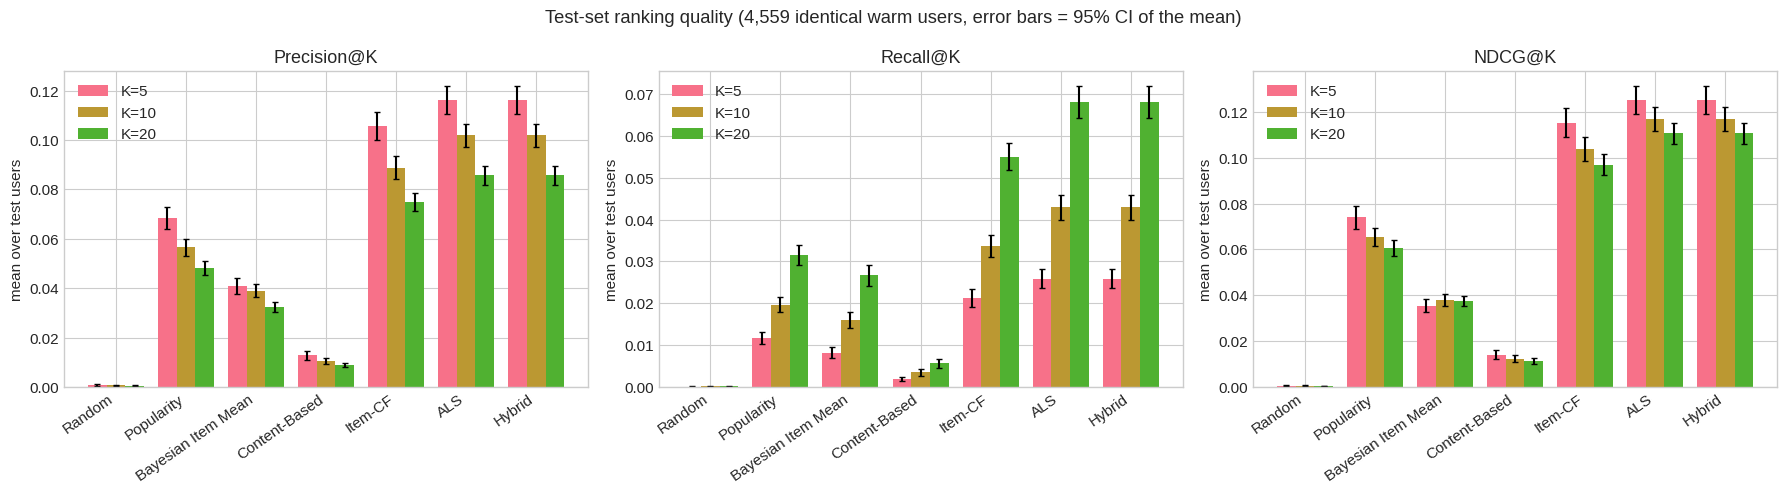

Observed: NDCG@10 ranking -> Hybrid 0.1168, ALS 0.1168, Item-CF 0.1037, Popularity 0.0654, Bayesian Item Mean 0.0378, Content-Based 0.0124, Random 0.0005


In [64]:
# 13.1  Model comparison on the test split (mean with 95% CI over users)
def save_fig(name):
    plt.tight_layout(); plt.savefig(FIGURES_DIR / name); plt.show()

models_order = list(RESULTS_TEST)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
width = 0.8 / len(K_VALUES)
for ax, metric, title in zip(axes, ['P', 'R', 'NDCG'], ['Precision@K', 'Recall@K', 'NDCG@K']):
    for j, k in enumerate(K_VALUES):
        means = [RESULTS_TEST[m]['per_user'][f'{metric}@{k}'].mean() for m in models_order]
        cis = [1.96 * RESULTS_TEST[m]['per_user'][f'{metric}@{k}'].std(ddof=1) / np.sqrt(len(RESULTS_TEST[m]['per_user'])) for m in models_order]
        ax.bar(np.arange(len(models_order)) + j * width, means, width, yerr=cis, capsize=2, label=f'K={k}')
    ax.set_xticks(np.arange(len(models_order)) + width); ax.set_xticklabels(models_order, rotation=35, ha='right')
    ax.set_title(title); ax.set_ylabel('mean over test users'); ax.legend()
fig.suptitle(f'Test-set ranking quality ({len(EVAL_USERS_TEST):,} identical warm users, error bars = 95% CI of the mean)')
save_fig('model_comparison_test.png')
ranked = test_summary['NDCG@10'].sort_values(ascending=False)
print("Observed: NDCG@10 ranking ->", ", ".join(f"{n} {v:.4f}" for n, v in ranked.items()))

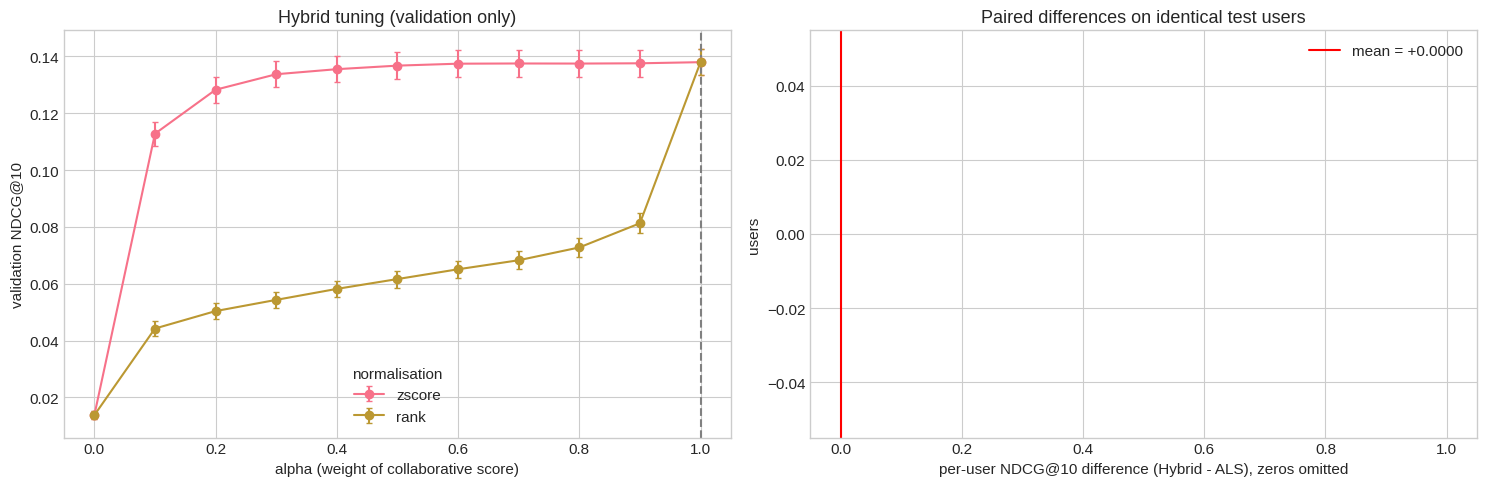

Observed: users with identical NDCG@10 under both models: 100.0%; mean diff +0.00000, 95% CI [+0.00000, +0.00000], Holm p = 1


In [65]:
# 13.2  Hybrid tuning surface and paired Hybrid-vs-ALS differences
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for m in HYBRID_NORMS:
    d = hybrid_tuning_df[hybrid_tuning_df['normalisation'] == m]
    axes[0].errorbar(d['alpha'], d['NDCG@10'], yerr=1.96 * d['NDCG@10_se'], marker='o', capsize=2, label=m)
axes[0].axvline(HYBRID_CONFIG['alpha'], ls='--', color='grey')
axes[0].set_xlabel('alpha (weight of collaborative score)'); axes[0].set_ylabel('validation NDCG@10'); axes[0].set_title('Hybrid tuning (validation only)'); axes[0].legend(title='normalisation')
d_users = RESULTS_TEST['Hybrid']['per_user']['NDCG@10'] - RESULTS_TEST['ALS']['per_user']['NDCG@10']
axes[1].hist(d_users[d_users != 0], bins=60); axes[1].axvline(d_users.mean(), color='red', label=f'mean = {d_users.mean():+.4f}')
axes[1].set_xlabel('per-user NDCG@10 difference (Hybrid - ALS), zeros omitted'); axes[1].set_ylabel('users'); axes[1].set_title('Paired differences on identical test users'); axes[1].legend()
save_fig('hybrid_tuning_and_paired_difference.png')
row = paired_df[(paired_df['A'] == 'Hybrid') & (paired_df['B'] == 'ALS') & (paired_df['metric'] == 'NDCG@10')].iloc[0]
print(f"Observed: users with identical NDCG@10 under both models: {(d_users == 0).mean():.1%}; mean diff {row['mean_diff']:+.5f}, "
      f"95% CI [{row['ci95_low']:+.5f}, {row['ci95_high']:+.5f}], Holm p = {row['holm_p']:.4g}")

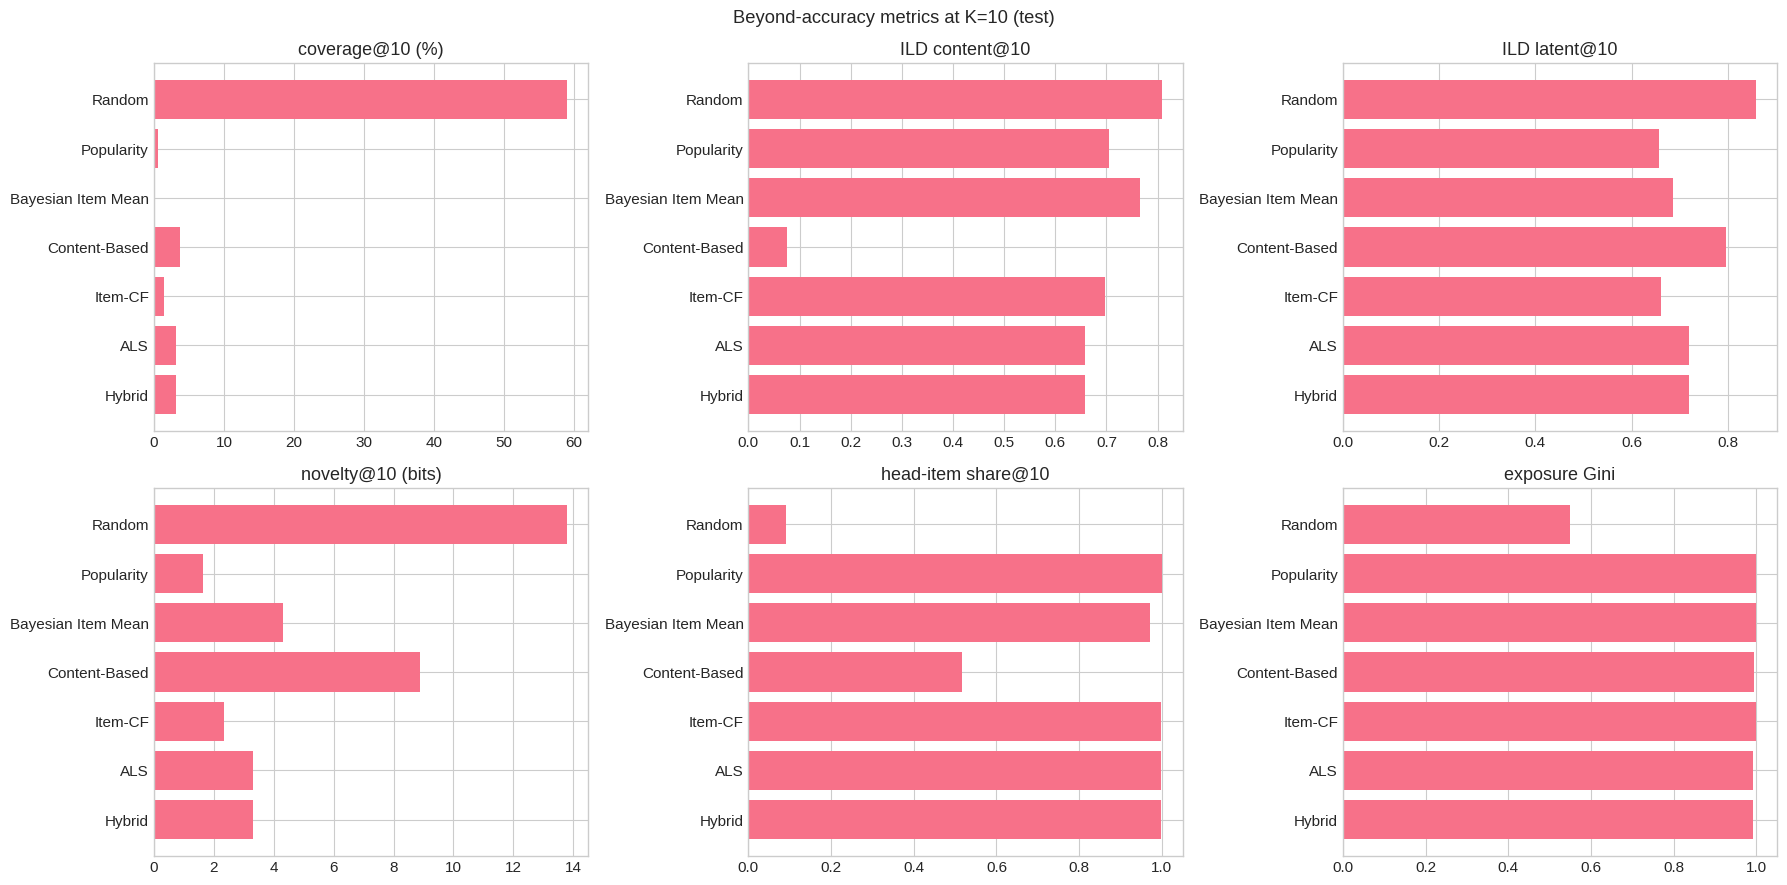

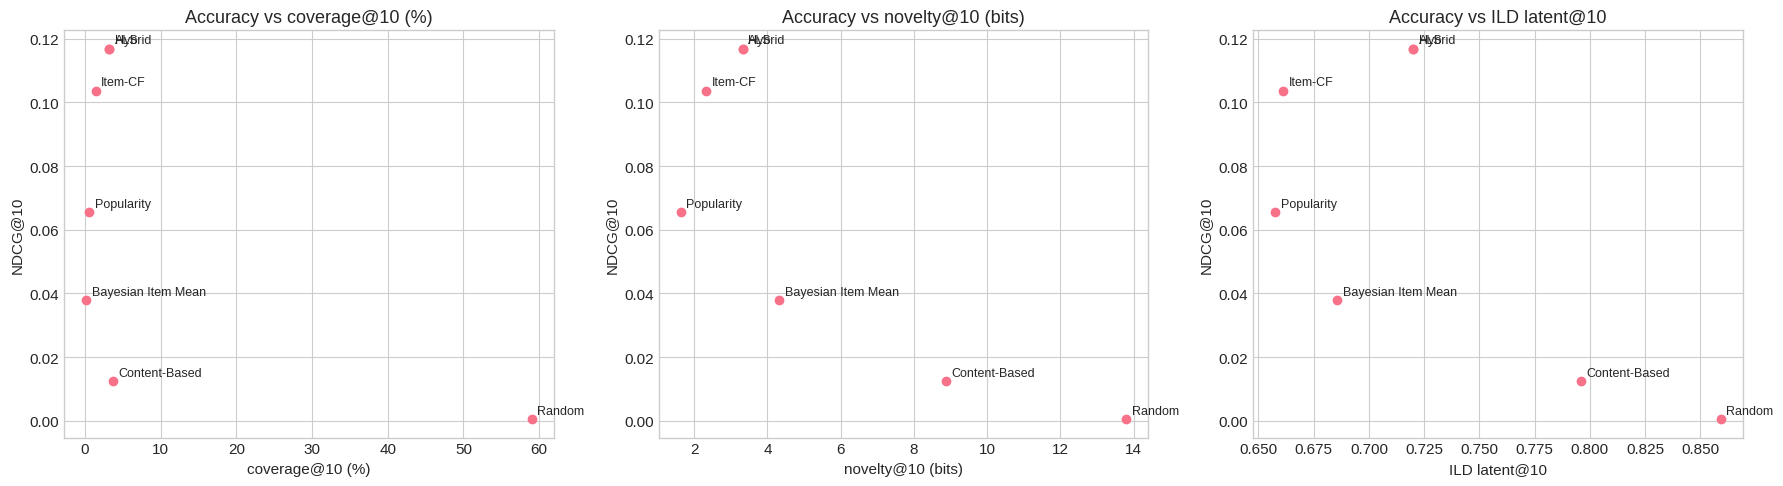

Observed: highest coverage@10 (%): Random (59.029); lowest: Bayesian Item Mean (0.173)
Observed: highest novelty@10 (bits): Random (13.799); lowest: Popularity (1.633)
Observed: highest head-item share@10: Popularity (1.000); lowest: Random (0.092)


In [66]:
# 13.3  Beyond-accuracy: coverage, diversity, novelty, popularity bias, and trade-off with accuracy
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), ['coverage@10 (%)', 'ILD content@10', 'ILD latent@10', 'novelty@10 (bits)', 'head-item share@10', 'exposure Gini']):
    ax.barh(test_beyond.index, test_beyond[col]); ax.set_title(col); ax.invert_yaxis()
fig.suptitle('Beyond-accuracy metrics at K=10 (test)')
save_fig('beyond_accuracy_test.png')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['coverage@10 (%)', 'novelty@10 (bits)', 'ILD latent@10']):
    ax.scatter(test_beyond[col], test_summary.loc[test_beyond.index, 'NDCG@10'])
    for n in test_beyond.index:
        ax.annotate(n, (test_beyond.loc[n, col], test_summary.loc[n, 'NDCG@10']), fontsize=9, xytext=(4, 4), textcoords='offset points')
    ax.set_xlabel(col); ax.set_ylabel('NDCG@10'); ax.set_title(f'Accuracy vs {col}')
save_fig('accuracy_vs_beyond_accuracy_tradeoff.png')
for col in ['coverage@10 (%)', 'novelty@10 (bits)', 'head-item share@10']:
    print(f"Observed: highest {col}: {test_beyond[col].idxmax()} ({test_beyond[col].max():.3f}); lowest: {test_beyond[col].idxmin()} ({test_beyond[col].min():.3f})")

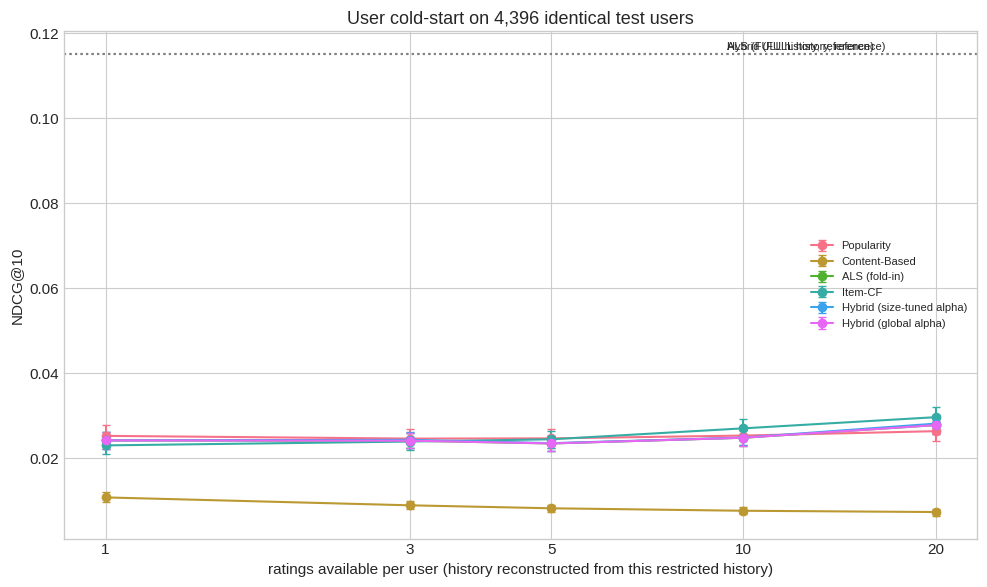

Observed: best model per history size -> n=1: Popularity (0.0253); n=3: Popularity (0.0247); n=5: Popularity (0.0247); n=10: Item-CF (0.0271); n=20: Item-CF (0.0297)


In [67]:
# 13.4  User cold-start curves (test) with full-history references
fig, ax = plt.subplots(figsize=(10, 6))
for m in ['Popularity', 'Content-Based', 'ALS (fold-in)', 'Item-CF', 'Hybrid (size-tuned alpha)', 'Hybrid (global alpha)']:
    d = cs_summary[cs_summary['model'] == m].sort_values('size')
    ax.errorbar(d['size'], d['NDCG10'], yerr=d['NDCG10_ci95'], marker='o', capsize=3, label=m)
for k, v in refs.items():
    if k.startswith(('ALS', 'Hybrid')):
        ax.axhline(v, ls=':', color='grey'); ax.annotate(k, (HISTORY_SIZES[-1], v), fontsize=8, xytext=(-150, 3), textcoords='offset points')
ax.set_xscale('log'); ax.set_xticks(HISTORY_SIZES); ax.set_xticklabels(HISTORY_SIZES)
ax.set_xlabel('ratings available per user (history reconstructed from this restricted history)'); ax.set_ylabel('NDCG@10')
ax.set_title(f'User cold-start on {len(cs_users_test):,} identical test users'); ax.legend(fontsize=8)
save_fig('user_cold_start_curves.png')
best_by_size = cs_summary.loc[cs_summary.groupby('size')['NDCG10'].idxmax(), ['size', 'model', 'NDCG10']]
print("Observed: best model per history size ->", "; ".join(f"n={r['size']}: {r['model']} ({r['NDCG10']:.4f})" for _, r in best_by_size.iterrows()))

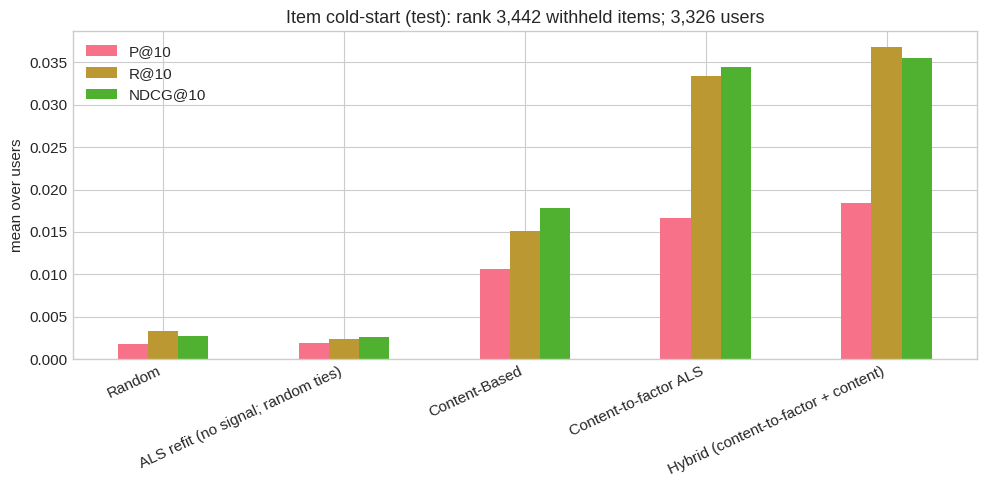

Observed: item cold-start NDCG@10 -> Hybrid (content-to-factor + content) 0.0355, Content-to-factor ALS 0.0344, Content-Based 0.0178, Random 0.0028, ALS refit (no signal; random ties) 0.0026


In [68]:
# 13.5  Item cold-start
fig, ax = plt.subplots(figsize=(10, 5))
ic_summary[['P@10', 'R@10', 'NDCG@10']].plot.bar(ax=ax); ax.set_xticklabels(ic_summary.index, rotation=25, ha='right')
ax.set_title(f'Item cold-start (test): rank {len(COLD_ITEMS):,} withheld items; {len(GT_COLD_TEST):,} users'); ax.set_ylabel('mean over users')
save_fig('item_cold_start_test.png')
print("Observed: item cold-start NDCG@10 ->", ", ".join(f"{n} {v:.4f}" for n, v in ic_summary['NDCG@10'].sort_values(ascending=False).items()))

---

## 14. Recommendation Demonstration

**These are qualitative demonstrations, not evaluation results.** They show the logic and output format of each recommender. Already-seen movies are excluded wherever a user history exists. Scores are model-specific and not comparable across models.

In [69]:
# 14.1  Movie-to-movie recommendations (three different notions of similarity)
def similar_by_itemcf(movie_id, n=5):
    if movie_id not in item_id_to_idx_train:
        return pd.DataFrame()
    row = ITEM_SIM[item_id_to_idx_train[movie_id]].toarray().ravel()
    top = np.argsort(-row)[:n]
    return pd.DataFrame({'title': [movie_title[TRAIN_ITEM_IDS[i]] for i in top], 'co-liking similarity': row[top]})

def similar_by_latent(movie_id, n=5):
    if movie_id not in item_id_to_idx_train:
        return pd.DataFrame()
    i = item_id_to_idx_train[movie_id]
    sims = ALS_STATE.item_factors_unit @ ALS_STATE.item_factors_unit[i]; sims[i] = -1
    top = np.argsort(-sims)[:n]
    return pd.DataFrame({'title': [movie_title[TRAIN_ITEM_IDS[j]] for j in top], 'latent cosine': sims[top]})

for mid in [1, 260, 296]:
    print(f"\n=== Query: {movie_title[mid]} [{movie_genres[mid]}] ===")
    print("-- Content (genres + historical tags): same-genre/tag films"); print(get_similar_movies(mid, 5)[['title', 'genres', 'similarity']].round(3).to_string(index=False))
    print("-- Item-CF: films liked by the same users");  print(similar_by_itemcf(mid).round(3).to_string(index=False))
    print("-- ALS latent space: films with similar taste factors"); print(similar_by_latent(mid).round(3).to_string(index=False))


=== Query: Toy Story (1995) [Adventure|Animation|Children|Comedy|Fantasy] ===
-- Content (genres + historical tags): same-genre/tag films
                                         title                                      genres  similarity
                      The Magic Crystal (2011) Adventure|Animation|Children|Comedy|Fantasy      1.0000
                       The Dragon Spell (2016) Adventure|Animation|Children|Comedy|Fantasy      1.0000
  Puss in Book: Trapped in an Epic Tale (2017) Adventure|Animation|Children|Comedy|Fantasy      1.0000
                   Here Comes the Grump (2018) Adventure|Animation|Children|Comedy|Fantasy      1.0000
Chickenhare and the Hamster of Darkness (2022) Adventure|Animation|Children|Comedy|Fantasy      1.0000
-- Item-CF: films liked by the same users
                                            title  co-liking similarity
                               Toy Story 2 (1999)                0.4930
        Star Wars: Episode IV - A New Hope (1977)        

In [70]:
# 14.2  Personalised recommendations with explanations for one warm test user
def pick_demo_user(min_hist=40):
    for uid in EVAL_USERS_TEST:
        if user_train_count[user_id_to_idx_train[uid]] >= min_hist:
            return uid
DEMO_UID = pick_demo_user()

def recommend_table(uid, hist_idx, hist_r, n=5, use_trained=True):
    u = user_id_to_idx_train[uid]
    ctx = {'uid': uid, 'u_idx': u if use_trained else None, 'hist_idx': hist_idx, 'hist_r': hist_r}
    cand = np.ones(N_ITEMS, dtype=bool); cand[hist_idx] = False
    cf, cb = component_scores(ctx, ALS_STATE, content_train_norm, use_trained)
    liked = hist_idx[hist_r >= RELEVANCE_THRESHOLD]
    liked = liked if len(liked) else hist_idx
    out = {}
    scorers = {'Content-Based': cb, 'ALS': cf if cf is not None else None, 'Item-CF': score_itemcf(ctx),
               'Hybrid': fuse(cf, cb, cand, HYBRID_CONFIG['alpha'], HYBRID_CONFIG['norm'], ALS_STATE.missing_items)}
    for name, s in scorers.items():
        if s is None:
            out[name] = pd.DataFrame({'note': ['no positive rating in this history: collaborative factor cannot be inferred']}); continue
        top = top_n_unseen(s, hist_idx, n)
        why = []
        for i in top:
            if name == 'Content-Based':
                sims = content_train_norm[liked].dot(content_train_norm[i].T).toarray().ravel(); why.append(f"similar to '{movie_title[TRAIN_ITEM_IDS[liked[sims.argmax()]]]}' (cos {sims.max():.2f})")
            elif name == 'Item-CF':
                sims = np.asarray(ITEM_SIM[liked][:, i].todense()).ravel(); why.append(f"liked together with '{movie_title[TRAIN_ITEM_IDS[liked[sims.argmax()]]]}'" if sims.max() > 0 else 'popularity tie-break')
            elif name == 'ALS':
                why.append('high match to inferred latent taste vector')
            else:
                why.append(f"CF z={normalise_scores(cf, cand, HYBRID_CONFIG['norm'], ALS_STATE.missing_items)[i]:.2f}, CB z={normalise_scores(cb, cand, HYBRID_CONFIG['norm'])[i]:.2f}" if cf is not None else 'content only (CF unavailable)')
        out[name] = pd.DataFrame({'title': [movie_title[TRAIN_ITEM_IDS[i]] for i in top], 'genres': [movie_genres[TRAIN_ITEM_IDS[i]] for i in top],
                                  'score': s[top], 'why': why})
    return out

u_, h_, r_ = get_history(DEMO_UID)
fav = h_[np.argsort(-r_)[:6]]
print(f"Demo user {DEMO_UID}: {len(h_)} training ratings. Top-rated history: {[movie_title[TRAIN_ITEM_IDS[i]] for i in fav]}")
for name, tbl in recommend_table(DEMO_UID, h_, r_).items():
    print(f"\n--- {name} (top-5, seen films excluded) ---"); print(tbl.round(3).to_string(index=False))
assert not (set(h_.tolist()) & set(top_n_unseen(score_content({'hist_idx': h_, 'hist_r': r_, 'uid': DEMO_UID}), h_, 20).tolist())), "seen item leaked"

Demo user 28: 2684 training ratings. Top-rated history: ['Blade Runner 2049 (2017)', 'The Martian (2015)', 'The Revenant (2015)', 'Beautiful Girls (1996)', 'Mad Max: Fury Road (2015)', 'Secret Life of Walter Mitty, The (2013)']

--- Content-Based (top-5, seen films excluded) ---
                             title       genres  score                                                  why
               Intouchables (2011) Comedy|Drama 0.8460 similar to 'Kicking and Screaming (1995)' (cos 1.00)
Madness of King George, The (1994) Comedy|Drama 0.8460 similar to 'Kicking and Screaming (1995)' (cos 1.00)
                Patch Adams (1998) Comedy|Drama 0.8460 similar to 'Kicking and Screaming (1995)' (cos 1.00)
             Big Chill, The (1983) Comedy|Drama 0.8460 similar to 'Kicking and Screaming (1995)' (cos 1.00)
                Being There (1979) Comedy|Drama 0.8460 similar to 'Kicking and Screaming (1995)' (cos 1.00)

--- ALS (top-5, seen films excluded) ---
                              

In [71]:
# 14.3  Limited-history recommendations (profile rebuilt from only n ratings; stored factor NOT used)
for n_keep in [3, 10]:
    sel = np.random.default_rng(RANDOM_SEED).choice(len(h_), size=n_keep, replace=False)
    print(f"\n##### Only {n_keep} ratings available: {[movie_title[TRAIN_ITEM_IDS[i]] + f' ({r})' for i, r in zip(h_[sel], r_[sel])]}")
    for name, tbl in recommend_table(DEMO_UID, h_[sel], r_[sel], use_trained=False).items():
        print(f"--- {name} ---"); print(tbl.drop(columns=['genres'], errors='ignore').round(3).to_string(index=False))


##### Only 3 ratings available: ['Catch Me If You Can (2002) (4.0)', 'Sliver (1993) (2.0)', 'DiG! (2004) (4.0)']
--- Content-Based ---
                                            title  score                                                why
Redemption: The Stan Tookie Williams Story (2004) 0.9860 similar to 'Catch Me If You Can (2002)' (cos 0.82)
                               The Keepers (2017) 0.9860 similar to 'Catch Me If You Can (2002)' (cos 0.82)
                          Bonnie and Clyde (2013) 0.9860 similar to 'Catch Me If You Can (2002)' (cos 0.82)
                                 Bananas!* (2009) 0.9860 similar to 'Catch Me If You Can (2002)' (cos 0.82)
                                The Family (2016) 0.9860 similar to 'Catch Me If You Can (2002)' (cos 0.82)
--- ALS ---
                       title  score                                        why
       Ocean's Eleven (2001) 0.2070 high match to inferred latent taste vector
    Beautiful Mind, A (2001) 0.2010 high match

In [72]:
# 14.4  Never-rated movies as candidates (DEMONSTRATION ONLY - no rating-based relevance exists for them)
# Uses the FULL-catalogue tag matrix (includes tags created after the training cutoff): this is the deliberately
# non-historical, deployment-style variant and is never used in any evaluation above.
never_rated = sorted(set(movies['movieId']) - set(ratings['movieId'].unique()))
content_full_norm = sk_normalize(content_matrix_full.astype(np.float32), norm='l2')
liked_ids = [TRAIN_ITEM_IDS[i] for i in h_[r_ >= RELEVANCE_THRESHOLD]]
prof = np.asarray(content_full_norm[[movie_id_to_idx[m] for m in liked_ids]].T.dot(r_[r_ >= RELEVANCE_THRESHOLD].astype(np.float32))).ravel()
rows_nr = np.array([movie_id_to_idx[m] for m in never_rated])
sc = content_full_norm[rows_nr].dot(prof) / (np.linalg.norm(prof) or 1.0)
top = np.argsort(-sc)[:5]
print(f"{len(never_rated):,} movies have no rating anywhere in MovieLens 32M. Top-5 content candidates for user {DEMO_UID}:")
print(pd.DataFrame({'title': [movie_title[never_rated[i]] for i in top], 'genres': [movie_genres[never_rated[i]] for i in top], 'content score': sc[top]}).round(3).to_string(index=False))

3,153 movies have no rating anywhere in MovieLens 32M. Top-5 content candidates for user 28:
                                            title       genres  content score
                            Alma's Rainbow (1994) Comedy|Drama         0.7700
                     The Blade of Don Juan (2013) Comedy|Drama         0.7700
Flatbed Annie & Sweetie Pie: Lady Truckers (1979) Comedy|Drama         0.7700
                                  Longshot (1981) Comedy|Drama         0.7700
                                    Ramiro (2018) Comedy|Drama         0.7700


---

## 15. Final Findings and Conclusion

The earlier conclusions asserted that the hybrid "substantially outperforms" collaborative filtering under cold-start, that content-based filtering "maintains consistent quality", and that diversity was not sacrificed. None of these were supported: the old cold-start experiment reused full-history ALS factors, no diversity metric existed, and the content model scored ~0.002 NDCG@10. They have been removed.

The cell below composes the answers to the seven research questions **directly from the stored result tables of the executed run**, including the statistical tests, so the text cannot drift from the evidence. The limitations that follow are properties of the design and hold regardless of the numbers.

In [73]:
# 15.1  Data-driven findings (generated from the executed results)
def fmt_p(p): return f"{p:.3g}"
lines = []
best = test_summary['NDCG@10'].idxmax()
lines.append(f"1. Best model by NDCG@10 on the test split ({len(EVAL_USERS_TEST):,} users): {best} ({test_summary.loc[best, 'NDCG@10']:.4f}). "
             "Ranking: " + ", ".join(f"{n} {v:.4f}" for n, v in test_summary['NDCG@10'].sort_values(ascending=False).items()) + ".")
r_h = paired_df[(paired_df['A'] == 'Hybrid') & (paired_df['B'] == 'ALS')].set_index('metric')
def verdict(r):
    ci0 = r['ci95_low'] <= 0 <= r['ci95_high']
    if ci0 or not r['significant (Holm, 0.05)']:
        return "not distinguishable from zero (CI includes 0 or Holm-adjusted p >= 0.05)"
    return ("statistically significant and practically meaningful (>= 2% relative)" if r['practically_meaningful']
            else "statistically significant but practically small (< 2% relative)") + (" in favour of the hybrid" if r['mean_diff'] > 0 else " in favour of ALS")
lines.append("2./3. Hybrid vs ALS on identical users: " + "; ".join(
    f"{m}: diff {r_h.loc[m, 'mean_diff']:+.5f} (95% CI [{r_h.loc[m, 'ci95_low']:+.5f}, {r_h.loc[m, 'ci95_high']:+.5f}]), rel {r_h.loc[m, 'relative_diff_%']:+.2f}%, "
    f"d_z {r_h.loc[m, 'cohens_dz']:+.3f}, Holm p {fmt_p(r_h.loc[m, 'holm_p'])} -> {verdict(r_h.loc[m])}" for m in ['NDCG@10', 'P@10', 'R@10']))
lines.append(f"   Selected hybrid configuration (validation): {HYBRID_CONFIG}; ALS configuration: factors={ALS_STATE.factors}, reg={ALS_STATE.reg}, alpha={ALS_STATE.alpha}.")
cs_pv = cs_paired[(cs_paired['A'] == 'Hybrid (size-tuned alpha)') & (cs_paired['B'] == 'ALS (fold-in)')]
lines.append("4. Limited user history (Hybrid size-tuned vs ALS fold-in, NDCG@10): " + "; ".join(
    f"n={int(r['size'])}: {r['mean_diff']:+.4f} [{r['ci95_low']:+.4f}, {r['ci95_high']:+.4f}] ({'significant' if r['significant (Holm, 0.05)'] else 'n.s.'}, Holm p {fmt_p(r['holm_p'])})" for _, r in cs_pv.iterrows())
             + f". Best model per size: " + "; ".join(f"n={r['size']}: {r['model']}" for _, r in best_by_size.iterrows())
             + f". Draws with no positive rating (ALS fold-in impossible): {({k: round(v, 3) for k, v in cs_test_unavail.items()})}.")
lines.append("5. Item cold-start (NDCG@10): " + ", ".join(f"{n} {v:.4f}" for n, v in ic_summary['NDCG@10'].sort_values(ascending=False).items())
             + f". Content-Based vs Random: diff {ic_paired.iloc[0]['mean_diff']:+.4f} [{ic_paired.iloc[0]['ci95_low']:+.4f}, {ic_paired.iloc[0]['ci95_high']:+.4f}], Holm p {fmt_p(ic_paired.iloc[0]['holm_p'])}.")
lines.append("6. Trade-offs (K=10): " + "; ".join(f"{n}: NDCG {test_summary.loc[n, 'NDCG@10']:.3f}, coverage {test_beyond.loc[n, 'coverage@10 (%)']:.1f}%, ILD(content) {test_beyond.loc[n, 'ILD content@10']:.3f}, "
                                             f"novelty {test_beyond.loc[n, 'novelty@10 (bits)']:.2f} bits, head share {test_beyond.loc[n, 'head-item share@10']:.2f}" for n in test_beyond.index))
n_all_test_users = len(test_ground_truth_all)
lines.append(f"7. Evaluation scope: {len(EVAL_USERS_TEST):,} of {n_all_test_users:,} test users with relevant items ({100*len(EVAL_USERS_TEST)/n_all_test_users:.1f}%) have training history; "
             f"{test_log['pct_relevant_unreachable'].iloc[0]:.1f}% of their relevant items are outside the training catalogue and unreachable for every model.")
print("\n\n".join(lines))
(EVAL_DIR / 'final_findings.txt').write_text("\n\n".join(lines))

1. Best model by NDCG@10 on the test split (4,559 users): ALS (0.1168). Ranking: Hybrid 0.1168, ALS 0.1168, Item-CF 0.1037, Popularity 0.0654, Bayesian Item Mean 0.0378, Content-Based 0.0124, Random 0.0005.

2./3. Hybrid vs ALS on identical users: NDCG@10: diff +0.00000 (95% CI [+0.00000, +0.00000]), rel +0.00%, d_z +0.000, Holm p 1 -> not distinguishable from zero (CI includes 0 or Holm-adjusted p >= 0.05); P@10: diff +0.00000 (95% CI [+0.00000, +0.00000]), rel +0.00%, d_z +0.000, Holm p 1 -> not distinguishable from zero (CI includes 0 or Holm-adjusted p >= 0.05); R@10: diff +0.00000 (95% CI [+0.00000, +0.00000]), rel +0.00%, d_z +0.000, Holm p 1 -> not distinguishable from zero (CI includes 0 or Holm-adjusted p >= 0.05)

   Selected hybrid configuration (validation): {'alpha': 1.0, 'norm': 'zscore'}; ALS configuration: factors=64, reg=0.05, alpha=1.0.

4. Limited user history (Hybrid size-tuned vs ALS fold-in, NDCG@10): n=1: +0.0000 [+0.0000, +0.0000] (n.s., Holm p 1); n=3: +0.0002 

2549

### 15.2 Limitations (Design Properties)

* **Offline, proxy relevance.** Relevance is `rating >= 4.0` on logged data; it is an experimental definition, not user satisfaction, and ignores that users only rate what they chose to watch (exposure bias).
* **Warm users only in the primary benchmark.** Most test-period users have *no* training history; they are the real cold-start population and can only be served by popularity or onboarding. Warm-user results do not describe them.
* **Unreachable relevant items.** A large share of relevant test items did not exist in the training catalogue; no model trained on historical data can retrieve them. They stay in the Recall/NDCG denominators.
* **Temporal gap.** Profiles end at the training cutoff although test ratings fall up to five years later; interests and popularity drift. The test models were not refitted on train+validation.
* **Positive-only ALS.** Ratings below 4.0 are treated as unobserved, not as dislikes; a model of explicit negative feedback might change the ranking.
* **Fold-in and neighbour approximations.** Item-CF keeps only the top-100 neighbours per item; ALS training uses a conjugate-gradient solver, so fold-in reproduces trained factors only approximately (checked in 9.2).
* **Beyond-accuracy metrics are representation-dependent.** Content-space diversity favours the content model; latent-space diversity is reported as a counterweight.
* **Item cold-start is simulated.** Withheld items are *previously rated* movies; behaviour on truly new releases may differ. Never-rated movies are only demonstrated.
* **Single temporal split.** Results come from one chronological split; conclusions about other periods are not implied.

In [74]:
# 15.3  Reproducibility record
import platform, sklearn
from datetime import timezone
run_config = {
    'timestamp_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'), 'python': platform.python_version(),
    'numpy': np.__version__, 'pandas': pd.__version__, 'scipy': __import__('scipy').__version__, 'sklearn': sklearn.__version__, 'implicit': implicit.__version__,
    'seed': RANDOM_SEED, 'relevance_threshold': RELEVANCE_THRESHOLD, 'k_values': K_VALUES,
    'train_cutoff_ts': float(train_cutoff_ts), 'val_cutoff_ts': float(val_cutoff_ts),
    'als': {'factors': ALS_STATE.factors, 'reg': ALS_STATE.reg, 'alpha': ALS_STATE.alpha, 'iterations': ALS_ITERATIONS},
    'item_cf': {'k': ITEMCF_K, 'shrink': ITEMCF_SHRINK}, 'content_tag_weight': CB_TAG_WEIGHT, 'bayes_m': BAYES_M,
    'hybrid': HYBRID_CONFIG, 'cold_alpha_by_size': ALPHA_BY_SIZE, 'item_cold': {'frac': ITEM_COLD_FRAC, 'ridge_alpha': RIDGE_BEST, 'alpha': IC_ALPHA},
    'n_test_users': len(EVAL_USERS_TEST), 'n_val_users': len(EVAL_USERS_VAL),
}
(PROJECT_ROOT / 'outputs' / 'run_config.json').write_text(json.dumps(run_config, indent=2, default=str))
print(json.dumps(run_config, indent=2, default=str))

{
  "timestamp_utc": "2026-11-14T19:28:35+00:00",
  "python": "3.13.18",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scipy": "1.16.3",
  "sklearn": "1.6.1",
  "implicit": "0.7.3",
  "seed": 42,
  "relevance_threshold": 4.0,
  "k_values": [
    5,
    10,
    20
  ],
  "train_cutoff_ts": 1538551302.0,
  "val_cutoff_ts": 1604605534.4,
  "als": {
    "factors": 64,
    "reg": 0.05,
    "alpha": 1.0,
    "iterations": 15
  },
  "item_cf": {
    "k": 100,
    "shrink": 10.0
  },
  "content_tag_weight": 0.0,
  "bayes_m": 50,
  "hybrid": {
    "alpha": 1.0,
    "norm": "zscore"
  },
  "cold_alpha_by_size": {
    "1": 1.0,
    "3": 0.8,
    "5": 0.6,
    "10": 0.6,
    "20": 0.4
  },
  "item_cold": {
    "frac": 0.2,
    "ridge_alpha": 1.0,
    "alpha": 0.6
  },
  "n_test_users": 4559,
  "n_val_users": 6544
}
